<a href="https://colab.research.google.com/github/Svlsqz/Tomosar/blob/main/TomoSAR_PIXEL_v2_copia_para_revisi%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# LIBRERÍAS Y PARÁMETROS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from scipy.signal import find_peaks
from pathlib import Path
import pandas as pd

# PRIMERA PRUEBA


## DEFINIENDO LA GEOMETRÍA

In [ ]:
# ============================================================
# PARÁMETROS DEL SISTEMA TOMOSAR
# ============================================================

# ------------------------------------------------------------
# MODELO FÍSICO SIMPLIFICADO
# ------------------------------------------------------------
#
# El número de onda vertical (vertical wavenumber) es:
#
#             4*pi*b_n
# k_z,n = -------------------
#             lambda * R
#
# donde:
#
# lambda : longitud de onda
# b_n    : baseline perpendicular de la adquisición n
# R      : distancia slant-range al objetivo
#
# El steering vector para una altura s es:
#
# a_n(s) = exp(-j * k_z,n * s)

# ============================================================
# PARÁMETROS FÍSICOS
# ============================================================

wavelength = 0.03       # Longitud de onda [m] - X band
r_slant = 10000.0       # Distancia radar-target [m]

N = 8                   # Número de adquisiciones / tracks

# ============================================================
# BASELINES
# ============================================================

# Baselines NO uniformes.
b_n = np.array([-45,-32,-21,-8,0,13,27,46], dtype=float)

# ============================================================
# GRID DE ALTURA
# ============================================================

# Alturas que intentaremos reconstruir.
# En este ejemplo: -10 m ---------------- 50 m
# con 501 bins.

L = 501
s = np.linspace(-10,50,L)

# ============================================================
# INFORMACIÓN
# ============================================================

print("============================================")
print("PARÁMETROS TOMOSAR")
print("============================================")

print(f"Longitud de onda       : {wavelength:.4f} m")
print(f"Slant range            : {r_slant:.1f} m")
print(f"Número de adquisiciones: {N}")
print(f"Número de bins altura  : {L}")

print("\nBaselines [m]:")
print(b_n)

print("\nRango de alturas:")
print(f"{s.min():.1f} m → {s.max():.1f} m")

PARÁMETROS TOMOSAR
Longitud de onda       : 0.0300 m
Slant range            : 10000.0 m
Número de adquisiciones: 8
Número de bins altura  : 501

Baselines [m]:
[-45. -32. -21.  -8.   0.  13.  27.  46.]

Rango de alturas:
-10.0 m → 50.0 m


In [ ]:
# ============================================================
# ESCENA SINTÉTICA TOMOSAR
# ============================================================

# ------------------------------------------------------------
# MODELO DE LA ESCENA
# ------------------------------------------------------------
#
# Representamos la reflectividad compleja como:
#
# gamma(s) = gamma_suelo(s) + gamma_vegetacion(s) + gamma_montana(s)
#
# La potencia de la escena es:
#
# P_gamma(s) = |gamma(s)|^2
#
# IMPORTANTE:
# gamma       -> reflectividad COMPLEJA
# |gamma|     -> amplitud
# |gamma|^2   -> potencia

# ============================================================
# FUNCION AUXILIAR
# ============================================================

# Distribución gaussiana: Se utiliza para representar una contribución
# distribuida alrededor de una determinada altura.

def gaussian(x, mu, sigma):
    return np.exp(-0.5 * ((x - mu) / sigma) ** 2)

# ============================================================
# INICIALIZAR COMPONENTES
# ============================================================

gamma_suelo = np.zeros(L, dtype=complex)
gamma_vegetacion = np.zeros(L, dtype=complex)
gamma_montana = np.zeros(L, dtype=complex)

# ============================================================
# 1. SUELO
# ============================================================

# El suelo se modela como una superficie relativamente
# compacta alrededor de 0 m.

gamma_suelo = (1.0 * gaussian(s, mu=0.0, sigma=0.7) * np.exp(1j * 0.0))

# ============================================================
# 2. VEGETACIÓN
# ============================================================

# La vegetación ocupa un intervalo vertical.
# En este ejemplo: 4 m  → 25 m
# La reflectividad disminuye progresivamente con la altura.

mask_vegetacion = ((s >= 4.0) & (s <= 25.0))
vegetacion_amplitud = np.zeros(L)
vegetacion_amplitud[mask_vegetacion] = (0.75 * np.exp(
                                        -(s[mask_vegetacion] - 4.0) / 15.0))

# Para representar la naturaleza distribuida de la vegetación,
# asignamos fases diferentes a las diferentes alturas.
np.random.seed(10)
fase_vegetacion = np.random.uniform(-np.pi, np.pi, np.sum(mask_vegetacion))
gamma_vegetacion[mask_vegetacion] = (vegetacion_amplitud[mask_vegetacion]
                                    * np.exp(1j * fase_vegetacion))

# ============================================================
# 3. MONTAÑA / ESTRUCTURA
# ============================================================

# Se representa mediante una distribución alrededor de 35 m.

# En esta primera simulación no estamos simulando la geometría
# completa de una montaña 3D, sino su firma vertical dentro
# de nuestro pixel.

gamma_montana = (0.9 * gaussian(s, mu=35.0, sigma=2.0) * np.exp(1j * np.pi / 6))

# ============================================================
# REFLECTIVIDAD TOTAL
# ============================================================

gamma = (gamma_suelo + gamma_vegetacion + gamma_montana)

# ============================================================
# NORMALIZACIÓN
# ============================================================

gamma = (gamma / np.max(np.abs(gamma)))

# También normalizamos las componentes de manera consistente
# para facilitar la comparación visual.

gamma_suelo /= np.max(np.abs(gamma))
gamma_vegetacion /= np.max(np.abs(gamma))
gamma_montana /= np.max(np.abs(gamma))

# ============================================================
# INFORMACIÓN
# ============================================================

print("============================================")
print("ESCENA SINTÉTICA")
print("============================================")
print("Componentes:")
print("  - Suelo")
print("  - Vegetación")
print("  - Montaña / estructura")

print("\nAltura del suelo       : ~0 m")
print("Vegetación             : 4 - 25 m")
print("Centro montaña         : ~35 m")

ESCENA SINTÉTICA
Componentes:
  - Suelo
  - Vegetación
  - Montaña / estructura

Altura del suelo       : ~0 m
Vegetación             : 4 - 25 m
Centro montaña         : ~35 m


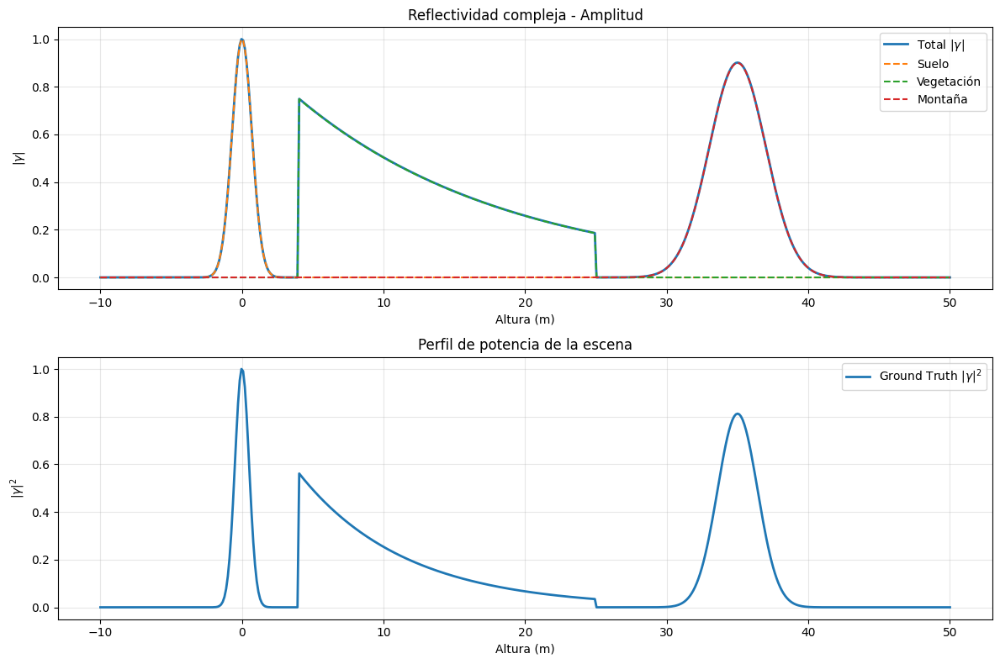

In [ ]:
# ============================================================
# VISUALIZACIÓN DE LA ESCENA
# ============================================================

# ------------------------------------------------------------
# DEFINICIONES
# ------------------------------------------------------------
#
# Reflectividad compleja:
#
#       gamma(s)
#
# Amplitud:
#
#       A(s) = |gamma(s)|
#
# Potencia:
#
#       P(s) = |gamma(s)|^2
#
# ------------------------------------------------------------

P_gamma = np.abs(gamma) ** 2

# Normalizar potencia
P_gamma /= np.max(P_gamma)

# Potencia de cada componente
P_suelo = np.abs(gamma_suelo) ** 2
P_vegetacion = np.abs(gamma_vegetacion) ** 2
P_montana = np.abs(gamma_montana) ** 2

# ============================================================
# FIGURA
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# ------------------------------------------------------------
# AMPLITUD
# ------------------------------------------------------------

axes[0].plot(s, np.abs(gamma), linewidth=2, label=r"Total $|\gamma|$")
axes[0].plot(s, np.abs(gamma_suelo), "--", label="Suelo")
axes[0].plot(s, np.abs(gamma_vegetacion), "--", label="Vegetación")
axes[0].plot(s, np.abs(gamma_montana), "--", label="Montaña")
axes[0].set_title("Reflectividad compleja - Amplitud")
axes[0].set_xlabel("Altura (m)")
axes[0].set_ylabel(r"$|\gamma|$")
axes[0].grid(True,alpha=0.3)
axes[0].legend()

# ------------------------------------------------------------
# POTENCIA
# ------------------------------------------------------------

axes[1].plot(s, P_gamma, linewidth=2, label=r"Ground Truth $|\gamma|^2$")
axes[1].set_title("Perfil de potencia de la escena")
axes[1].set_xlabel("Altura (m)")
axes[1].set_ylabel(r"$|\gamma|^2$")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

MATRIZ DE OBSERVACIÓN
Dimensiones de R: (8, 501)

k_z [rad/m]:
[-1.88495559 -1.34041287 -0.87964594 -0.33510322  0.          0.54454273
  1.13097336  1.92684349]


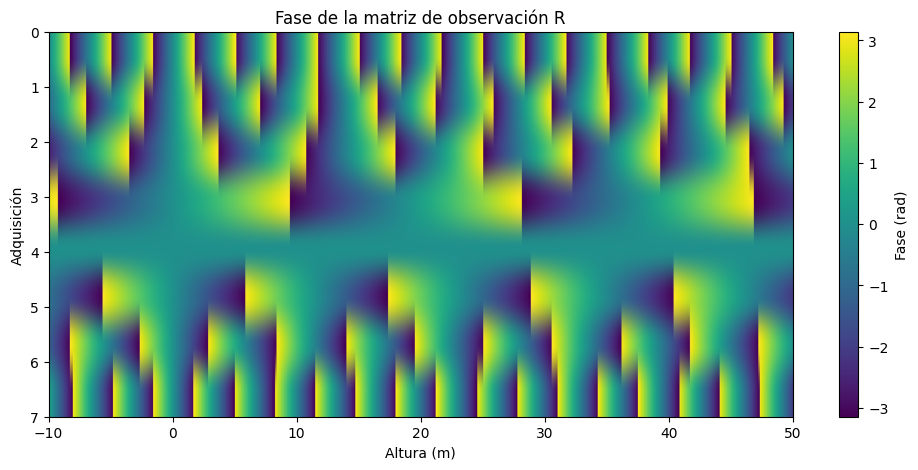

In [ ]:
# ============================================================
# MATRIZ DE OBSERVACIÓN / STEERING
# ============================================================

# ------------------------------------------------------------
# MODELO TOMOSAR
# ------------------------------------------------------------
#
# Para cada adquisición n:
#
#             4*pi*b_n
# k_z,n = -------------------
#             lambda * R
#
# El steering vector asociado a una altura s_l es:
#
# a(s_l) = [ exp(-j*k_z,1*s_l) ]
#          [ exp(-j*k_z,2*s_l) ]
#          [       ...         ]
#          [ exp(-j*k_z,N*s_l) ]
#
# Por tanto: R[n,l] = exp(-j*k_z,n*s_l)
# y la matriz completa tiene dimensiones:N x L
#
#            R ∈ C^(N x L)
#
# ------------------------------------------------------------

R = np.zeros((N, L), dtype=complex)

# Número de onda vertical para cada baseline
kz = (4 * np.pi * b_n / (wavelength * r_slant))

# Construir matriz R
for n in range(N):
    R[n, :] = np.exp(-1j * kz[n] * s)

# ============================================================
# INFORMACIÓN
# ============================================================

print("============================================")
print("MATRIZ DE OBSERVACIÓN")
print("============================================")
print("Dimensiones de R:", R.shape)
print("\nk_z [rad/m]:")
print(kz)
# ============================================================
# VISUALIZACIÓN DE LA FASE DE R
# ============================================================

plt.figure(figsize=(12, 5))
plt.imshow(np.angle(R), aspect="auto", extent=[s.min(), s.max(), N - 1, 0])
plt.colorbar(label="Fase (rad)")
plt.xlabel("Altura (m)")
plt.ylabel("Adquisición")
plt.title("Fase de la matriz de observación R")
plt.show()

In [ ]:
# ============================================================
# FORWARD MODEL / GENERACIÓN DE LAS OBSERVACIONES
# ============================================================

# ------------------------------------------------------------
# MODELO FORWARD TOMOSAR
# ------------------------------------------------------------
#
# El modelo lineal es:
#
#                 g = R * gamma + n
#
# donde:
# g      -> vector de observaciones SAR
# R      -> matriz de steering
# gamma  -> reflectividad en altura
# n      -> ruido
#
# En esta primera simulación: n = 0
# por lo tanto: g = R * gamma

# ============================================================
# GENERAR OBSERVACIONES SIN RUIDO
# ============================================================

g = R @ gamma

# ============================================================
# INFORMACIÓN
# ============================================================

print("============================================")
print("FORWARD MODEL")
print("============================================")
print("Dimensión de gamma:", gamma.shape)
print("Dimensión de R    :", R.shape)
print("Dimensión de g    :", g.shape)

# Ver observaciones complejas
print("\nObservaciones g:")

for n in range(N):
    print(
        f"Track {n+1}: "
        f"{g[n].real:+.5f} "
        f"{g[n].imag:+.5f}j"
    )

FORWARD MODEL
Dimensión de gamma: (501,)
Dimensión de R    : (8, 501)
Dimensión de g    : (8,)

Observaciones g:
Track 1: +8.76263 +3.90656j
Track 2: +2.95361 -3.63238j
Track 3: +27.61651 +1.42053j
Track 4: +36.00234 -10.72769j
Track 5: +52.29116 +19.88691j
Track 6: +31.36956 +3.00266j
Track 7: +10.86401 -6.27063j
Track 8: +9.93906 -2.92466j


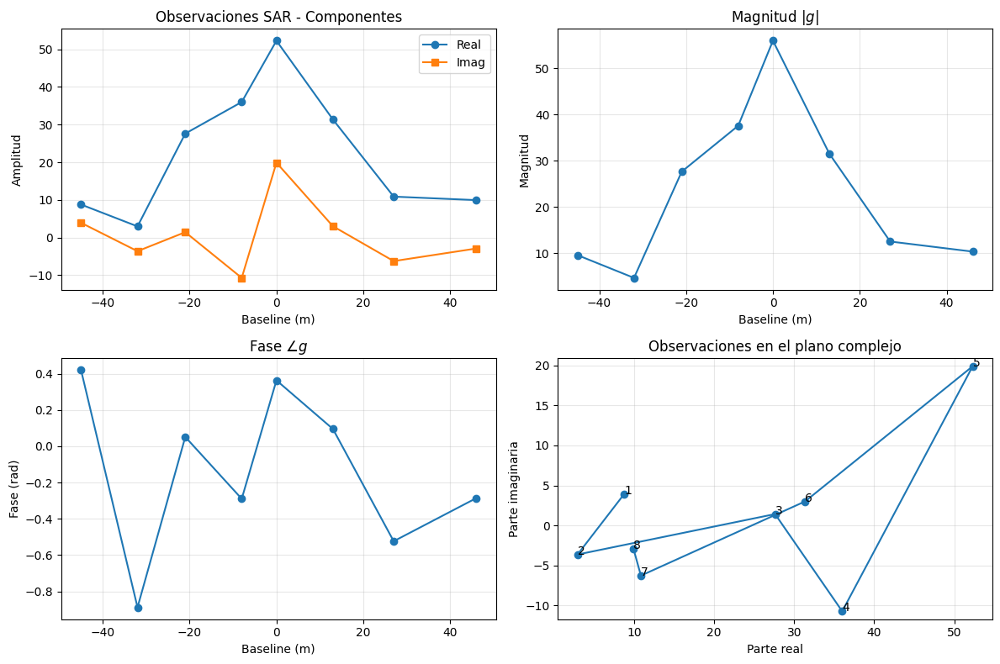

In [ ]:
# ============================================================
# VISUALIZACIÓN DE LAS OBSERVACIONES SAR
# ============================================================

# ------------------------------------------------------------
# g contiene una observación compleja por adquisición:
#
#       g_n = Re(g_n) + j Im(g_n)
#
# Su magnitud es: |g_n| y su fase: angle(g_n)
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# ============================================================
# 1. PARTE REAL E IMAGINARIA
# ============================================================

axes[0, 0].plot(b_n, np.real(g), "o-", label="Real")
axes[0, 0].plot(b_n, np.imag(g), "s-", label="Imag")
axes[0, 0].set_title("Observaciones SAR - Componentes")
axes[0, 0].set_xlabel("Baseline (m)")
axes[0, 0].set_ylabel("Amplitud")
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].legend()

# ============================================================
# 2. MAGNITUD
# ============================================================

axes[0, 1].plot(b_n, np.abs(g),"o-")
axes[0, 1].set_title(r"Magnitud $|g|$")
axes[0, 1].set_xlabel("Baseline (m)")
axes[0, 1].set_ylabel("Magnitud")
axes[0, 1].grid(True, alpha=0.3)

# ============================================================
# 3. FASE
# ============================================================

axes[1, 0].plot(b_n, np.angle(g), "o-")
axes[1, 0].set_title(r"Fase $\angle g$")
axes[1, 0].set_xlabel("Baseline (m)")
axes[1, 0].set_ylabel("Fase (rad)")
axes[1, 0].grid(True, alpha=0.3)

# ============================================================
# 4. PLANO COMPLEJO
# ============================================================

axes[1, 1].plot(np.real(g), np.imag(g), "o-")
axes[1, 1].set_title("Observaciones en el plano complejo")
axes[1, 1].set_xlabel("Parte real")
axes[1, 1].set_ylabel("Parte imaginaria")
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].axis("equal")

# Anotar cada adquisición
for n in range(N):
    axes[1, 1].annotate(f"{n+1}", (np.real(g[n]), np.imag(g[n])))

plt.tight_layout()
plt.show()

> Beamforming:

BEAMFORMING
Picos detectados:
Altura =   -8.68 m | Potencia = 0.335
Altura =    0.08 m | Potencia = 1.000
Altura =   13.28 m | Potencia = 0.822
Altura =   22.52 m | Potencia = 0.512
Altura =   35.96 m | Potencia = 0.728
Altura =   49.64 m | Potencia = 0.489


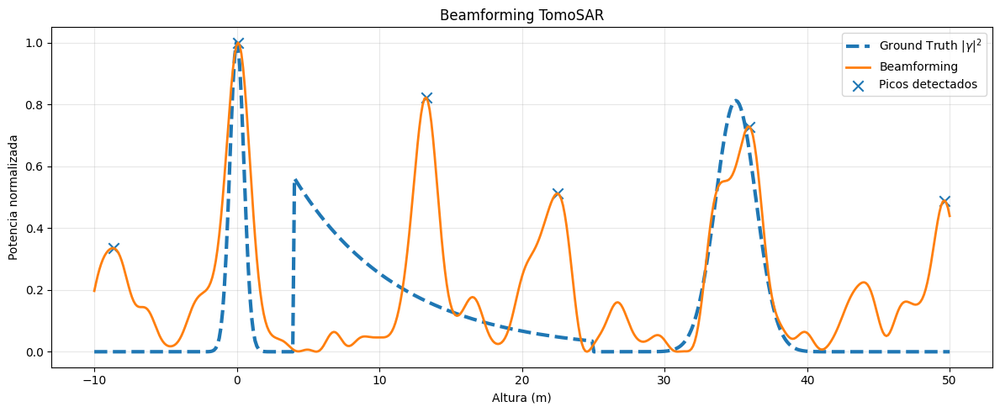

In [ ]:
# ------------------------------------------------------------
# BEAMFORMING / MATCHED FILTER
# ------------------------------------------------------------
#
# Para cada altura candidata s_l se calcula:
#
#                  H
# P(s_l) = | a(s_l) * g |^2
#
# donde:
# a(s_l) -> steering vector de la altura s_l
# g      -> observaciones SAR
#
# Equivalentemente:
#
# P(s_l) = | sum_n conj(R[n,l]) * g[n] |^2
#
# Normalización:
#
# P_norm(s_l) = P(s_l) / max(P)
#
# IMPORTANTE:
#
# Beamforming NO recupera exactamente |gamma|².
#
# El resultado está afectado por la respuesta de la apertura,
# incluyendo el lóbulo principal y lóbulos laterales.
#
# ------------------------------------------------------------

P_beamforming = np.zeros(L)

# ============================================================
# CALCULAR ESPECTRO TOMOGRÁFICO
# ============================================================

for l in range(L):

    # Steering vector para la altura actual
    a_l = R[:, l]

    # Producto interno complejo: a_l^H g
    projection = np.vdot(a_l, g)

    # Potencia
    P_beamforming[l] = (np.abs(projection) ** 2)

# ============================================================
# NORMALIZACIÓN
# ============================================================

P_beamforming /= np.max(P_beamforming)

# ============================================================
# DETECCIÓN DE PICOS
# ============================================================

peaks_beamforming, properties = find_peaks(
    P_beamforming, height=0.30, distance=5)

# ============================================================
# RESULTADOS
# ============================================================

print("============================================")
print("BEAMFORMING")
print("============================================")

print("Picos detectados:")

for idx in peaks_beamforming:
    print(f"Altura = {s[idx]:7.2f} m | "
          f"Potencia = {P_beamforming[idx]:.3f}")

# ============================================================
# VISUALIZACIÓN
# ============================================================

plt.figure(figsize=(12, 5))
plt.plot(s, P_gamma, "--", linewidth=3, label=r"Ground Truth $|\gamma|^2$")
plt.plot(s, P_beamforming, linewidth=2, label="Beamforming")

# Marcar picos
plt.scatter(s[peaks_beamforming], P_beamforming[peaks_beamforming], marker="x",
            s=80,label="Picos detectados")
plt.xlabel("Altura (m)")
plt.ylabel("Potencia normalizada")
plt.title("Beamforming TomoSAR")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

> CS - FISTA

In [ ]:
# ============================================================
# CS-FISTA
# ============================================================

# ------------------------------------------------------------
# COMPRESSED SENSING / FISTA
# ------------------------------------------------------------
# Queremos resolver:
#
# gamma_hat = argmin_gamma 1/2 ||g - R*gamma||_2^2 + lambda ||gamma||_1
#
# El primer término obliga a que la solución explique
# las observaciones:
#
#       R*gamma ≈ g
#
# El segundo término favorece soluciones dispersas:
#
#       ||gamma||_1
#
# ------------------------------------------------------------
# GRADIENTE
# ------------------------------------------------------------
# Para:
#
#       f(gamma) = 1/2 ||g - R*gamma||²
#
# el gradiente es:
#
#       ∇f = R^H (R*gamma - g)
#
# ------------------------------------------------------------
# CONSTANTE DE LIPSCHITZ
# ------------------------------------------------------------
#
#       L_f = ||R^H R||_2
#
# que equivalentemente puede calcularse como:
#
#       L_f = ||R||_2²
#
# ------------------------------------------------------------
# PASO DE GRADIENTE
# ------------------------------------------------------------
#
#       z = y - (1/L_f) ∇f(y)
#
# ------------------------------------------------------------
# SOFT THRESHOLDING COMPLEJO
# ------------------------------------------------------------
#
# Para un número complejo z:
#
#       S_tau(z) = max(1 - tau/|z|, 0) * z
#
# ------------------------------------------------------------
# ACTUALIZACIÓN FISTA
# ------------------------------------------------------------
#
# t_{k+1} = (1 + sqrt(1 + 4*t_k²)) / 2
# y_{k+1} = gamma_{k+1} + ((t_k - 1)/t_{k+1})(gamma_{k+1} - gamma_k)
#
# ------------------------------------------------------------

def soft_threshold_complex(x, threshold):
    magnitude = np.abs(x)
    scale = np.maximum(1.0 - threshold / (magnitude + 1e-12), 0.0)
    return scale * x

def fista_tomosar(R, g, lambda_reg=0.01, max_iter=2000, tol=1e-7):

    N, L = R.shape

    # --------------------------------------------------------
    # CONSTANTE DE LIPSCHITZ
    # --------------------------------------------------------

    lipschitz = (np.linalg.norm(R, 2) ** 2)

    # --------------------------------------------------------
    # INICIALIZACIÓN
    # --------------------------------------------------------

    x = np.zeros(L, dtype=complex)
    y = x.copy()
    t = 1.0

    # --------------------------------------------------------
    # ITERACIONES FISTA
    # --------------------------------------------------------

    for iteration in range(max_iter):
        x_old = x.copy()

        # ----------------------------------------------------
        # GRADIENTE
        # ----------------------------------------------------

        gradient = (R.conj().T @ (R @ y - g))

        # ----------------------------------------------------
        # PASO DE GRADIENTE
        # ----------------------------------------------------

        z = (y - gradient / lipschitz)

        # ----------------------------------------------------
        # OPERADOR PROXIMAL
        # ----------------------------------------------------

        x = soft_threshold_complex(z, lambda_reg / lipschitz)

        # ----------------------------------------------------
        # ACTUALIZACIÓN DE t
        # ----------------------------------------------------

        t_new = (1.0 + np.sqrt(1.0 + 4.0 * t**2)) / 2.0

        # ----------------------------------------------------
        # ACTUALIZACIÓN ACELERADA
        # ----------------------------------------------------

        y = (x + ((t - 1.0) / t_new) * (x - x_old))
        t = t_new

        # ----------------------------------------------------
        # CRITERIO DE CONVERGENCIA
        # ----------------------------------------------------

        error = (np.linalg.norm(x - x_old) / (np.linalg.norm(x_old) + 1e-12))
        if error < tol:
            print(f"FISTA convergió en {iteration + 1} iteraciones.")
            break

    else:
        print(f"FISTA alcanzó el máximo de {max_iter} iteraciones.")

    return x

# ============================================================
# EJECUTAR FISTA
# ============================================================

lambda_reg = 0.01
gamma_fista = fista_tomosar(R, g, lambda_reg=lambda_reg,
                            max_iter=2000, tol=1e-7)

# ============================================================
# POTENCIA RECONSTRUIDA
# ============================================================

P_fista = (np.abs(gamma_fista) ** 2)

# Normalización
if np.max(P_fista) > 0:
    P_fista /= np.max(P_fista)

# ============================================================
# INFORMACIÓN
# ============================================================

print("\n============================================")
print("FISTA")
print("============================================")

print(f"lambda = {lambda_reg}")
print(f"L_f = {np.linalg.norm(R, 2)**2:.6e}")
print(f"Máximo potencia = {np.max(P_fista):.4f}")

FISTA alcanzó el máximo de 2000 iteraciones.

FISTA
lambda = 0.01
L_f = 5.762426e+02
Máximo potencia = 1.0000


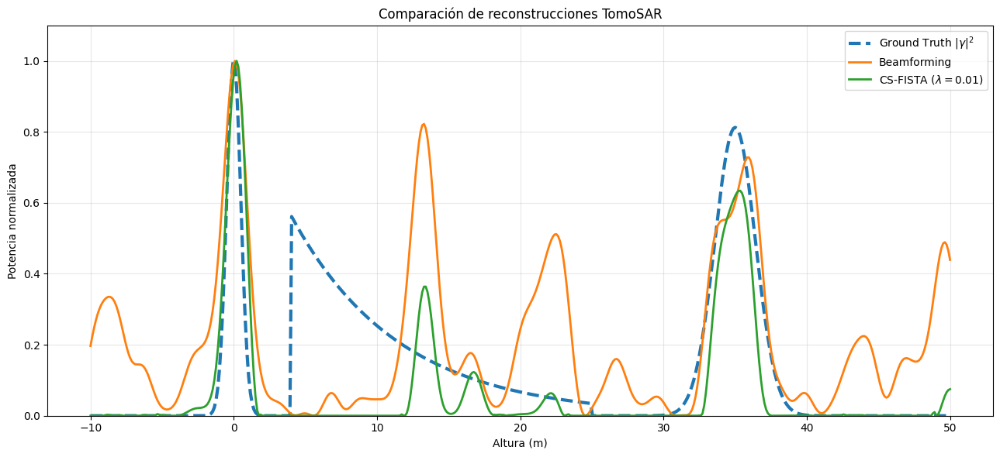

In [ ]:
# ============================================================
# COMPARACIÓN DE RECONSTRUCCIONES
# ============================================================

# ------------------------------------------------------------
# Todas las curvas que se comparan aquí están expresadas como
# POTENCIA NORMALIZADA:
#
# Ground Truth:   P_GT(s) = |gamma(s)|²
# Beamforming:    P_BF(s) = |a(s)^H g|²
# FISTA:          P_FISTA(s) = |gamma_hat(s)|²
# ------------------------------------------------------------

plt.figure(figsize=(13, 6))

# GROUND TRUTH
plt.plot(s, P_gamma, "--", linewidth=3, label=r"Ground Truth $|\gamma|^2$")

# BEAMFORMING
plt.plot(s, P_beamforming, linewidth=2, label="Beamforming")

# FISTA
plt.plot(s, P_fista, linewidth=2, label=f"CS-FISTA ($\\lambda={lambda_reg}$)")

plt.xlabel("Altura (m)")
plt.ylabel("Potencia normalizada")
plt.title("Comparación de reconstrucciones TomoSAR")
plt.grid(True, alpha=0.3)
plt.legend()
plt.ylim(0, 1.1)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# MÉTRICAS DE RECONSTRUCCIÓN
# ============================================================

# ------------------------------------------------------------
# ERROR DE POTENCIA
# ------------------------------------------------------------
# RMSE = sqrt(mean((P_recon - P_GT)^2))
# ------------------------------------------------------------

rmse_beamforming = np.sqrt(np.mean((P_beamforming - P_gamma) ** 2))
rmse_fista = np.sqrt(np.mean((P_fista - P_gamma) ** 2))

# ============================================================
# ERROR DEL MODELO FORWARD
# ============================================================
#
# Para FISTA:
#
#       g_hat = R * gamma_hat
#
# y queremos que:
#
#       g_hat ≈ g
#
# ------------------------------------------------------------

g_fista = (
    R @ gamma_fista
)


residual_fista = (
    np.linalg.norm(
        g - g_fista
    )
    /
    np.linalg.norm(g)
)


# ============================================================
# SPARSITY
# ============================================================

# Número de bins prácticamente diferentes de cero.

threshold_sparsity = (
    0.01
    * np.max(
        np.abs(gamma_fista)
    )
)


number_nonzero = np.sum(
    np.abs(gamma_fista)
    > threshold_sparsity
)


# ============================================================
# RESULTADOS
# ============================================================

print("============================================")
print("MÉTRICAS")
print("============================================")

print(
    f"RMSE Beamforming : "
    f"{rmse_beamforming:.6f}"
)

print(
    f"RMSE FISTA       : "
    f"{rmse_fista:.6f}"
)

print(
    f"Error forward FISTA : "
    f"{residual_fista:.6e}"
)

print(
    f"Bins activos FISTA : "
    f"{number_nonzero} / {L}"
)

MÉTRICAS
RMSE Beamforming : 0.226302
RMSE FISTA       : 0.155572
Error forward FISTA : 1.223425e-04
Bins activos FISTA : 279 / 501


ALTURAS DETECTADAS POR FISTA
Altura =    0.20 m | Potencia = 1.000
Altura =   13.40 m | Potencia = 0.364
Altura =   16.76 m | Potencia = 0.123
Altura =   35.36 m | Potencia = 0.634


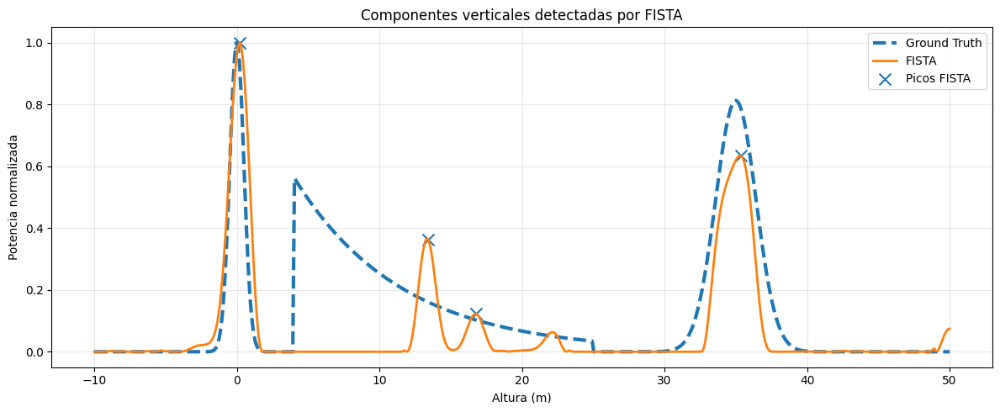

In [ ]:
# ============================================================
# DETECCIÓN DE COMPONENTES FISTA
# ============================================================

# ------------------------------------------------------------
# FISTA produce una estimación compleja:
#
#       gamma_hat(s)
#
# Su potencia es:
#
#       P(s) = |gamma_hat(s)|²
#
# Buscamos máximos locales en esta potencia.
# ------------------------------------------------------------

peaks_fista, properties = find_peaks(P_fista, height=0.10, distance=5)

# ============================================================
# RESULTADOS
# ============================================================

print("============================================")
print("ALTURAS DETECTADAS POR FISTA")
print("============================================")

if len(peaks_fista) == 0:

    print("No se detectaron picos con el umbral seleccionado.")

else:
    for idx in peaks_fista:

        print(
            f"Altura = {s[idx]:7.2f} m | "
            f"Potencia = {P_fista[idx]:.3f}"
        )

# ============================================================
# VISUALIZACIÓN
# ============================================================

plt.figure(figsize=(12, 5))
plt.plot(s, P_gamma, "--", linewidth=3, label="Ground Truth")
plt.plot(s, P_fista, linewidth=2, label="FISTA")
plt.scatter(s[peaks_fista], P_fista[peaks_fista], marker="x", s=100,
            label="Picos FISTA")
plt.xlabel("Altura (m)")
plt.ylabel("Potencia normalizada")
plt.title("Componentes verticales detectadas por FISTA")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

> ADMM

In [ ]:
# ============================================================
# CS-ADMM
# ============================================================

# ------------------------------------------------------------
# ADMM PARA RECONSTRUCCIÓN TOMOSAR DISPERSA
# ------------------------------------------------------------
#
# Queremos resolver:
#       min_gamma
#       1/2 ||g - R*gamma||_2^2 + lambda ||gamma||_1
#
# Introducimos una variable auxiliar z: gamma = z
# y obtenemos:
#       min_gamma,z
#       1/2 ||g - R*gamma||_2^2 + lambda ||z||_1
#       sujeto a:
#       gamma - z = 0
#
# ------------------------------------------------------------
# PASO 1 - ACTUALIZACIÓN DE gamma
# ------------------------------------------------------------
#
# Se resuelve:
# gamma^(k+1) = argmin_gamma 1/2||g - R*gamma||² + rho/2||gamma - z^k + u^k||²
#
# La solución es: (R^H R + rho I) gamma = R^H g + rho(z - u)
#
# ------------------------------------------------------------
# PASO 2 - ACTUALIZACIÓN DE z
# ------------------------------------------------------------
#
#       z^(k+1) = S_(lambda/rho)(gamma^(k+1) + u^k)
#
# donde S es el soft-thresholding.
#
# Para valores complejos: S_tau(x) = max(1 - tau/|x|, 0) * x
#
# ------------------------------------------------------------
# PASO 3 - VARIABLE DUAL
# ------------------------------------------------------------
#
#       u^(k+1) = u^k + gamma^(k+1) - z^(k+1)
#
# ------------------------------------------------------------

def soft_threshold_complex(x, threshold):
    magnitude = np.abs(x)
    scale = np.maximum(1.0 - threshold / (magnitude + 1e-12), 0.0)
    return scale * x

def admm_tomosar(R, g, lambda_reg=0.01, rho=1.0, max_iter=2000, abs_tol=1e-6,
                 rel_tol=1e-5):
    N, L = R.shape

    # MATRIZ DEL SISTEMA: A = R^H R + rho I
    A = (R.conj().T @ R + rho * np.eye(L, dtype=complex))

    # ========================================================
    # TÉRMINO R^H g
    # ========================================================

    Rt_g = (R.conj().T @ g)

    # ========================================================
    # INICIALIZACIÓN
    # ========================================================

    gamma = np.zeros(L, dtype=complex)
    z = np.zeros(L, dtype=complex)
    u = np.zeros(L, dtype=complex)

    # ========================================================
    # ITERACIONES ADMM
    # ========================================================

    for iteration in range(max_iter):

        # ----------------------------------------------------
        # PASO 1
        # Actualización de gamma
        # (R^H R + rho I) gamma = R^H g + rho(z-u)
        # ----------------------------------------------------

        rhs = (Rt_g + rho * (z - u))
        gamma = np.linalg.solve(A, rhs)

        # ----------------------------------------------------
        # PASO 2
        # Actualización de z
        # z = S_(lambda/rho)(gamma + u)
        # ----------------------------------------------------

        z_old = z.copy()
        z = soft_threshold_complex(gamma + u, lambda_reg / rho)

        # ----------------------------------------------------
        # PASO 3
        # Actualización de variable dual
        # u = u + gamma - z
        # ----------------------------------------------------

        u = (u + gamma - z)

        # ----------------------------------------------------
        # RESIDUAL PRIMAL
        # ----------------------------------------------------
        # r = gamma - z

        primal_residual = (np.linalg.norm(gamma - z))

        # ----------------------------------------------------
        # RESIDUAL DUAL
        # ----------------------------------------------------
        # s = rho(z - z_old)

        dual_residual = (rho * np.linalg.norm(z - z_old))

        # ----------------------------------------------------
        # CRITERIOS DE PARADA
        # ----------------------------------------------------

        eps_primal = (np.sqrt(L) * abs_tol + rel_tol
                      * max(np.linalg.norm(gamma), np.linalg.norm(z)))
        eps_dual = (np.sqrt(L) * abs_tol + rel_tol * rho * np.linalg.norm(u))

        if (primal_residual <= eps_primal and dual_residual <= eps_dual):
            print(f"ADMM convergió en {iteration + 1} iteraciones.")
            break

    else:
        print(f"ADMM alcanzó el máximo de {max_iter} iteraciones.")

    return gamma

# ============================================================
# EJECUTAR ADMM
# ============================================================

lambda_admm = 0.01
rho_admm = 1.0

gamma_admm = admm_tomosar(R, g, lambda_reg=lambda_admm, rho=rho_admm,
                          max_iter=2000)

# ============================================================
# POTENCIA RECONSTRUIDA
# ============================================================

P_admm = (np.abs(gamma_admm) ** 2)

# Normalización
if np.max(P_admm) > 0:
    P_admm /= np.max(P_admm)

print("\n============================================")
print("ADMM")
print("============================================")
print(f"lambda = {lambda_admm}")
print(f"rho    = {rho_admm}")

ADMM convergió en 1397 iteraciones.

ADMM
lambda = 0.01
rho    = 1.0


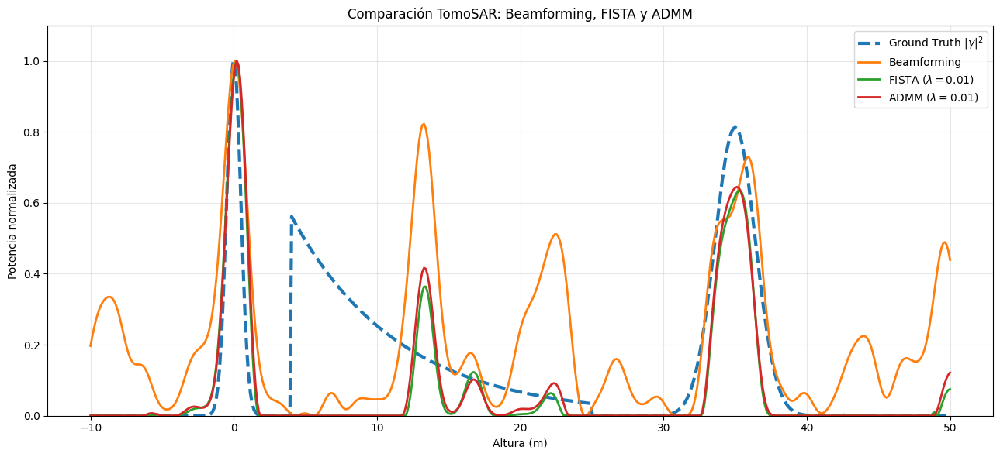

In [ ]:
# ============================================================
# COMPARACIÓN FISTA VS ADMM
# ============================================================

# ------------------------------------------------------------
# Las dos técnicas resuelven esencialmente el mismo problema:
#
#       min_gamma
#
#       1/2 ||g - R*gamma||²
#       + lambda ||gamma||_1
#
# Por lo tanto, si convergen correctamente y usamos el mismo
# lambda, deberían obtener soluciones similares.
# ------------------------------------------------------------

plt.figure(figsize=(13, 6))

# GROUND TRUTH
plt.plot(s, P_gamma, "--", linewidth=3, label=r"Ground Truth $|\gamma|^2$")

# BEAMFORMING
plt.plot(s, P_beamforming, linewidth=2, label="Beamforming")

# FISTA
plt.plot(s, P_fista, linewidth=2, label=f"FISTA ($\\lambda={lambda_reg}$)")

# ADMM
plt.plot(s, P_admm, linewidth=2, label=f"ADMM ($\\lambda={lambda_admm}$)")

plt.xlabel("Altura (m)")
plt.ylabel("Potencia normalizada")
plt.title("Comparación TomoSAR: Beamforming, FISTA y ADMM")
plt.grid(True, alpha=0.3)
plt.legend()
plt.ylim(0, 1.1)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# MÉTRICAS ADMM
# ============================================================

# ------------------------------------------------------------
# ERROR DE POTENCIA
# ------------------------------------------------------------

rmse_admm = np.sqrt(np.mean((P_admm - P_gamma) ** 2))

# ------------------------------------------------------------
# FORWARD MODEL
# ------------------------------------------------------------
#
# Reconstruimos las observaciones: g_hat = R * gamma_ADMM
# y comprobamos: g_hat ≈ g
#
# ------------------------------------------------------------

g_admm = (R @ gamma_admm)
residual_admm = (np.linalg.norm(g - g_admm) / np.linalg.norm(g))

# ------------------------------------------------------------
# SPARSITY
# ------------------------------------------------------------

threshold_sparsity_admm = (0.01 * np.max(np.abs(gamma_admm)))
number_nonzero_admm = np.sum(np.abs(gamma_admm) > threshold_sparsity_admm)

# ============================================================
# RESULTADOS
# ============================================================

print("============================================")
print("MÉTRICAS ADMM")
print("============================================")
print(f"RMSE ADMM          : {rmse_admm:.6f}")
print(f"Residual forward   : {residual_admm:.6e}")
print(f"Bins activos ADMM  : {number_nonzero_admm} / {L}")

MÉTRICAS ADMM
RMSE ADMM          : 0.156376
Residual forward   : 1.223499e-04
Bins activos ADMM  : 223 / 501


 ESTEBAN: Generación de datos para Multilook

Hasta ahora trabajamos con un solo look: un vector g de 8 observaciones para el píxel. Con un solo look, la covarianza tiene rango 1 y Capon y MUSIC no tienen información suficiente para funcionar.

Multilook significa tener varias observaciones del mismo perfil vertical. En datos reales, cada look es un píxel vecino dentro de una ventana (por ejemplo, 5×5 = 25 looks). Cada vecino tiene su propio speckle. Las amplitudes y fases de los dispersores cambian de un píxel a otro.

Modelo que usan estas celdas. Para cada look $k$:

$$g_k = R\,\gamma_k + w_k, \qquad \gamma_k(s) \sim \mathcal{CN}\big(0,\;P(s)\big), \qquad w_k \sim \mathcal{CN}(0,\;\sigma^2 I)$$

- $P(s)$ es el perfil de potencia de la escena (el ground truth). Es lo que comparten todos los looks.
- $\gamma_k(s)$ es complejo gaussiano, independiente entre alturas y entre looks (eso es el speckle).
- Con este modelo, la covarianza teórica es $R_{cov} = R\,\mathrm{diag}(P)\,R^H + \sigma^2 I$, y la covarianza muestral $\hat R_{cov} = \frac{1}{K}\sum_k g_k g_k^H$ se acerca a ella al aumentar el número de looks $K$.

**Qué entregan estas:** `G_ml` (los looks), `R_cov_ml` (covarianza muestral), `R_cov_true` (covarianza teórica), `P_true` (ground truth) y la función `generar_multilook()` para regenerar los datos con otros parámetros. El detalle está en la última celda de esta sección.

In [ ]:
# MULTILOOK: PARÁMETROS

N_LOOKS = 25        # número de looks (ventana 5x5)
SNR_DB = 0         # relación señal/ruido por adquisición [dB] - NO DE MOMENTO
SEMILLA_ML = 0      # semilla:
                    # con la misma semilla los datos se repiten exactamente

ESCENA = "equipo"   # "equipo"  -> suelo + vegetación + montaña
                    # (la escena de la sección de geometría)
                    # "puntual" -> scatterers puntuales,
                    # útil para medir resolución

print(f"Looks: {N_LOOKS} | SNR: {SNR_DB} dB | Escena: {ESCENA}")

Looks: 25 | SNR: 0 dB | Escena: equipo


DIAGNÓSTICO DE LA GEOMETRÍA
Resolución en altura: 1.65 m
Lóbulos laterales mayores a 0.5 (distancia al scatterer):
   13.12 m  ->  0.74
   22.90 m  ->  0.70
   33.15 m  ->  0.60
   36.20 m  ->  0.60
   44.03 m  ->  0.59
   49.70 m  ->  0.54
   56.10 m  ->  0.80


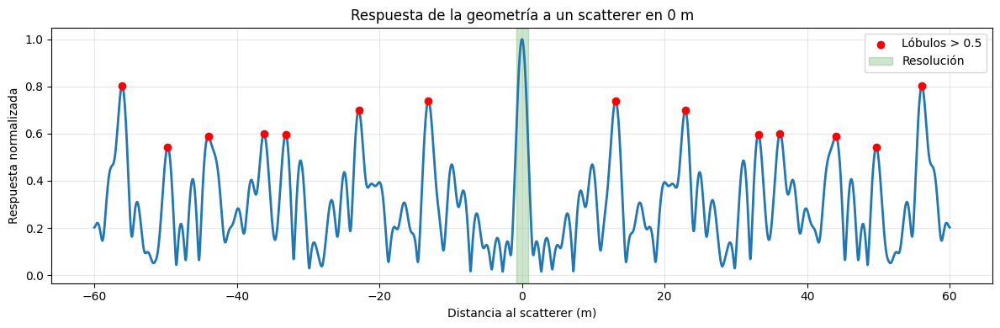

In [ ]:
# DIAGNÓSTICO DE LA GEOMETRÍA: RESPUESTA A UN SCATTERER EN 0 m

# Antes de interpretar cualquier reconstrucción conviene saber qué
# "fantasmas" produce la geometría por sí sola. Para un único scatterer
# en 0 m, la respuesta de las 8 pasadas en función de la distancia es:
#
#     respuesta(d) = | sum_n exp(j * kz_n * d) | / N
#
# - El ancho del pico central es la resolución en altura.
# - Los picos secundarios (lóbulos laterales) aparecen en cualquier
#   método como picos falsos alrededor de un scatterer fuerte.
#
# ------------------------------------------------------------

resolucion_altura = 2 * np.pi / (kz.max() - kz.min())

distancia = np.linspace(-60, 60, 4801)
respuesta = np.abs(np.exp(1j * np.outer(distancia, kz)).sum(axis=1)) / N

lobulos, _ = find_peaks(respuesta)
lobulos = lobulos[(distancia[lobulos] > 1.5 * resolucion_altura) & (respuesta[lobulos] > 0.5)]

print("============================================")
print("DIAGNÓSTICO DE LA GEOMETRÍA")
print("============================================")
print(f"Resolución en altura: {resolucion_altura:.2f} m")
print("Lóbulos laterales mayores a 0.5 (distancia al scatterer):")
for i_lobulo in lobulos:
    print(f"  {distancia[i_lobulo]:6.2f} m  ->  {respuesta[i_lobulo]:.2f}")

plt.figure(figsize=(12, 4))
plt.plot(distancia, respuesta, linewidth=2)
plt.scatter(distancia[lobulos], respuesta[lobulos], color="r", zorder=3, label="Lóbulos > 0.5")
plt.scatter(-distancia[lobulos], respuesta[lobulos], color="r", zorder=3)
plt.axvspan(-resolucion_altura / 2, resolucion_altura / 2, color="g", alpha=0.2, label="Resolución")
plt.xlabel("Distancia al scatterer (m)")
plt.ylabel("Respuesta normalizada")
plt.title("Respuesta de la geometría a un scatterer en 0 m")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

PERFIL DE POTENCIA
Suelo (0 m) + vegetación (4-25 m) + montaña (35 m)
Potencia total (suma sobre alturas): 67.59


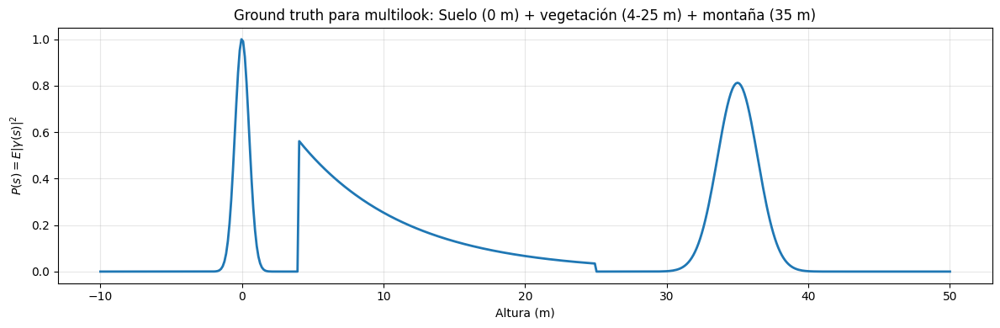

In [ ]:
# PERFIL DE POTENCIA (GROUND TRUTH PARA MULTILOOK)

# En multilook, lo que comparten todos los looks es su potencia promedio por altura:  P(s) = E[ |gamma(s)|^2 ]

def perfil_puntual(alturas, potencias, ancho=0.3):
    """Perfil de potencia con scatterers casi puntuales (gaussianas muy angostas) en las alturas dadas."""
    P = np.zeros(L)
    for h, p in zip(alturas, potencias):
        P += p * np.exp(-0.5 * ((s - h) / ancho) ** 2)
    return P / P.max()

if ESCENA == "equipo":
    P_true = np.abs(gamma) ** 2                               # suelo + vegetación + montaña
    descripcion = "Suelo (0 m) + vegetación (4-25 m) + montaña (35 m)"
elif ESCENA == "puntual":
    alturas_puntuales = [0.0, 1.2, 18.0]                      # 0 y 1.2 m están más cerca que la resolución
    P_true = perfil_puntual(alturas_puntuales, [1.0, 0.7, 0.8])
    descripcion = f"Scatterers puntuales en {alturas_puntuales} m"
else:
    raise ValueError("ESCENA debe ser 'equipo' o 'puntual'")

P_true = P_true / P_true.max()

print("============================================")
print("PERFIL DE POTENCIA")
print("============================================")
print(descripcion)
print(f"Potencia total (suma sobre alturas): {P_true.sum():.2f}")

plt.figure(figsize=(12, 4))
plt.plot(s, P_true, linewidth=2)
plt.title(f"Ground truth para multilook: {descripcion}")
plt.xlabel("Altura (m)")
plt.ylabel(r"$P(s) = E|\gamma(s)|^2$")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# GENERACIÓN DE LOS LOOKS


def generar_multilook(P, R, n_looks, snr_db=None, rng=None):
    """Genera n_looks observaciones del mismo perfil de potencia P(s).

    Cada look:  g_k = R @ gamma_k + ruido_k
    con gamma_k(s) complejo gaussiano de media 0 y potencia P(s),
    independiente entre alturas y entre looks (speckle).

    snr_db: potencia de la señal por adquisición / potencia del ruido.
            Si es None, no se agrega ruido.

    Devuelve:
      G      -> (N, n_looks)  observaciones, una columna por look
      gammas -> (L, n_looks)  reflectividad de cada look
      sigma2 -> potencia del ruido por adquisición (0 si no hay ruido)
    """
    rng = np.random.default_rng() if rng is None else rng
    n_alturas = R.shape[1]
    speckle = (rng.standard_normal((n_alturas, n_looks))
               + 1j * rng.standard_normal((n_alturas, n_looks))) / np.sqrt(2)
    gammas = np.sqrt(P)[:, None] * speckle
    G = R @ gammas
    sigma2 = 0.0
    if snr_db is not None:
        potencia_senal = np.sum(P)              # E|g_n|^2 sin ruido, porque |R[n, l]| = 1
        #sigma2 = potencia_senal / 10 ** (snr_db / 10)
        #ruido = np.sqrt(sigma2 / 2) * (rng.standard_normal(G.shape) + 1j * rng.standard_normal(G.shape))
        G = G #+ ruido
    return G, gammas, sigma2


def covarianza_muestral(G):
    """Covarianza estimada con los looks: (1/K) * sum_k g_k g_k^H  ->  (N, N)."""
    return G @ G.conj().T / G.shape[1]


def covarianza_teorica(P, R, sigma2):
    """Covarianza a la que converge la muestral con infinitos looks: R diag(P) R^H + sigma2 I."""
    return (R * P) @ R.conj().T + sigma2 * np.eye(R.shape[0])


rng_ml = np.random.default_rng(SEMILLA_ML)
G_ml, gammas_ml, sigma2_ruido = generar_multilook(P_true, R, N_LOOKS, snr_db=SNR_DB, rng=rng_ml)
R_cov_ml = covarianza_muestral(G_ml)
R_cov_true = covarianza_teorica(P_true, R, sigma2_ruido)

print("============================================")
print("DATOS MULTILOOK")
print("============================================")
print(f"G_ml        : {G_ml.shape}  (adquisiciones x looks)")
print(f"R_cov_ml    : {R_cov_ml.shape}  (covarianza muestral)")
print(f"R_cov_true  : {R_cov_true.shape}  (covarianza teórica)")
print(f"Potencia del ruido sigma2 = {sigma2_ruido:.4f}")
print(f"Rango de R_cov_ml: {np.linalg.matrix_rank(R_cov_ml)} de {N}")
print(f"Número de condición de R_cov_ml: {np.linalg.cond(R_cov_ml):.1f}")
error_rel = np.linalg.norm(R_cov_ml - R_cov_true) / np.linalg.norm(R_cov_true)
print(f"Diferencia relativa entre covarianza muestral y teórica: {100 * error_rel:.1f} %")

DATOS MULTILOOK
G_ml        : (8, 25)  (adquisiciones x looks)
R_cov_ml    : (8, 8)  (covarianza muestral)
R_cov_true  : (8, 8)  (covarianza teórica)
Potencia del ruido sigma2 = 0.0000
Rango de R_cov_ml: 8 de 8
Número de condición de R_cov_ml: 9.5
Diferencia relativa entre covarianza muestral y teórica: 44.0 %


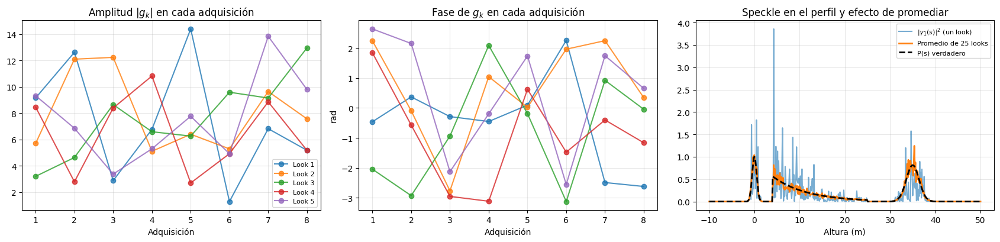

In [ ]:
# VISUALIZACIÓN: CÓMO CAMBIAN LOS LOOKS (SPECKLE)

# Un solo look es poco confiable y promediar varios con multilook estabiliza la estimación.

n_mostrar = 5
fig_ml, ax_ml = plt.subplots(1, 3, figsize=(17, 4.2))

for k_look in range(n_mostrar):
    ax_ml[0].plot(np.arange(1, N + 1), np.abs(G_ml[:, k_look]), "o-", alpha=0.8, label=f"Look {k_look + 1}")
    ax_ml[1].plot(np.arange(1, N + 1), np.angle(G_ml[:, k_look]), "o-", alpha=0.8)
ax_ml[0].set_title(r"Amplitud $|g_k|$ en cada adquisición")
ax_ml[0].set_xlabel("Adquisición"); ax_ml[0].legend(fontsize=8)
ax_ml[1].set_title(r"Fase de $g_k$ en cada adquisición")
ax_ml[1].set_xlabel("Adquisición"); ax_ml[1].set_ylabel("rad")

ax_ml[2].plot(s, np.abs(gammas_ml[:, 0]) ** 2, alpha=0.6, label=r"$|\gamma_1(s)|^2$ (un look)")
ax_ml[2].plot(s, np.mean(np.abs(gammas_ml) ** 2, axis=1), linewidth=2, label=f"Promedio de {N_LOOKS} looks")
ax_ml[2].plot(s, P_true, "k--", linewidth=2, label="P(s) verdadero")
ax_ml[2].set_title("Speckle en el perfil y efecto de promediar")
ax_ml[2].set_xlabel("Altura (m)"); ax_ml[2].legend(fontsize=8)

for a in ax_ml:
    a.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Cómo usar estos datos en los algoritmos

| Variable | Tamaño | Qué es |
|---|---|---|
| `P_true` | (L,) | Ground truth: potencia por altura, normalizada a 1. Es la curva contra la que se compara cualquier reconstrucción. |
| `G_ml` | (N, N_LOOKS) | Observaciones: una columna por look. |
| `R_cov_ml` | (N, N) | Covarianza muestral $\frac{1}{K}\sum_k g_k g_k^H$. Es la que usan Capon y MUSIC. |
| `R_cov_true` | (N, N) | Covarianza teórica (infinitos looks). Sirve para ver el mejor resultado posible de cada método. |
| `sigma2_ruido` | escalar | Potencia del ruido por adquisición. |
| `generar_multilook(P, R, n_looks, snr_db, rng)` | función | Regenera los datos con otro número de looks, otro SNR u otra escena. |

RESULTADOS CAPON Y MUSIC
Escena: equipo
Adquisiciones: 8
Looks: 25
Fuentes asumidas por MUSIC: 3
Carga diagonal CAPON: 6.245e-05
Condición covarianza original: 9.493e+00
Condición covarianza regularizada: 9.492e+00

Autovalores de la covarianza:
[139.4726 111.4468  74.6408  63.7918  40.4362  32.2247  22.8591  14.6929]

Porcentaje de energía en los autovalores seleccionados:
65.17 %


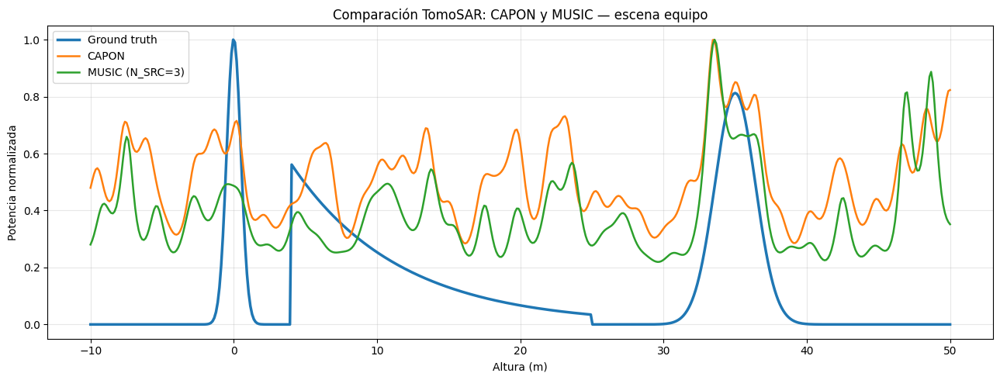

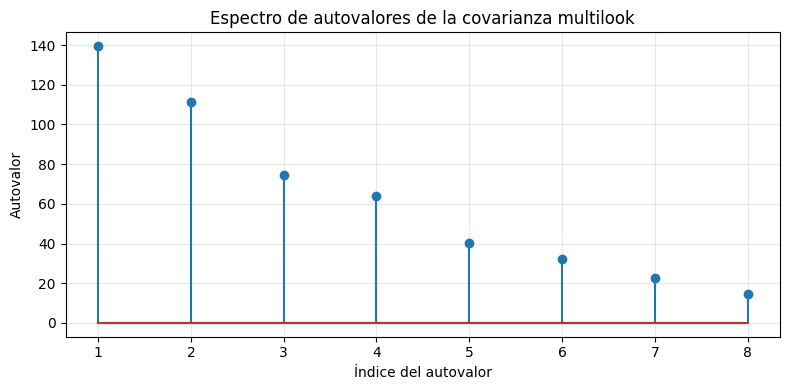

In [ ]:
# ============================================================
# RECONSTRUCCIÓN TOMOSAR MEDIANTE CAPON Y MUSIC
# ============================================================
#
# CAPON:
#   P_CAPON(s) = 1 / (a(s)^H @ R_cov^{-1} @ a(s))
#
# MUSIC:
#   P_MUSIC(s) = 1 / || E_noise^H @ a(s) ||^2
#
# Donde:
#   R_cov   : covarianza muestral de los multilooks
#   a(s)    : vector de direccionamiento para la altura s
#   E_noise : base del subespacio de ruido
#   N_SRC   : número de fuentes asumido por MUSIC
#
# IMPORTANTE:
#   Para la escena "equipo", la vegetación es volumétrica.
#   Por tanto, MUSIC con un número pequeño de fuentes es
#   una aproximación y no una estimación exacta de su potencia.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Parámetros
# ------------------------------------------------------------

N_SRC = 3

# Regularización de CAPON para mejorar la estabilidad numérica.
# Se escala según la potencia media de la diagonal de R_cov_ml.
EPS_CAPON = 1e-6

# Pequeña constante para evitar divisiones entre cero.
EPS = 1e-12

# ------------------------------------------------------------
# 2. Validaciones
# ------------------------------------------------------------

N_ADQ, N_LOOKS_REAL = G_ml.shape

assert R.shape[0] == N_ADQ, \
    "Las adquisiciones de R y G_ml no coinciden."

assert R_cov_ml.shape == (N_ADQ, N_ADQ), \
    "La covarianza tiene dimensiones incorrectas."

assert 1 <= N_SRC < N_ADQ, \
    "N_SRC debe estar entre 1 y N_ADQ - 1."

# ------------------------------------------------------------
# 3. Regularización de la covarianza
# ------------------------------------------------------------

# R_loaded = R_cov_ml + delta * I
#
# La carga diagonal reduce problemas numéricos al invertir
# la covarianza. No sustituye la necesidad de una buena
# estimación estadística de dicha matriz.

R_cov = (R_cov_ml + R_cov_ml.conj().T) / 2

potencia_media = np.real(np.trace(R_cov)) / N_ADQ
delta = EPS_CAPON * max(potencia_media, EPS)

R_loaded = R_cov + delta * np.eye(N_ADQ, dtype=complex)

# ------------------------------------------------------------
# 4. CAPON
# ------------------------------------------------------------

# Para cada altura s_l:
# P_CAPON(s_l) = 1 / (a_l^H @ inv(R_loaded) @ a_l)
#
# Se resuelve un sistema lineal en vez de calcular explícitamente
# la inversa de la covarianza.

Rinv_A = np.linalg.solve(R_loaded, R)

den_cap = np.real(np.sum(R.conj() * Rinv_A, axis=0))

P_CAPON = 1.0 / np.maximum(den_cap, EPS)
P_CAPON = np.maximum(P_CAPON, 0)
P_CAPON /= max(P_CAPON.max(), EPS)

# ------------------------------------------------------------
# 5. MUSIC
# ------------------------------------------------------------

# Descomposición espectral:
# R_cov = E @ diag(eigenvalues) @ E^H
#
# Los autovectores se ordenan de mayor a menor autovalor.
# Los primeros N_SRC representan el subespacio de señal.
# Los restantes forman el subespacio de ruido.

eigenvalues, eigenvectors = np.linalg.eigh(R_cov)

orden = np.argsort(eigenvalues)[::-1]
eigenvalues = np.real(eigenvalues[orden])
eigenvectors = eigenvectors[:, orden]

E_signal = eigenvectors[:, :N_SRC]
E_noise = eigenvectors[:, N_SRC:]

# Proyección de cada vector de direccionamiento sobre
# el subespacio de ruido:
# denominator(s) = || E_noise^H @ a(s) ||^2

proyeccion_ruido = E_noise.conj().T @ R
den_music = np.sum(np.abs(proyeccion_ruido)**2, axis=0)

P_MUSIC = 1.0 / np.maximum(den_music, EPS)
P_MUSIC = np.maximum(P_MUSIC, 0)
P_MUSIC /= max(P_MUSIC.max(), EPS)

# ------------------------------------------------------------
# 6. Diagnóstico
# ------------------------------------------------------------

print("=" * 55)
print("RESULTADOS CAPON Y MUSIC")
print("=" * 55)
print(f"Escena: {ESCENA}")
print(f"Adquisiciones: {N_ADQ}")
print(f"Looks: {N_LOOKS_REAL}")
print(f"Fuentes asumidas por MUSIC: {N_SRC}")
print(f"Carga diagonal CAPON: {delta:.3e}")
print(f"Condición covarianza original: {np.linalg.cond(R_cov):.3e}")
print(f"Condición covarianza regularizada: {np.linalg.cond(R_loaded):.3e}")

print("\nAutovalores de la covarianza:")
print(np.array2string(eigenvalues, precision=4))

print("\nPorcentaje de energía en los autovalores seleccionados:")
energia_total = max(np.sum(np.maximum(eigenvalues, 0)), EPS)
energia_signal = np.sum(np.maximum(eigenvalues[:N_SRC], 0))
print(f"{100 * energia_signal / energia_total:.2f} %")

# ------------------------------------------------------------
# 7. Visualización
# ------------------------------------------------------------

plt.figure(figsize=(13, 5))

plt.plot(s, P_true, label="Ground truth", linewidth=2.5)
plt.plot(s, P_CAPON, label="CAPON", linewidth=1.8)
plt.plot(s, P_MUSIC, label=f"MUSIC (N_SRC={N_SRC})", linewidth=1.8)

plt.xlabel("Altura (m)")
plt.ylabel("Potencia normalizada")
plt.title(f"Comparación TomoSAR: CAPON y MUSIC — escena {ESCENA}")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Autovalores: diagnóstico de la estructura de la covarianza
plt.figure(figsize=(8, 4))
plt.stem(np.arange(1, N_ADQ + 1), np.maximum(eigenvalues, 0))
plt.xlabel("Índice del autovalor")
plt.ylabel("Autovalor")
plt.title("Espectro de autovalores de la covarianza multilook")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


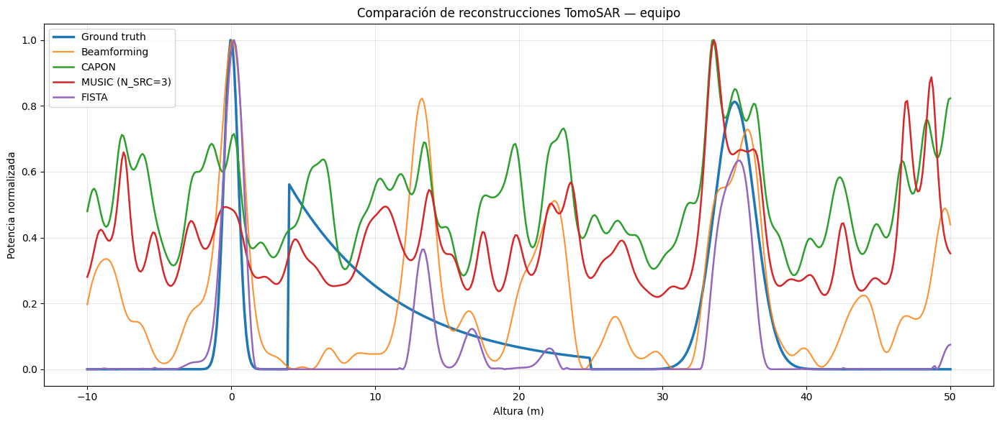

In [ ]:
# ============================================================
# COMPARACIÓN DE LOS MÉTODOS DE RECONSTRUCCIÓN
# ============================================================
#
# Se comparan perfiles normalizados de potencia:
# Ground truth, Beamforming, CAPON, MUSIC y FISTA.
#
# Nota: los perfiles representan estimaciones diferentes.
# La normalización facilita comparar la localización de picos,
# pero no garantiza que las amplitudes sean comparables.
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(s, P_true, label="Ground truth", linewidth=2.5)
plt.plot(s, P_beamforming, label="Beamforming", alpha=0.85)
plt.plot(s, P_CAPON, label="CAPON", linewidth=1.8)
plt.plot(s, P_MUSIC, label=f"MUSIC (N_SRC={N_SRC})", linewidth=1.8)
plt.plot(s, P_fista, label="FISTA", linewidth=1.8)

plt.xlabel("Altura (m)")
plt.ylabel("Potencia normalizada")
plt.title(f"Comparación de reconstrucciones TomoSAR — {ESCENA}")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:

# ============================================================
# FISTA Y ADMM CON DATOS MULTILOOK
# ============================================================
#
# Ambos métodos resuelven el mismo problema:
#
# min_Gamma (1/(2*K))*||G_ml - R @ Gamma||_F^2
#           + lambda_reg * ||Gamma||_1
#
# G_ml     : matriz de observaciones (N, K)
# R        : matriz de direccionamiento (N, L)
# Gamma    : reflectividad reconstruida (L, K)
# K        : número de looks
#
# FISTA utiliza descenso acelerado por gradiente.
# ADMM utiliza una variable auxiliar y umbralización compleja.
#
# La división entre K normaliza el término de datos.
# Se utiliza el mismo lambda para ambos algoritmos.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import time

# ------------------------------------------------------------
# 1. Parámetros comunes
# ------------------------------------------------------------

lambda_reg = 0.01
MAX_ITER = 2000
TOL = 1e-6

N_ADQ, K = G_ml.shape
L = R.shape[1]

assert R.shape[0] == N_ADQ
assert G_ml.shape == (N_ADQ, K)

print("Dataset multilook:", G_ml.shape)
print("Matriz de direccionamiento:", R.shape)
print("Lambda común:", lambda_reg)

# ------------------------------------------------------------
# 2. Función de umbralización compleja
# ------------------------------------------------------------

# S_tau(z) = max(1 - tau/|z|, 0) * z
#
# Esta función se aplica elemento a elemento y conserva
# la fase compleja de los coeficientes que no se anulan.

def soft_threshold_complex(x, threshold):
    magnitude = np.abs(x)
    scale = np.maximum(
        1.0 - threshold / np.maximum(magnitude, 1e-15),
        0.0
    )
    return scale * x

# ------------------------------------------------------------
# 3. FISTA multilook
# ------------------------------------------------------------

# f(Gamma) = (1/(2*K))*||G_ml - R @ Gamma||_F^2
#
# Gradiente:
# grad f(Gamma) = (1/K)*R^H @ (R @ Gamma - G_ml)
#
# Constante de Lipschitz:
# Lf = ||R||_2^2 / K
#
# Actualización:
# Gamma_new = S_(lambda/Lf)(
#     Y - grad f(Y)/Lf
# )
#
# Aceleración de Nesterov:
# t_new = (1 + sqrt(1 + 4*t^2))/2

def fista_multilook(R, G, lambda_reg=0.01,
                    max_iter=2000, tol=1e-6):

    N, K = G.shape
    L = R.shape[1]

    lipschitz = np.linalg.norm(R, 2)**2 / K

    Gamma = np.zeros((L, K), dtype=complex)
    Y = Gamma.copy()
    t = 1.0

    for iteration in range(max_iter):

        grad = (R.conj().T @ (R @ Y - G)) / K

        Gamma_new = soft_threshold_complex(
            Y - grad / lipschitz,
            lambda_reg / lipschitz
        )

        t_new = (1.0 + np.sqrt(1.0 + 4.0*t*t)) / 2.0

        Y = Gamma_new + ((t - 1.0) / t_new) * (
            Gamma_new - Gamma
        )

        rel_change = (
            np.linalg.norm(Gamma_new - Gamma)
            / max(np.linalg.norm(Gamma), 1e-12)
        )

        Gamma = Gamma_new
        t = t_new

        if iteration > 0 and rel_change < tol:
            break

    return Gamma, iteration + 1

# ------------------------------------------------------------
# 4. ADMM multilook
# ------------------------------------------------------------

# Se separa Gamma = Z y se minimiza:
#
# (1/(2*K))*||G - R @ Gamma||_F^2
# + lambda_reg*||Z||_1
#
# sujeto a Gamma = Z.
#
# Actualización Gamma:
#
# (R^H R/K + rho*I) Gamma =
#       R^H G/K + rho*(Z - U)
#
# Actualización Z:
#
# Z = S_(lambda_reg/rho)(Gamma + U)
#
# Actualización del dual:
#
# U = U + Gamma - Z
#
# La matriz del sistema lineal se factoriza una sola vez
# conceptualmente; aquí se resuelve mediante np.linalg.solve.

def admm_multilook(R, G, lambda_reg=0.01, rho=1.0,
                   max_iter=2000, abs_tol=1e-6,
                   rel_tol=1e-5):

    N, K = G.shape
    L = R.shape[1]

    A = (R.conj().T @ R) / K + rho * np.eye(L)
    RtG = (R.conj().T @ G) / K

    Gamma = np.zeros((L, K), dtype=complex)
    Z = np.zeros_like(Gamma)
    U = np.zeros_like(Gamma)

    for iteration in range(max_iter):

        # Paso primal: solución del sistema lineal
        Gamma = np.linalg.solve(A, RtG + rho * (Z - U))

        Z_old = Z.copy()

        # Paso proximal L1
        Z = soft_threshold_complex(
            Gamma + U,
            lambda_reg / rho
        )

        # Actualización de la variable dual
        U = U + Gamma - Z

        # Criterios de convergencia
        r_norm = np.linalg.norm(Gamma - Z)
        s_norm = rho * np.linalg.norm(Z - Z_old)

        eps_primal = (
            np.sqrt(L*K) * abs_tol
            + rel_tol * max(
                np.linalg.norm(Gamma),
                np.linalg.norm(Z)
            )
        )

        eps_dual = (
            np.sqrt(L*K) * abs_tol
            + rel_tol * rho * np.linalg.norm(U)
        )

        if r_norm <= eps_primal and s_norm <= eps_dual:
            break

    return Z, iteration + 1

# ------------------------------------------------------------
# 5. Ejecutar ambos métodos con el mismo dataset
# ------------------------------------------------------------

inicio = time.perf_counter()
Gamma_fista_ml, iter_fista = fista_multilook(
    R, G_ml,
    lambda_reg=lambda_reg,
    max_iter=MAX_ITER,
    tol=TOL
)
tiempo_fista = time.perf_counter() - inicio

inicio = time.perf_counter()
Gamma_admm_ml, iter_admm = admm_multilook(
    R, G_ml,
    lambda_reg=lambda_reg,
    rho=1.0,
    max_iter=MAX_ITER
)
tiempo_admm = time.perf_counter() - inicio

print("\n===== RESULTADOS DE OPTIMIZACIÓN =====")
print(f"FISTA: {iter_fista} iteraciones, {tiempo_fista:.3f} s")
print(f"ADMM : {iter_admm} iteraciones, {tiempo_admm:.3f} s")

Dataset multilook: (8, 25)
Matriz de direccionamiento: (8, 501)
Lambda común: 0.01

===== RESULTADOS DE OPTIMIZACIÓN =====
FISTA: 2000 iteraciones, 0.816 s
ADMM : 2000 iteraciones, 33.364 s


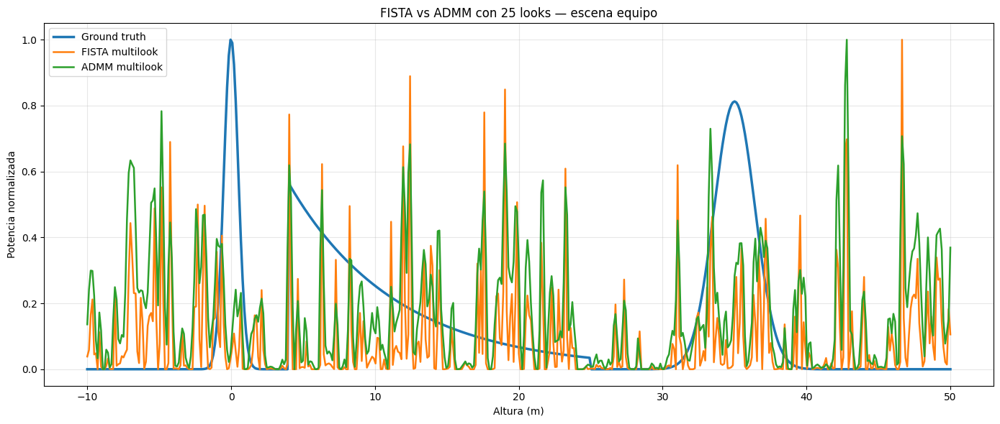

In [ ]:

# ============================================================
# COMPARACIÓN DE POTENCIA MULTILOOK
# ============================================================
#
# P_hat(s_l) = (1/K) * sum_k |Gamma_hat(l,k)|^2
#
# Se calcula la potencia promedio de FISTA y ADMM.
# Todos los perfiles se normalizan a máximo 1 para comparar
# la forma y la localización de las estructuras.
# ============================================================

P_fista_ml = np.mean(np.abs(Gamma_fista_ml)**2, axis=1)
P_admm_ml = np.mean(np.abs(Gamma_admm_ml)**2, axis=1)

P_fista_ml /= max(P_fista_ml.max(), 1e-12)
P_admm_ml /= max(P_admm_ml.max(), 1e-12)

P_true_norm = P_true / max(P_true.max(), 1e-12)

plt.figure(figsize=(14, 6))

plt.plot(s, P_true_norm, label="Ground truth", linewidth=2.5)
plt.plot(s, P_fista_ml, label="FISTA multilook", linewidth=1.8)
plt.plot(s, P_admm_ml, label="ADMM multilook", linewidth=1.8)

plt.xlabel("Altura (m)")
plt.ylabel("Potencia normalizada")
plt.title(f"FISTA vs ADMM con {K} looks — escena {ESCENA}")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Dimensiones G: (8, 25)
Dimensiones R: (8, 501)
Lipschitz de FISTA: 23.05
Lambda máximo estimado: 2.4671
Número de lambdas: 16
Número de rhos: 8
FISTA 01/16 | lambda=0.0002467 | RMSE=0.35671
FISTA 02/16 | lambda=0.0004489 | RMSE=0.33668
FISTA 03/16 | lambda=0.0008169 | RMSE=0.31499
FISTA 04/16 | lambda=0.001487 | RMSE=0.31393
FISTA 05/16 | lambda=0.002705 | RMSE=0.30824
FISTA 06/16 | lambda=0.004922 | RMSE=0.28229
FISTA 07/16 | lambda=0.008957 | RMSE=0.26703
FISTA 08/16 | lambda=0.0163 | RMSE=0.26898
FISTA 09/16 | lambda=0.02966 | RMSE=0.25930
FISTA 10/16 | lambda=0.05397 | RMSE=0.25024
FISTA 11/16 | lambda=0.09822 | RMSE=0.24393
FISTA 12/16 | lambda=0.1787 | RMSE=0.25129
FISTA 13/16 | lambda=0.3252 | RMSE=0.25527
FISTA 14/16 | lambda=0.5918 | RMSE=0.25209
FISTA 15/16 | lambda=1.077 | RMSE=0.25116
FISTA 16/16 | lambda=1.96 | RMSE=0.24369
ADMM rho=  0.03 | lambda=0.0002467 | RMSE=0.33761
ADMM rho=  0.03 | lambda=0.0004489 | RMSE=0.31869
ADMM rho=  0.03 | lambda=0.0008169 | RMSE=0.30733
A

,lambda,RMSE,MAE,Residuo,Iteraciones
0,1.959651,0.243685,0.132759,0.976840,700
1,0.098215,0.243934,0.142915,0.083106,700
2,0.053973,0.250241,0.155781,0.046968,700
3,1.076908,0.251159,0.142631,0.712555,700
4,0.178722,0.251294,0.146988,0.144681,700
5,0.591805,0.252088,0.146290,0.431298,700
6,0.325221,0.255272,0.149389,0.251987,700
7,0.029661,0.259300,0.168777,0.026106,700
8,0.008957,0.267027,0.185725,0.007942,700
9,0.016300,0.268982,0.182380,0.014454,700



===== TOP 10 ADMM =====


,lambda,rho,RMSE,MAE,Residuo,Iteraciones
0,1.959651,100.0,0.232916,0.129223,0.977572,700
1,1.959651,30.0,0.238124,0.131188,0.977216,700
2,1.076908,100.0,0.238902,0.148906,0.717926,700
3,0.178722,1.0,0.240374,0.147839,0.144876,700
4,1.959651,3.0,0.241250,0.132383,0.976886,181
5,1.959651,10.0,0.241276,0.132410,0.976898,569
6,1.076908,30.0,0.243004,0.146034,0.714429,700
7,0.098215,0.3,0.243099,0.143538,0.083066,700
8,1.959651,0.3,0.243692,0.132769,0.976835,572
9,1.959651,0.1,0.243968,0.133069,0.977811,700



===== MEJOR FISTA =====
lambda = 1.95965
RMSE   = 0.243685
MAE    = 0.132759
Residuo= 0.976840

===== MEJOR ADMM =====
lambda = 1.95965
rho    = 100
RMSE   = 0.232916
MAE    = 0.129223
Residuo= 0.977572


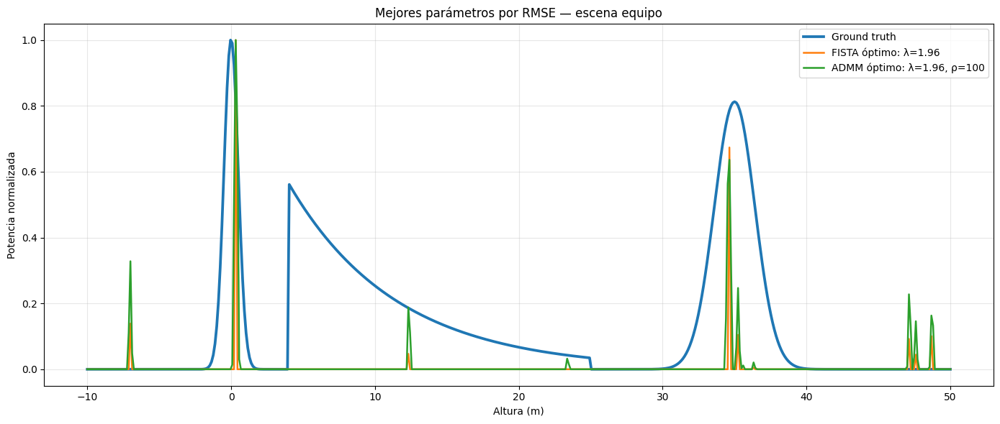

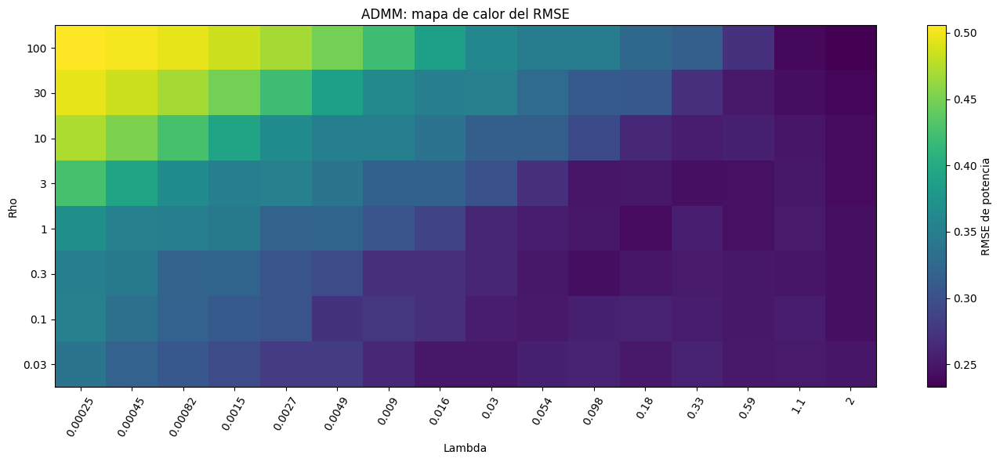

In [ ]:

# ============================================================
# BÚSQUEDA DE LAMBDA Y RHO PARA FISTA Y ADMM
# ============================================================
#
# Problema común:
#
# min_Gamma (1/(2*K))*||G_ml - R @ Gamma||_F^2
#           + lambda_reg * ||Gamma||_1
#
# FISTA: busca lambda_reg.
# ADMM : busca lambda_reg y rho.
#
# Criterio de selección:
# RMSE entre los perfiles de potencia normalizados:
#
# P_hat(s) = mean_k |Gamma_hat(s,k)|^2
#
# RMSE = sqrt(mean((P_hat_norm - P_true_norm)^2))
#
# IMPORTANTE:
# lambda se escala automáticamente a partir de los datos.
# rho afecta la convergencia de ADMM, no el óptimo teórico.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
from scipy.linalg import cho_factor, cho_solve

# ------------------------------------------------------------
# 1. Datos y ground truth
# ------------------------------------------------------------

G = G_ml
N, K = G.shape
L = R.shape[1]

P_ref = np.asarray(P_true, dtype=float).copy()
P_ref = P_ref / max(P_ref.max(), 1e-12)

assert R.shape == (N, L)
assert P_ref.size == L

# Gradiente de la función de datos:
# grad f(Gamma) = R^H @ (R @ Gamma - G) / K
#
# Constante de Lipschitz:
# Lip = ||R||_2^2 / K

Lip = np.linalg.norm(R, 2)**2 / K

# Lambda máximo que puede producir la solución Gamma=0
# para el problema L1 definido en esta celda:
#
# lambda_max = max(abs(R^H @ G / K))

B = (R.conj().T @ G) / K
lambda_max = np.max(np.abs(B))

# Se excluye lambda=0 porque no aplica regularización L1.
# Se explora un rango amplio, desde muy poca regularización
# hasta una regularización relativamente fuerte.

lambdas = lambda_max * np.logspace(-4, -0.10, 16)

# Rho se explora en varias escalas.
# Es una búsqueda inicial; luego se puede refinar alrededor
# de la mejor combinación.

rhos = [0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0]

MAX_ITER_SEARCH = 700
TOL_SEARCH = 2e-5

print("Dimensiones G:", G.shape)
print("Dimensiones R:", R.shape)
print(f"Lipschitz de FISTA: {Lip:.5g}")
print(f"Lambda máximo estimado: {lambda_max:.5g}")
print("Número de lambdas:", len(lambdas))
print("Número de rhos:", len(rhos))

# ------------------------------------------------------------
# 2. Umbralización compleja
# ------------------------------------------------------------

def soft_threshold_complex(x, threshold):
    mag = np.abs(x)
    return np.maximum(1.0 - threshold / np.maximum(mag, 1e-15), 0.0) * x

# ------------------------------------------------------------
# 3. Evaluación del perfil de potencia
# ------------------------------------------------------------

def evaluar_perfil(Gamma_hat):
    P_hat = np.mean(np.abs(Gamma_hat)**2, axis=1)
    P_hat = P_hat / max(P_hat.max(), 1e-12)

    rmse = np.sqrt(np.mean((P_hat - P_ref)**2))

    # Error absoluto integrado normalizado, útil como segunda
    # métrica para comparar formas de los perfiles.
    mae = np.mean(np.abs(P_hat - P_ref))

    residuo = (
        np.linalg.norm(G - R @ Gamma_hat)
        / max(np.linalg.norm(G), 1e-12)
    )

    return P_hat, rmse, mae, residuo

# ------------------------------------------------------------
# 4. FISTA
# ------------------------------------------------------------

def fista_busqueda(lam, max_iter=MAX_ITER_SEARCH, tol=TOL_SEARCH):
    Gamma = np.zeros((L, K), dtype=complex)
    Y = Gamma.copy()
    t = 1.0

    for it in range(max_iter):
        grad = (R.conj().T @ (R @ Y - G)) / K

        Gamma_new = soft_threshold_complex(
            Y - grad / Lip,
            lam / Lip
        )

        t_new = (1.0 + np.sqrt(1.0 + 4.0*t*t)) / 2.0

        Y_new = Gamma_new + ((t - 1.0) / t_new) * (
            Gamma_new - Gamma
        )

        delta_rel = (
            np.linalg.norm(Gamma_new - Gamma)
            / max(np.linalg.norm(Gamma_new), 1e-12)
        )

        Gamma = Gamma_new
        Y = Y_new
        t = t_new

        if it > 10 and delta_rel < tol:
            break

    return Gamma, it + 1

# ------------------------------------------------------------
# 5. ADMM con factorización de Cholesky reutilizable
# ------------------------------------------------------------

def preparar_admm(rho):
    # A = R^H R / K + rho*I
    A = (R.conj().T @ R) / K + rho * np.eye(L)
    return cho_factor(A, lower=True, check_finite=False)

def admm_busqueda(lam, rho, factor,
                  max_iter=MAX_ITER_SEARCH,
                  abs_tol=1e-5, rel_tol=1e-4):

    RtG = (R.conj().T @ G) / K

    Gamma = np.zeros((L, K), dtype=complex)
    Z = np.zeros_like(Gamma)
    U = np.zeros_like(Gamma)

    for it in range(max_iter):
        # Gamma-update
        rhs = RtG + rho * (Z - U)
        Gamma = cho_solve(factor, rhs, check_finite=False)

        Z_old = Z.copy()

        # Z-update
        Z = soft_threshold_complex(Gamma + U, lam / rho)

        # Dual update
        U += Gamma - Z

        r_norm = np.linalg.norm(Gamma - Z)
        s_norm = rho * np.linalg.norm(Z - Z_old)

        eps_primal = (
            np.sqrt(L*K) * abs_tol
            + rel_tol * max(np.linalg.norm(Gamma), np.linalg.norm(Z))
        )

        eps_dual = (
            np.sqrt(L*K) * abs_tol
            + rel_tol * rho * np.linalg.norm(U)
        )

        if r_norm <= eps_primal and s_norm <= eps_dual:
            break

    return Z, it + 1

# ------------------------------------------------------------
# 6. Búsqueda de lambda para FISTA
# ------------------------------------------------------------

resultados_fista = []
mejor_fista = None
mejor_rmse_fista = np.inf

t0 = time.perf_counter()

for i, lam in enumerate(lambdas):
    Gamma_hat, n_iter = fista_busqueda(lam)
    P_hat, rmse, mae, residuo = evaluar_perfil(Gamma_hat)

    resultados_fista.append({
        "lambda": lam,
        "RMSE": rmse,
        "MAE": mae,
        "Residuo": residuo,
        "Iteraciones": n_iter
    })

    if rmse < mejor_rmse_fista:
        mejor_rmse_fista = rmse
        mejor_fista = {
            "lambda": lam,
            "Gamma": Gamma_hat.copy(),
            "P": P_hat.copy(),
            "RMSE": rmse,
            "MAE": mae,
            "Residuo": residuo,
            "Iteraciones": n_iter
        }

    print(
        f"FISTA {i+1:02d}/{len(lambdas)} | "
        f"lambda={lam:.4g} | RMSE={rmse:.5f}"
    )

tiempo_busqueda_fista = time.perf_counter() - t0

# ------------------------------------------------------------
# 7. Búsqueda de lambda y rho para ADMM
# ------------------------------------------------------------

resultados_admm = []
mejor_admm = None
mejor_rmse_admm = np.inf

t0 = time.perf_counter()

for rho in rhos:
    # Factorizar una sola vez para este rho y reutilizarlo
    # en todos los valores de lambda.
    factor = preparar_admm(rho)

    for i, lam in enumerate(lambdas):
        Gamma_hat, n_iter = admm_busqueda(lam, rho, factor)
        P_hat, rmse, mae, residuo = evaluar_perfil(Gamma_hat)

        resultados_admm.append({
            "lambda": lam,
            "rho": rho,
            "RMSE": rmse,
            "MAE": mae,
            "Residuo": residuo,
            "Iteraciones": n_iter
        })

        if rmse < mejor_rmse_admm:
            mejor_rmse_admm = rmse
            mejor_admm = {
                "lambda": lam,
                "rho": rho,
                "Gamma": Gamma_hat.copy(),
                "P": P_hat.copy(),
                "RMSE": rmse,
                "MAE": mae,
                "Residuo": residuo,
                "Iteraciones": n_iter
            }

        print(
            f"ADMM rho={rho:6.3g} | "
            f"lambda={lam:.4g} | RMSE={rmse:.5f}"
        )

tiempo_busqueda_admm = time.perf_counter() - t0

df_fista = pd.DataFrame(resultados_fista).sort_values("RMSE")
df_admm = pd.DataFrame(resultados_admm).sort_values("RMSE")

print("\nBúsqueda finalizada.")
print(f"Tiempo total FISTA: {tiempo_busqueda_fista:.1f} s")
print(f"Tiempo total ADMM : {tiempo_busqueda_admm:.1f} s")

# ------------------------------------------------------------
# 8. Mostrar las mejores combinaciones
# ------------------------------------------------------------

print("\n===== TOP 10 FISTA =====")
display(df_fista.head(10).reset_index(drop=True))

print("\n===== TOP 10 ADMM =====")
display(df_admm.head(10).reset_index(drop=True))

print("\n===== MEJOR FISTA =====")
print(f"lambda = {mejor_fista['lambda']:.6g}")
print(f"RMSE   = {mejor_fista['RMSE']:.6f}")
print(f"MAE    = {mejor_fista['MAE']:.6f}")
print(f"Residuo= {mejor_fista['Residuo']:.6f}")

print("\n===== MEJOR ADMM =====")
print(f"lambda = {mejor_admm['lambda']:.6g}")
print(f"rho    = {mejor_admm['rho']:.6g}")
print(f"RMSE   = {mejor_admm['RMSE']:.6f}")
print(f"MAE    = {mejor_admm['MAE']:.6f}")
print(f"Residuo= {mejor_admm['Residuo']:.6f}")

# ------------------------------------------------------------
# 9. Comparación visual de las mejores soluciones
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(s, P_ref, label="Ground truth", linewidth=2.7)
plt.plot(
    s, mejor_fista["P"],
    label=f"FISTA óptimo: λ={mejor_fista['lambda']:.3g}",
    linewidth=1.8
)
plt.plot(
    s, mejor_admm["P"],
    label=(
        f"ADMM óptimo: λ={mejor_admm['lambda']:.3g}, "
        f"ρ={mejor_admm['rho']:.3g}"
    ),
    linewidth=1.8
)

plt.xlabel("Altura (m)")
plt.ylabel("Potencia normalizada")
plt.title(f"Mejores parámetros por RMSE — escena {ESCENA}")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. Mapa de calor del RMSE de ADMM
# ------------------------------------------------------------

tabla_rmse = df_admm.pivot(
    index="rho",
    columns="lambda",
    values="RMSE"
).sort_index()

plt.figure(figsize=(14, 6))
plt.imshow(
    tabla_rmse.values,
    aspect="auto",
    origin="lower",
    interpolation="nearest"
)
plt.colorbar(label="RMSE de potencia")
plt.yticks(
    np.arange(len(tabla_rmse.index)),
    [f"{v:.3g}" for v in tabla_rmse.index]
)
plt.xticks(
    np.arange(len(tabla_rmse.columns)),
    [f"{v:.2g}" for v in tabla_rmse.columns],
    rotation=60
)
plt.xlabel("Lambda")
plt.ylabel("Rho")
plt.title("ADMM: mapa de calor del RMSE")
plt.tight_layout()
plt.show()

# GEOMETRÍA SINTÉTICA (PIRÁMIDE)

> Primero con una pirámide:

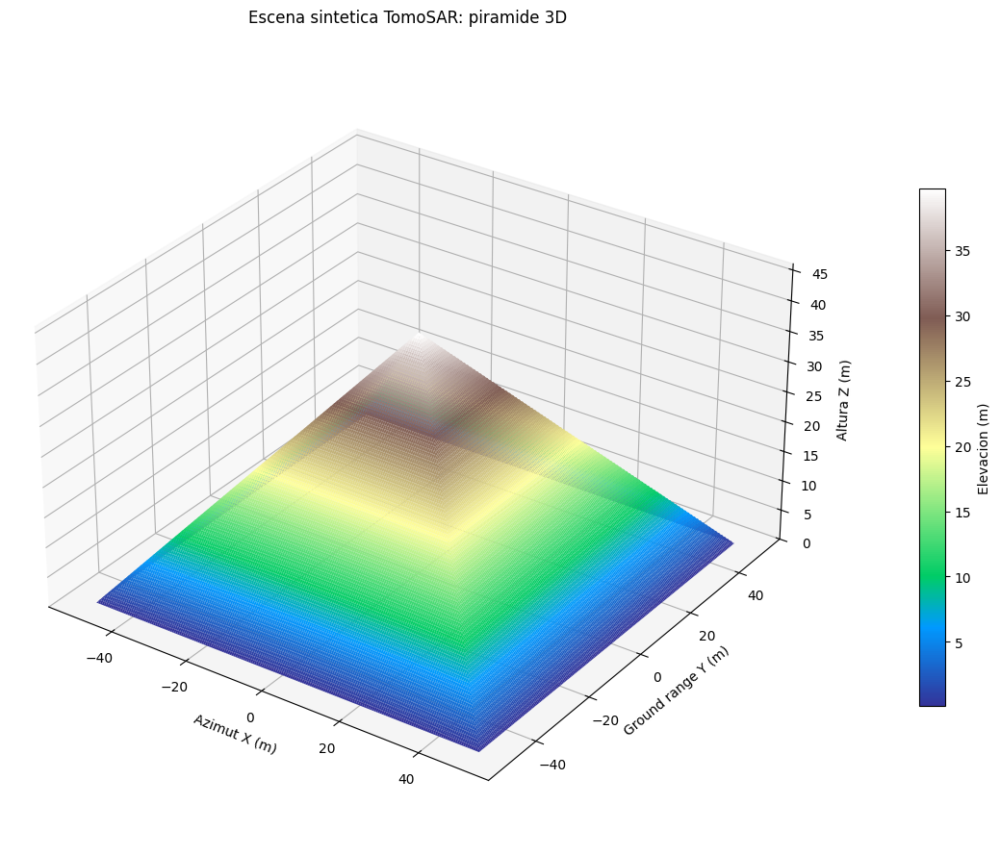

Escena generada correctamente.
Altura maxima: 40.00 m
Malla: 201 x 201
Archivos guardados en: /content/resultados_tomosar


In [ ]:
# ============================================================
# 1. PARAMETROS DE LA ESCENA SINTETICA
# ============================================================

# Dimensiones del terreno en metros
Lx = 100.0                 # Extension en azimut (m)
Ly = 100.0                 # Extension en ground range (m)
Hmax = 40.0                # Altura maxima de la piramide (m)

# Resolucion espacial de la superficie
Nx = 201
Ny = 201

# Directorio de salida
OUT = Path("resultados_tomosar")
OUT.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. GENERAR LA MALLA 3D
# ============================================================

x = np.linspace(-Lx / 2, Lx / 2, Nx)
y = np.linspace(-Ly / 2, Ly / 2, Ny)

X, Y = np.meshgrid(x, y)

# ============================================================
# 3. MODELO DE ELEVACION: PIRAMIDE DE BASE CUADRADA
# ============================================================

# Distancia normalizada al centro usando la norma infinito.
# Las cuatro caras son planas y se unen en el vertice.
r = np.maximum(np.abs(X) / (Lx / 2),
               np.abs(Y) / (Ly / 2))

Z = Hmax * np.maximum(0.0, 1.0 - r)

# ============================================================
# 4. VISUALIZACION 3D
# ============================================================

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

surface = ax.plot_surface(
    X, Y, Z,
    cmap="terrain",
    edgecolor="none",
    antialiased=True,
    rcount=Ny,
    ccount=Nx
)

# Etiquetas y titulo
ax.set_title("Escena sintetica TomoSAR: piramide 3D", pad=20)
ax.set_xlabel("Azimut X (m)")
ax.set_ylabel("Ground range Y (m)")
ax.set_zlabel("Altura Z (m)")

# Escala vertical y punto de vista
ax.set_zlim(0, Hmax * 1.15)
ax.set_box_aspect((Lx, Ly, Hmax * 1.5))
ax.view_init(elev=30, azim=-55)

# Barra de color
cbar = fig.colorbar(surface, ax=ax, shrink=0.65, pad=0.10)
cbar.set_label("Elevacion (m)")

plt.tight_layout()

# Guardar la figura
fig.savefig(
    OUT / "piramide_3D.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 5. GUARDAR EL GROUND TRUTH
# ============================================================

np.savez_compressed(
    OUT / "ground_truth_piramide.npz",
    X=X,
    Y=Y,
    Z=Z,
    x=x,
    y=y,
    Lx=Lx,
    Ly=Ly,
    Hmax=Hmax
)

print("Escena generada correctamente.")
print(f"Altura maxima: {Z.max():.2f} m")
print(f"Malla: {Nx} x {Ny}")
print(f"Archivos guardados en: {OUT.resolve()}")

In [ ]:
# ============================================================
# PARAMETROS FISICOS Y GEOMETRIA TOMOSAR - Función
# ============================================================

def generar_geometria_tomosar(
    terreno,
    wavelength,
    r_slant,
    theta_deg,
    N,
    b_n,
    L,
    s_min,
    s_max,
    out="resultados_tomosar",
    x_target=0.0,
    z_target=None,
    radar_x=-90.0,
    radar_z=65.0,
    mostrar=True,
    guardar=True,
):
    """
    Genera la geometría de adquisición TomoSAR y sus resultados.

    Parámetros
    ----------
    terreno : dict
        Puede ser uno de los siguientes formatos:

        1) Perfil 1D:
           {
               "x": vector de coordenadas horizontales,
               "z_profile": vector de alturas
           }

        2) Superficie 3D:
           {
               "X": matriz de coordenadas X,
               "Y": matriz de coordenadas Y,
               "Z": matriz de alturas
           }

        Para el formato 3D, se extrae el perfil central Y ~= 0.

        Opcionalmente, el diccionario puede incluir:
           "x_target": posición horizontal del punto observado
           "z_target": altura del punto observado
           "radar_x": posición horizontal del radar
           "radar_z": altura del radar

    wavelength : float
        Longitud de onda [m].

    r_slant : float
        Distancia oblicua nominal [m].

    theta_deg : float
        Ángulo de incidencia respecto a la vertical [grados].

    N : int
        Número de adquisiciones.

    b_n : array-like
        Baselines perpendiculares [m], uno por adquisición.

    L : int
        Número de bins verticales.

    s_min, s_max : float
        Límites inferior y superior del grid de alturas [m].

    out : str o Path
        Directorio para guardar los resultados.

    x_target, z_target : float
        Coordenadas del punto observado. Si z_target es None,
        se estima usando el perfil del terreno.

    radar_x, radar_z : float
        Posición esquemática del radar en la primera figura.

    mostrar : bool
        Si True, muestra las figuras.

    guardar : bool
        Si True, guarda las figuras y el archivo NPZ.

    Retorna
    -------
    dict
        Parámetros físicos, grid vertical, kz, R, figuras
        y rutas de salida.
    """

    # ========================================================
    # 1. VALIDAR LOS PARÁMETROS
    # ========================================================

    b_n = np.asarray(b_n, dtype=float)

    if N != len(b_n):
        raise ValueError(
            f"N={N}, pero b_n contiene {len(b_n)} baselines."
        )

    if N < 1:
        raise ValueError("N debe ser mayor o igual que 1.")

    if L < 2:
        raise ValueError("L debe ser mayor o igual que 2.")

    if wavelength <= 0 or r_slant <= 0:
        raise ValueError(
            "wavelength y r_slant deben ser positivos."
        )

    if not (0 < theta_deg < 90):
        raise ValueError(
            "theta_deg debe estar entre 0 y 90 grados."
        )

    if s_max <= s_min:
        raise ValueError("s_max debe ser mayor que s_min.")

    theta = np.deg2rad(theta_deg)

    # ========================================================
    # 2. GRID VERTICAL Y MATRIZ DE ADQUISICIÓN
    # ========================================================

    s = np.linspace(s_min, s_max, L)
    delta_s = s[1] - s[0]

    # Número de onda vertical para cada adquisición
    kz = (
        (4.0 * np.pi / wavelength)
        * b_n
        / (r_slant * np.sin(theta))
    )

    delta_kz = kz.max() - kz.min()

    # Resolución vertical teórica aproximada
    rho_z = (
        2.0 * np.pi / delta_kz
        if delta_kz > 0
        else np.inf
    )

    # R[n,l] = exp(-j * kz[n] * s[l])
    R = np.exp(-1j * np.outer(kz, s))

    # ========================================================
    # 3. INTERPRETAR EL GROUND TRUTH DEL TERRENO
    # ========================================================

    if not isinstance(terreno, dict):
        raise TypeError(
            "terreno debe ser un diccionario con x/z_profile "
            "o X/Y/Z."
        )

    if "x" in terreno and "z_profile" in terreno:

        # Caso A: perfil de terreno 1D
        x = np.asarray(terreno["x"], dtype=float)
        z_profile = np.asarray(
            terreno["z_profile"], dtype=float
        )

    elif all(k in terreno for k in ("X", "Y", "Z")):

        # Caso B: superficie 3D
        X = np.asarray(terreno["X"], dtype=float)
        Y = np.asarray(terreno["Y"], dtype=float)
        Z = np.asarray(terreno["Z"], dtype=float)

        if not (X.shape == Y.shape == Z.shape):
            raise ValueError(
                "Las matrices X, Y y Z deben tener la misma forma."
            )

        if X.ndim != 2:
            raise ValueError(
                "X, Y y Z deben ser matrices bidimensionales."
            )

        # Buscar la fila más próxima a Y = 0.
        y_por_fila = np.mean(Y, axis=1)
        fila_central = np.argmin(np.abs(y_por_fila))

        x = X[fila_central, :]
        z_profile = Z[fila_central, :]

    else:
        raise ValueError(
            "Formato de terreno no reconocido. Usa "
            "{'x', 'z_profile'} o {'X', 'Y', 'Z'}."
        )

    if x.ndim != 1 or z_profile.ndim != 1:
        raise ValueError(
            "El perfil extraído debe contener vectores 1D."
        )

    if len(x) != len(z_profile) or len(x) < 2:
        raise ValueError(
            "x y z_profile deben tener la misma longitud "
            "y al menos dos puntos."
        )

    if not (
        np.all(np.isfinite(x))
        and np.all(np.isfinite(z_profile))
    ):
        raise ValueError(
            "El perfil del terreno contiene valores no finitos."
        )

    # Permitir sobrescribir las posiciones desde el diccionario.
    x_target = terreno.get("x_target", x_target)
    z_target = terreno.get("z_target", z_target)
    radar_x = terreno.get("radar_x", radar_x)
    radar_z = terreno.get("radar_z", radar_z)

    # Si no se especifica la altura del punto observado,
    # interpolarla sobre el perfil del terreno.
    if z_target is None:
        z_target = np.interp(
            x_target,
            np.sort(x),
            z_profile[np.argsort(x)]
        )

    # ========================================================
    # 4. FIGURA 1: TERRENO Y GEOMETRÍA DE ADQUISICIÓN
    # ========================================================

    fig1, (ax1, ax2) = plt.subplots(
        1, 2, figsize=(15, 6)
    )

    # Panel A: perfil, punto objetivo y línea de visión
    ax1.fill_between(
        x,
        0,
        z_profile,
        color="darkseagreen",
        alpha=0.8,
        label="Superficie del terreno",
    )

    ax1.plot(
        x,
        z_profile,
        color="darkgreen",
        linewidth=2,
    )

    ax1.scatter(
        x_target,
        z_target,
        color="red",
        s=65,
        zorder=5,
        label="Punto observado",
    )

    ax1.scatter(
        radar_x,
        radar_z,
        marker="^",
        s=120,
        color="royalblue",
        label="Radar de referencia",
    )

    ax1.plot(
        [radar_x, x_target],
        [radar_z, z_target],
        linestyle="--",
        color="royalblue",
        linewidth=1.8,
        label="Línea de visión (LOS)",
    )

    ax1.set_title("A. Escena y línea de visión")
    ax1.set_xlabel("Ground range (m)")
    ax1.set_ylabel("Altura (m)")
    ax1.grid(True, alpha=0.3)
    ax1.legend(fontsize=8, loc="best")

    # Límites automáticos que incluyen terreno y radar.
    ax1.set_xlim(
        min(x.min(), radar_x, x_target) - 5,
        max(x.max(), radar_x, x_target) + 5,
    )

    y_min = min(0.0, z_profile.min(), z_target)
    y_max = max(z_profile.max(), radar_z, z_target)

    ax1.set_ylim(
        y_min - 0.05 * max(y_max - y_min, 1),
        y_max + 0.10 * max(y_max - y_min, 1),
    )

    # Panel B: distribución conceptual de baselines
    sensor_z = radar_z

    ax2.axvline(
        0,
        color="gray",
        linestyle=":",
        label="Baseline de referencia b = 0",
    )

    ax2.scatter(
        0,
        z_target,
        color="red",
        s=80,
        zorder=5,
        label="Punto observado",
    )

    for i, b in enumerate(b_n):
        ax2.scatter(
            b,
            sensor_z,
            marker="^",
            s=90,
            color="royalblue",
            zorder=4,
        )

        ax2.plot(
            [b, 0],
            [sensor_z, z_target],
            linestyle="--",
            linewidth=0.9,
            alpha=0.65,
            color="royalblue",
        )

        ax2.annotate(
            f"T{i+1}\nb={b:.0f} m",
            (b, sensor_z),
            xytext=(0, 9),
            textcoords="offset points",
            ha="center",
            fontsize=7,
        )

    ax2.set_title("B. Adquisiciones y baselines")
    ax2.set_xlabel("Baseline relativo (m)")
    ax2.set_ylabel("Altura esquemática (m)")
    ax2.set_xlim(
        min(b_n.min(), 0) - 15,
        max(b_n.max(), 0) + 15,
    )
    ax2.set_ylim(
        min(0, z_target) - 5,
        max(sensor_z, z_target) + 20,
    )
    ax2.grid(True, alpha=0.3)
    ax2.legend(fontsize=8, loc="best")

    fig1.suptitle(
        "Geometría de adquisición TomoSAR",
        fontsize=14,
    )

    fig1.text(
        0.5,
        0.01,
        "Esquema conceptual, no a escala. "
        "La geometría orbital y la incidencia definen las observaciones SAR.",
        ha="center",
        fontsize=9,
    )

    fig1.tight_layout(rect=[0, 0.05, 1, 0.93])

    # ========================================================
    # 5. FIGURA 2: BASELINES, kz Y FASE DE R
    # ========================================================

    fig2, axes = plt.subplots(
        1, 3, figsize=(17, 5)
    )

    # A. Baselines
    axes[0].scatter(
        b_n,
        np.arange(1, N + 1),
        s=70,
    )

    axes[0].axvline(
        0,
        color="gray",
        linestyle="--",
    )

    axes[0].set_xlabel("Baseline perpendicular (m)")
    axes[0].set_ylabel("Adquisición")
    axes[0].set_title("A. Distribución de baselines")
    axes[0].set_yticks(np.arange(1, N + 1))
    axes[0].grid(True, alpha=0.3)

    for i in range(N):
        axes[0].annotate(
            f"{b_n[i]:.0f} m",
            (b_n[i], i + 1),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8,
        )

    # B. Número de onda vertical
    axes[1].stem(
        np.arange(1, N + 1),
        kz,
    )

    axes[1].set_xlabel("Adquisición")
    axes[1].set_ylabel(r"$k_z$ (rad/m)")
    axes[1].set_title("B. Número de onda vertical")
    axes[1].set_xticks(np.arange(1, N + 1))
    axes[1].grid(True, alpha=0.3)

    # C. Fase de la matriz R
    phase_R = np.angle(R)

    im = axes[2].imshow(
        phase_R,
        aspect="auto",
        origin="lower",
        extent=[
            s[0],
            s[-1],
            0.5,
            N + 0.5,
        ],
        cmap="twilight",
        vmin=-np.pi,
        vmax=np.pi,
    )

    axes[2].set_xlabel("Altura s (m)")
    axes[2].set_ylabel("Adquisición")
    axes[2].set_yticks(np.arange(1, N + 1))
    axes[2].set_title(r"C. Fase de $R_{n,l}$")

    cbar = fig2.colorbar(
        im,
        ax=axes[2],
    )

    cbar.set_label("Fase (rad)")

    fig2.tight_layout()

    # ========================================================
    # 6. GUARDAR RESULTADOS
    # ========================================================

    out = Path(out)
    rutas = {}

    if guardar:
        out.mkdir(
            parents=True,
            exist_ok=True,
        )

        ruta_fig1 = out / "geometria_tomosar_2D.png"
        ruta_fig2 = out / "geometria_adquisicion.png"
        ruta_npz = out / "geometria_tomosar.npz"

        fig1.savefig(
            ruta_fig1,
            dpi=300,
            bbox_inches="tight",
        )

        fig2.savefig(
            ruta_fig2,
            dpi=300,
            bbox_inches="tight",
        )

        np.savez_compressed(
            ruta_npz,
            wavelength=wavelength,
            r_slant=r_slant,
            theta_deg=theta_deg,
            N=N,
            b_n=b_n,
            kz=kz,
            s=s,
            R=R,
            delta_s=delta_s,
            delta_kz=delta_kz,
            rho_z=rho_z,
            x=x,
            z_profile=z_profile,
            x_target=x_target,
            z_target=z_target,
        )

        rutas = {
            "figura_geometria": ruta_fig1,
            "figura_adquisicion": ruta_fig2,
            "archivo_npz": ruta_npz,
        }

    # ========================================================
    # 7. RESUMEN DE PARÁMETROS
    # ========================================================

    print("========== GEOMETRÍA Y PARÁMETROS TOMOSAR ==========")
    print(f"Longitud de onda: {wavelength:.4f} m")
    print(f"Distancia oblicua nominal: {r_slant:.1f} m")
    print(f"Ángulo de incidencia: {theta_deg:.1f} grados")
    print(f"Número de adquisiciones: {N}")
    print(
        f"Baseline mínimo: {b_n.min():.1f} m | "
        f"Máximo: {b_n.max():.1f} m"
    )
    print(f"Número de bins verticales: {L}")
    print(f"Intervalo de alturas: [{s.min():.3f}, {s.max():.3f}] m")
    print(f"Separación entre bins (delta_s): {delta_s:.3f} m")
    print(f"Extensión de kz (delta_kz): {delta_kz:.6f} rad/m")

    if np.isfinite(rho_z):
        print(
            f"Resolución vertical aproximada (rho_z): "
            f"{rho_z:.3f} m"
        )
    else:
        print("Resolución vertical aproximada: infinita (delta_kz = 0)")

    print("Forma de la matriz R:", R.shape)

    print("\nBaselines [m] y kz [rad/m]:")
    for i in range(N):
        print(
            f"  Adquisición {i+1}: "
            f"b = {b_n[i]:7.2f} m | "
            f"kz = {kz[i]: .6f} rad/m"
        )

    if guardar:
        print("\nArchivos guardados:")
        for nombre, ruta in rutas.items():
            print(f"  {nombre}: {ruta}")

    if mostrar:
        plt.show()
    else:
        plt.close(fig1)
        plt.close(fig2)

    # ========================================================
    # 8. DEVOLVER RESULTADOS PARA OTRAS FUNCIONES
    # ========================================================

    return {
        "wavelength": wavelength,
        "r_slant": r_slant,
        "theta_deg": theta_deg,
        "theta": theta,
        "N": N,
        "b_n": b_n,
        "L": L,
        "s_min": s_min,
        "s_max": s_max,
        "s": s,
        "delta_s": delta_s,
        "kz": kz,
        "delta_kz": delta_kz,
        "rho_z": rho_z,
        "R": R,
        "x": x,
        "z_profile": z_profile,
        "x_target": x_target,
        "z_target": z_target,
        "fig1": fig1,
        "fig2": fig2,
        "rutas": rutas,
    }

========== GEOMETRÍA Y PARÁMETROS TOMOSAR ==========
Longitud de onda: 0.0300 m
Distancia oblicua nominal: 10000.0 m
Ángulo de incidencia: 35.0 grados
Número de adquisiciones: 8
Baseline mínimo: -45.0 m | Máximo: 46.0 m
Número de bins verticales: 121
Intervalo de alturas: [-10.000, 50.000] m
Separación entre bins (delta_s): 0.500 m
Extensión de kz (delta_kz): 6.645669 rad/m
Resolución vertical aproximada (rho_z): 0.945 m
Forma de la matriz R: (8, 121)

Baselines [m] y kz [rad/m]:
  Adquisición 1: b =  -45.00 m | kz = -3.286320 rad/m
  Adquisición 2: b =  -32.00 m | kz = -2.336939 rad/m
  Adquisición 3: b =  -21.00 m | kz = -1.533616 rad/m
  Adquisición 4: b =   -8.00 m | kz = -0.584235 rad/m
  Adquisición 5: b =    0.00 m | kz =  0.000000 rad/m
  Adquisición 6: b =   13.00 m | kz =  0.949381 rad/m
  Adquisición 7: b =   27.00 m | kz =  1.971792 rad/m
  Adquisición 8: b =   46.00 m | kz =  3.359349 rad/m

Archivos guardados:
  figura_geometria: resultados_tomosar/geometria_tomosar_2D.pn

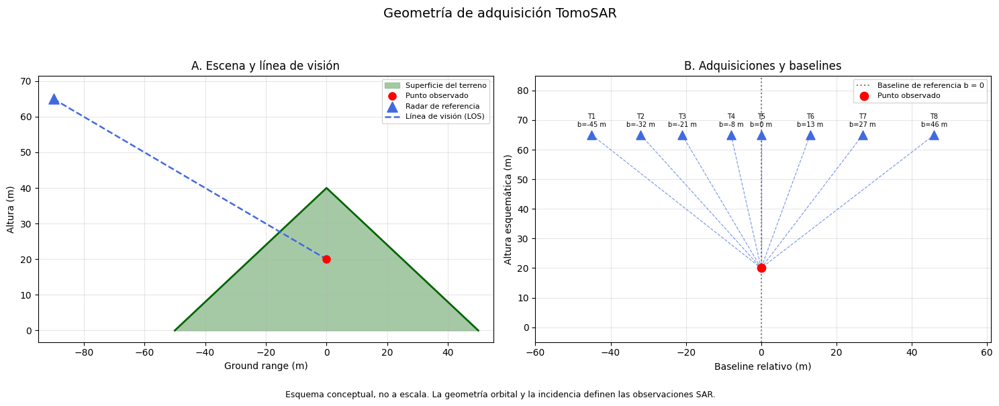

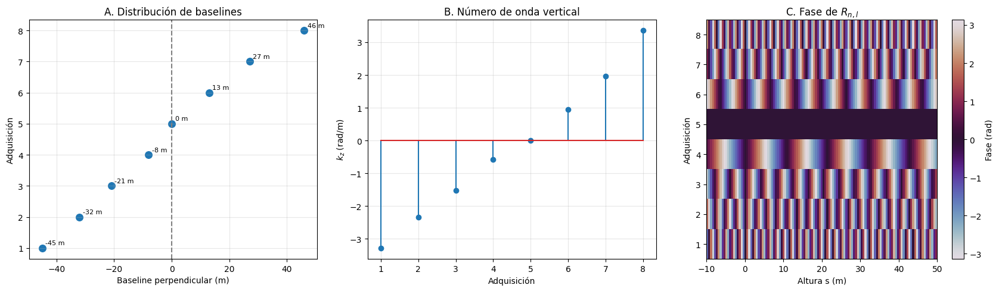

In [ ]:
# ============================================================
# DEFINIR EL GROUND TRUTH: PIRÁMIDE
# ============================================================

Lx = 100.0
Hmax = 40.0

x = np.linspace(-Lx / 2, Lx / 2, 501)

z_profile = Hmax * np.maximum(
    0.0,
    1.0 - np.abs(x) / (Lx / 2)
)

terreno = {
    "x": x,
    "z_profile": z_profile,
    "x_target": 0.0,
    "z_target": 20.0,
    "radar_x": -90.0,
    "radar_z": 65.0,
}

# ============================================================
# PARÁMETROS TOMOSAR
# ============================================================

wavelength = 0.03
r_slant = 10000.0
theta_deg = 35.0

N = 8

b_n = np.array(
    [-45, -32, -21, -8, 0, 13, 27, 46],
    dtype=float
)

L = 121
s_min = -10.0
s_max = 50.0

# ============================================================
# GENERAR TODA LA GEOMETRÍA
# ============================================================

resultado = generar_geometria_tomosar(
    terreno=terreno,
    wavelength=wavelength,
    r_slant=r_slant,
    theta_deg=theta_deg,
    N=N,
    b_n=b_n,
    L=L,
    s_min=s_min,
    s_max=s_max,
    out="resultados_tomosar",
    mostrar=True,
    guardar=True,
)

========== DATASET TOMOSAR ==========
R: (8, 121)
G_center: (8, 51, 51)
G_looks: (25, 8, 51, 51)
C: (51, 51, 8, 8)
gamma_gt: (121, 51, 51)
Z_gt: (51, 51)
SNR configurado: 40.0 dB
Numero de looks: 25
Grid vertical: 121 bins
Altura minima real: 0.00 m
Altura maxima real: 40.00 m
Error de hermiticidad: 0.0
Autovalores de C en el centro: [3.1627507e-05 4.4432127e-05 8.2394436e-05 9.2149719e-05 1.0666455e-04
 1.5639530e-04 2.0422740e-04 1.1166909e+01]


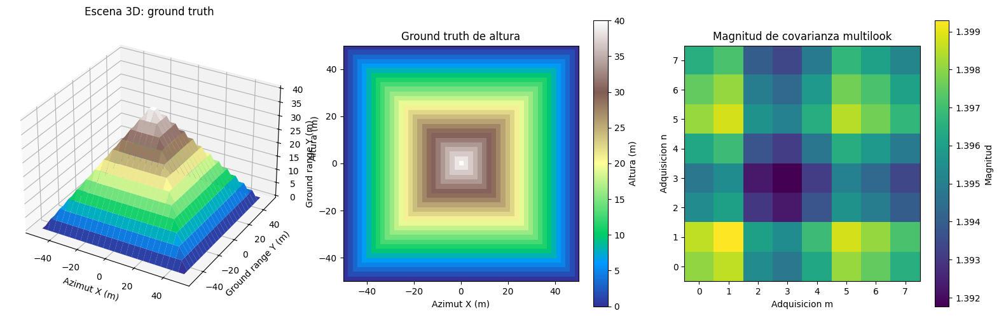


Dataset guardado correctamente en: resultados_tomosar/dataset_piramide_tomosar.npz


In [ ]:
# ============================================================
# 1. ESCENA ESPACIAL 3D: PIRAMIDE
# ============================================================

Lx, Ly = 100.0, 100.0
Hmax = 40.0
Nx, Ny = 51, 51

x = np.linspace(-Lx / 2, Lx / 2, Nx)
y = np.linspace(-Ly / 2, Ly / 2, Ny)
X, Y = np.meshgrid(x, y)

# Pirámide de base cuadrada
r = np.maximum(np.abs(X) / (Lx / 2), np.abs(Y) / (Ly / 2))
Z_gt = Hmax * np.maximum(0.0, 1.0 - r)

# ============================================================
# 2. GROUND TRUTH DE REFLECTIVIDAD
# ============================================================

# Asignar cada altura al bin vertical más cercano
idx_z = np.abs(Z_gt[..., None] - s[None, None, :]).argmin(axis=-1)

# Reflectividad compleja verdadera (un reflector dominante por píxel)
gamma_gt = np.zeros((L, Ny, Nx), dtype=np.complex64)
for iy in range(Ny):
  for ix in range(Nx):
    gamma_gt[idx_z[iy, ix], iy, ix] = 1.0 + 0.0j

# Altura cuantizada
Z_grid_gt = s[idx_z]

# ============================================================
# 3. GENERACION DE ADQUISICIONES SINTETICAS
# ============================================================

N_LOOKS = 25
SNR_DB = 40.0
SEMILLA = 42

rng = np.random.default_rng(SEMILLA)

# Respuesta compleja: exp(-j * kz_n * altura_pixel)
A = np.exp(-1j * kz[:, None, None] * Z_grid_gt[None, :, :])

# Potencia de ruido por adquisición
noise_power = 10.0 ** (-SNR_DB / 10.0)

# Coeficiente complejo por look
alpha = (
    rng.standard_normal((N_LOOKS, Ny, Nx))
    + 1j * rng.standard_normal((N_LOOKS, Ny, Nx))
) / np.sqrt(2.0)

# Ruido complejo circular
noise = np.sqrt(noise_power / 2.0) * (
    rng.standard_normal((N_LOOKS, N, Ny, Nx))
    + 1j * rng.standard_normal((N_LOOKS, N, Ny, Nx))
)

# Adquisiciones sintéticas
G_looks = (alpha[:, None, :, :] * A[None, :, :, :] + noise).astype(np.complex64)
G_center = G_looks[0].copy()

# ============================================================
# 4. COVARIANZA MULTILOOK
# ============================================================

C = (
    np.einsum(
        "knyx,kmyx->yxnm", G_looks, np.conj(G_looks), optimize=True
    )
    / N_LOOKS
)
C = C.astype(np.complex64)

# ============================================================
# 5. DIAGNOSTICOS
# ============================================================

print("========== DATASET TOMOSAR ==========")
print("R:", R.shape)
print("G_center:", G_center.shape)
print("G_looks:", G_looks.shape)
print("C:", C.shape)
print("gamma_gt:", gamma_gt.shape)
print("Z_gt:", Z_gt.shape)

print(f"SNR configurado: {SNR_DB:.1f} dB")
print(f"Numero de looks: {N_LOOKS}")
print(f"Grid vertical: {L} bins")
print(f"Altura minima real: {Z_gt.min():.2f} m")
print(f"Altura maxima real: {Z_gt.max():.2f} m")

# Verificar hermiticidad de la covarianza en el centro
iy0, ix0 = Ny // 2, Nx // 2
C0 = C[iy0, ix0]

print("Error de hermiticidad:", np.max(np.abs(C0 - C0.conj().T)))
print("Autovalores de C en el centro:", np.linalg.eigvalsh(C0))

# ============================================================
# 6. VISUALIZACION DE LA ESCENA Y LOS DATOS
# ============================================================

fig = plt.figure(figsize=(16, 5))

# A. Pirámide 3D
ax1 = fig.add_subplot(131, projection="3d")
surf = ax1.plot_surface(X, Y, Z_gt, cmap="terrain", edgecolor="none")
ax1.set_title("Escena 3D: ground truth")
ax1.set_xlabel("Azimut X (m)")
ax1.set_ylabel("Ground range Y (m)")
ax1.set_zlabel("Altura (m)")
ax1.set_box_aspect((1, 1, 0.7))

# B. Mapa de alturas
ax2 = fig.add_subplot(132)
im2 = ax2.imshow(
    Z_gt,
    origin="lower",
    extent=[x.min(), x.max(), y.min(), y.max()],
    cmap="terrain",
    aspect="equal",
)
ax2.set_title("Ground truth de altura")
ax2.set_xlabel("Azimut X (m)")
ax2.set_ylabel("Ground range Y (m)")
fig.colorbar(im2, ax=ax2, label="Altura (m)")

# C. Covarianza multilook de un píxel
ax3 = fig.add_subplot(133)
im3 = ax3.imshow(np.abs(C0), origin="lower", cmap="viridis")
ax3.set_title("Magnitud de covarianza multilook")
ax3.set_xlabel("Adquisicion m")
ax3.set_ylabel("Adquisicion n")
fig.colorbar(im3, ax=ax3, label="Magnitud")

plt.tight_layout()

# ============================================================
# 7. GUARDAR EL DATASET COMPLETO
# ============================================================

np.savez_compressed(
    out / "dataset_piramide_tomosar.npz",
    wavelength=wavelength,
    r_slant=r_slant,
    theta_deg=theta_deg,
    b_n=b_n,
    kz=kz,
    s=s,
    R=R,
    X=X,
    Y=Y,
    Z_gt=Z_gt,
    Z_grid_gt=Z_grid_gt,
    idx_z=idx_z,
    gamma_gt=gamma_gt,
    G_center=G_center,
    G_looks=G_looks,
    C=C,
    N_LOOKS=N_LOOKS,
    SNR_DB=SNR_DB,
    SEMILLA=SEMILLA,
)

fig.savefig(out / "diagnostico_dataset.png", dpi=250, bbox_inches="tight")
plt.show()

print("\nDataset guardado correctamente en:", out / "dataset_piramide_tomosar.npz")

Dimensiones de R: (8, 121)
Dimensiones de g: (8,)
Dimensiones de C_pixel: (8, 8)
Altura verdadera discretizada: 40.00 m
Altura original: 40.00 m
SNR configurada: 40.0 dB
Número de looks: 25


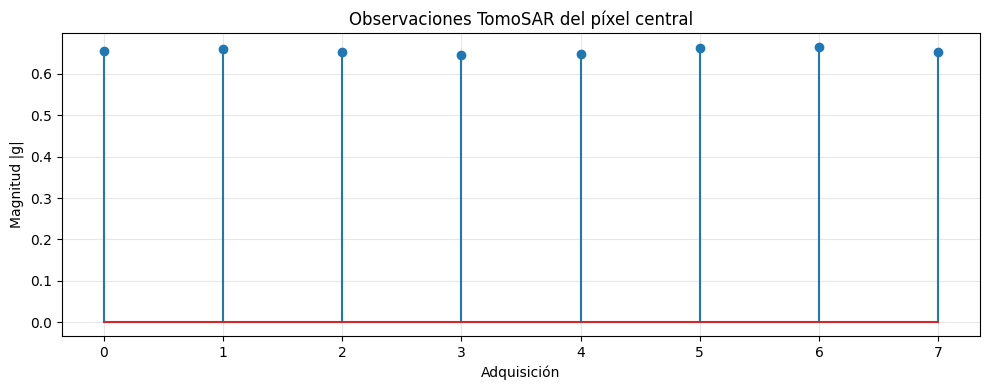

In [ ]:
# ============================================================
# CARGA DEL DATASET TOMOSAR
# ============================================================
archivo = Path("resultados_tomosar/dataset_piramide_tomosar.npz")
data = np.load(archivo)

R = data["R"]                       # Matriz de medición: (N, L)
s = data["s"]                       # Rejilla de alturas (m)
kz = data["kz"]                     # Frecuencias verticales
C = data["C"]                       # Covarianza por píxel
G_center = data["G_center"]         # Adquisición compleja

Z_grid_gt = data["Z_grid_gt"]       # Ground truth discretizado
Z_gt = data["Z_gt"]                 # Superficie original

# Seleccionar el píxel central
iy, ix = Z_gt.shape[0] // 2, Z_gt.shape[1] // 2

# Vector de observaciones del píxel seleccionado
g = G_center[:, iy, ix]

# Matriz de covarianza del píxel
C_pixel = C[iy, ix, :, :].astype(np.complex128)

# Altura verdadera
z_true = Z_grid_gt[iy, ix]

print("Dimensiones de R:", R.shape)
print("Dimensiones de g:", g.shape)
print("Dimensiones de C_pixel:", C_pixel.shape)
print(f"Altura verdadera discretizada: {z_true:.2f} m")
print(f"Altura original: {Z_gt[iy, ix]:.2f} m")
print(f"SNR configurada: {float(data['SNR_DB']):.1f} dB")
print(f"Número de looks: {int(data['N_LOOKS'])}")

# Visualizar las observaciones complejas
plt.figure(figsize=(10, 4))
plt.stem(np.arange(len(g)), np.abs(g))
plt.xlabel("Adquisición")
plt.ylabel("Magnitud |g|")
plt.title("Observaciones TomoSAR del píxel central")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Ground truth: 40.00 m
---------------------------------------------
CAPON   : altura =   40.00 m | error =   0.00 m
MUSIC   : altura =   40.00 m | error =   0.00 m
FISTA   : altura =   40.00 m | error =   0.00 m
ADMM    : altura =   40.00 m | error =   0.00 m


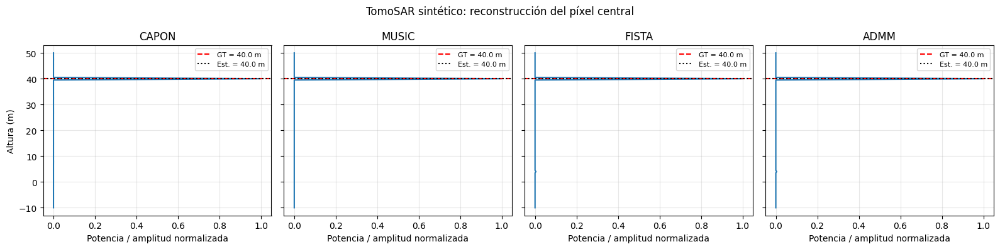

In [ ]:
# ============================================================
# 1. CAPON
# P(s) = 1 / (a(s)^H C^(-1) a(s))
# ============================================================
def capon(R, C, diagonal_loading=1e-3):
    N = C.shape[0]
    escala = np.real(np.trace(C)) / N
    C_reg = C + diagonal_loading * max(escala, 1e-12) * np.eye(N)

    # R[:, j] es el vector de dirección para la altura s[j]
    C_inv_R = np.linalg.solve(C_reg, R)
    denominador = np.real(np.sum(np.conj(R) * C_inv_R, axis=0))
    return 1.0 / np.maximum(denominador, 1e-12)


# ============================================================
# 2. MUSIC
# Un reflector dominante: n_sources = 1
# P(s) = 1 / ||En^H a(s)||^2
# ============================================================
def music(R, C, n_sources=1):
    C_herm = (C + C.conj().T) / 2
    eigenvalues, eigenvectors = np.linalg.eigh(C_herm)

    # eigh ordena de menor a mayor
    En = eigenvectors[:, :C.shape[0] - n_sources]
    proyeccion = En.conj().T @ R
    denominador = np.sum(np.abs(proyeccion)**2, axis=0)

    return 1.0 / np.maximum(denominador, 1e-12)


# ============================================================
# 3. FISTA-L1
# min_x 0.5 ||R x - g||_2^2 + lambda ||x||_1
# ============================================================
def soft_threshold_complex(x, threshold):
    magnitud = np.abs(x)
    factor = np.maximum(0.0, 1.0 - threshold / np.maximum(magnitud, 1e-12))
    return factor * x


def fista_l1(R, g, lam=0.05, n_iter=1000, tol=1e-7):
    RH = R.conj().T
    L_lipschitz = np.linalg.norm(R, ord=2)**2
    L_lipschitz = max(L_lipschitz, 1e-12)

    x = np.zeros(R.shape[1], dtype=np.complex128)
    y = x.copy()
    t = 1.0

    for _ in range(n_iter):
        grad = RH @ (R @ y - g)
        x_new = soft_threshold_complex(
            y - grad / L_lipschitz, lam / L_lipschitz
        )

        t_new = (1 + np.sqrt(1 + 4*t*t)) / 2
        y = x_new + ((t - 1) / t_new) * (x_new - x)

        if np.linalg.norm(x_new - x) / max(np.linalg.norm(x), 1e-12) < tol:
            x = x_new
            break

        x = x_new
        t = t_new

    return x


# ============================================================
# 4. ADMM-L1
# min_x 0.5 ||R x - g||_2^2 + lambda ||x||_1
# ============================================================
def admm_l1(R, g, lam=0.05, rho=0.5, n_iter=1500, tol=1e-6):
    RH = R.conj().T
    A = RH @ R
    b = RH @ g
    M = A + rho * np.eye(R.shape[1], dtype=np.complex128)

    x = np.zeros(R.shape[1], dtype=np.complex128)
    z = np.zeros_like(x)
    u = np.zeros_like(x)

    for _ in range(n_iter):
        x = np.linalg.solve(M, b + rho * (z - u))
        z_old = z.copy()

        z = soft_threshold_complex(x + u, lam / rho)
        u = u + x - z

        primal = np.linalg.norm(x - z)
        dual = rho * np.linalg.norm(z - z_old)

        if primal < tol and dual < tol:
            break

    return z


# ============================================================
# EJECUCIÓN
# ============================================================
P_capon = capon(R, C_pixel)
P_music = music(R, C_pixel, n_sources=1)

gamma_fista = fista_l1(R, g, lam=0.05)
gamma_admm = admm_l1(R, g, lam=0.05, rho=0.5)

# Normalizar perfiles para comparar sus formas
def normalizar(p):
    p = np.abs(p)
    return p / max(np.max(p), 1e-12)

perfiles = {
    "CAPON": normalizar(P_capon),
    "MUSIC": normalizar(P_music),
    "FISTA": normalizar(gamma_fista),
    "ADMM": normalizar(gamma_admm),
}

# Altura correspondiente al máximo de cada perfil
resultados = {}
for nombre, perfil in perfiles.items():
    idx = np.argmax(perfil)
    z_est = s[idx]
    resultados[nombre] = z_est

print(f"Ground truth: {z_true:.2f} m")
print("-" * 45)
for nombre, z_est in resultados.items():
    print(
        f"{nombre:8s}: altura = {z_est:7.2f} m | "
        f"error = {abs(z_est-z_true):6.2f} m"
    )

# ============================================================
# VISUALIZACIÓN COMPARATIVA
# ============================================================
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)

for ax, (nombre, perfil) in zip(axes, perfiles.items()):
    ax.plot(perfil, s, linewidth=1.5)
    ax.axhline(z_true, color="red", linestyle="--",
               label=f"GT = {z_true:.1f} m")
    ax.axhline(resultados[nombre], color="black",
               linestyle=":", label=f"Est. = {resultados[nombre]:.1f} m")
    ax.set_title(nombre)
    ax.set_xlabel("Potencia / amplitud normalizada")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Altura (m)")
fig.suptitle("TomoSAR sintético: reconstrucción del píxel central")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# PREPARACIÓN COMÚN PARA LA RECONSTRUCCIÓN DE TODA LA ESCENA
# ============================================================
archivo = Path("resultados_tomosar/dataset_piramide_tomosar.npz")
data = np.load(archivo)

R = data["R"]                         # (N, L)
s = data["s"]                         # (L,)
kz = data["kz"]
C = data["C"]                         # (Ny, Nx, N, N)
G_center = data["G_center"]           # (N, Ny, Nx)
Z_gt = data["Z_gt"]                   # Superficie original
Z_grid_gt = data["Z_grid_gt"]         # Ground truth discretizado
X = data["X"]
Y = data["Y"]

N, L = R.shape
Ny, Nx = Z_grid_gt.shape
n_pixels = Ny * Nx

# Vector de observaciones: (N, número de píxeles)
G = G_center.reshape(N, -1).astype(np.complex128)

# Ground truth en formato vectorial
z_true = Z_grid_gt.ravel()

# Carpeta para guardar resultados
salida = Path("resultados_tomosar/reconstrucciones")
salida.mkdir(parents=True, exist_ok=True)

def evaluar_mapa(nombre, Z_est):
    """Calcula métricas de altura y grafica la reconstrucción."""
    error = Z_est - Z_grid_gt
    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error**2))

    print(f"\n--- {nombre} ---")
    print(f"MAE:  {mae:.3f} m")
    print(f"RMSE: {rmse:.3f} m")
    print(f"Error máximo absoluto: {np.max(np.abs(error)):.3f} m")

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    im0 = axes[0].imshow(
        Z_est, origin="lower",
        extent=[X.min(), X.max(), Y.min(), Y.max()],
        aspect="equal"
    )
    axes[0].set_title(f"{nombre}: altura estimada")
    axes[0].set_xlabel("X (m)")
    axes[0].set_ylabel("Y (m)")
    fig.colorbar(im0, ax=axes[0], label="Altura (m)")

    im1 = axes[1].imshow(
        Z_grid_gt, origin="lower",
        extent=[X.min(), X.max(), Y.min(), Y.max()],
        aspect="equal"
    )
    axes[1].set_title("Ground truth")
    axes[1].set_xlabel("X (m)")
    axes[1].set_ylabel("Y (m)")
    fig.colorbar(im1, ax=axes[1], label="Altura (m)")

    im2 = axes[2].imshow(
        np.abs(error), origin="lower",
        extent=[X.min(), X.max(), Y.min(), Y.max()],
        aspect="equal",
        cmap="magma"
    )
    axes[2].set_title("Error absoluto")
    axes[2].set_xlabel("X (m)")
    axes[2].set_ylabel("Y (m)")
    fig.colorbar(im2, ax=axes[2], label="Error (m)")

    plt.tight_layout()
    plt.show()

    np.savez_compressed(
        salida / f"{nombre.lower()}_resultado.npz",
        Z_est=Z_est,
        Z_grid_gt=Z_grid_gt,
        error=error,
        MAE=mae,
        RMSE=rmse
    )

print(f"Adquisiciones: {N}")
print(f"Número de alturas: {L}")
print(f"Escena: {Ny} x {Nx} = {n_pixels} píxeles")
print(f"R: {R.shape} | G: {G.shape} | C: {C.shape}")

Adquisiciones: 8
Número de alturas: 121
Escena: 51 x 51 = 2601 píxeles
R: (8, 121) | G: (8, 2601) | C: (51, 51, 8, 8)



--- CAPON ---
MAE:  0.000 m
RMSE: 0.000 m
Error máximo absoluto: 0.000 m


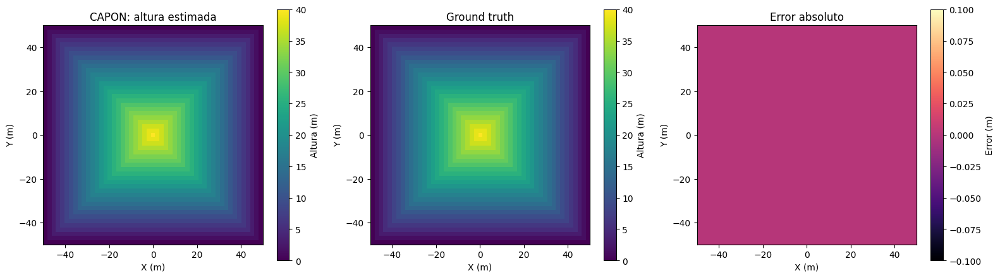

In [ ]:
# ============================================================
# CAPON
# P(s) = 1 / [a(s)^H C^(-1) a(s)]
# ============================================================

Z_capon = np.zeros((Ny, Nx), dtype=float)

# Parámetro de regularización de la covarianza
diagonal_loading = 1e-3

# Matriz de dirección para todas las alturas: (N, L)
A = R.astype(np.complex128)

for iy in range(Ny):
    for ix in range(Nx):
        C_pixel = C[iy, ix].astype(np.complex128)

        # Asegurar simetría hermítica
        C_pixel = (C_pixel + C_pixel.conj().T) / 2

        # Carga diagonal relativa a la potencia media
        escala = max(
            np.real(np.trace(C_pixel)) / N, 1e-12
        )
        C_reg = C_pixel + (
            diagonal_loading * escala * np.eye(N)
        )

        # Resolver C_reg @ Q = A
        Q = np.linalg.solve(C_reg, A)

        # a^H C^(-1) a para cada altura
        denominador = np.real(
            np.sum(np.conj(A) * Q, axis=0)
        )
        P = 1.0 / np.maximum(denominador, 1e-12)

        Z_capon[iy, ix] = s[np.argmax(P)]

evaluar_mapa("CAPON", Z_capon)


--- MUSIC ---
MAE:  0.000 m
RMSE: 0.000 m
Error máximo absoluto: 0.000 m


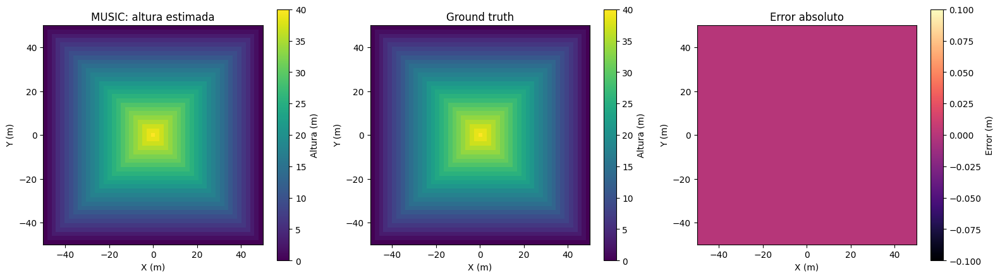

In [ ]:

# ============================================================
# MUSIC
# P(s) = 1 / ||En^H a(s)||^2
# n_sources = 1 reflector dominante
# ============================================================

Z_music = np.zeros((Ny, Nx), dtype=float)
n_sources = 1

for iy in range(Ny):
    for ix in range(Nx):
        C_pixel = C[iy, ix].astype(np.complex128)
        C_pixel = (C_pixel + C_pixel.conj().T) / 2

        # Autovalores ascendentes y autovectores asociados
        eigenvalues, eigenvectors = np.linalg.eigh(C_pixel)

        # Subespacio de ruido: autovectores de menor autovalor
        En = eigenvectors[:, :N - n_sources]

        # Proyección del vector de dirección sobre el ruido
        proyeccion = En.conj().T @ A
        denominador = np.sum(np.abs(proyeccion)**2, axis=0)

        P = 1.0 / np.maximum(denominador, 1e-12)
        Z_music[iy, ix] = s[np.argmax(P)]

evaluar_mapa("MUSIC", Z_music)

FISTA: iteraciones ejecutadas = 500
FISTA: lambda = 0.05

--- FISTA ---
MAE:  0.317 m
RMSE: 2.920 m
Error máximo absoluto: 44.500 m


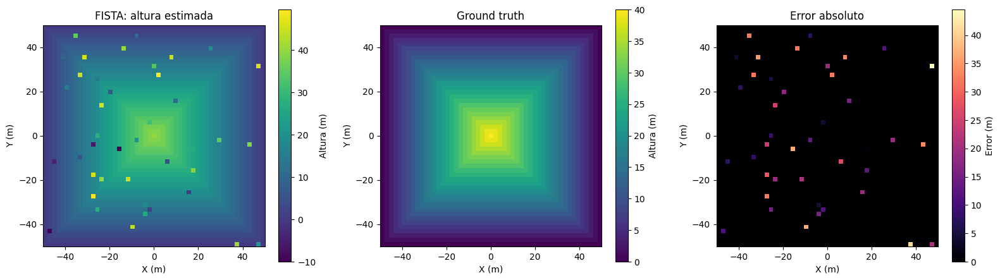

In [ ]:

# ============================================================
# FISTA-L1 PARA TODA LA ESCENA
# min_gamma 0.5||R gamma - G||_F^2 + lambda||gamma||_1
# ============================================================

def soft_threshold_complex(x, threshold):
    magnitude = np.abs(x)
    factor = np.maximum(
        0.0, 1.0 - threshold / np.maximum(magnitude, 1e-12)
    )
    return factor * x


lam_fista = 0.05
max_iter_fista = 500
tol_fista = 1e-6

RH = R.conj().T
L_lipschitz = np.linalg.norm(R, ord=2)**2

# Inicialización: (L, número de píxeles)
gamma = np.zeros((L, n_pixels), dtype=np.complex128)
y = gamma.copy()
t = 1.0

for it in range(max_iter_fista):
    grad = RH @ (R @ y - G)

    gamma_new = soft_threshold_complex(
        y - grad / L_lipschitz,
        lam_fista / L_lipschitz
    )

    t_new = (1 + np.sqrt(1 + 4*t*t)) / 2
    y = gamma_new + ((t - 1) / t_new) * (
        gamma_new - gamma
    )

    cambio = (
        np.linalg.norm(gamma_new - gamma)
        / max(np.linalg.norm(gamma), 1e-12)
    )

    gamma = gamma_new
    t = t_new

    if cambio < tol_fista:
        break

print(f"FISTA: iteraciones ejecutadas = {it + 1}")
print(f"FISTA: lambda = {lam_fista}")

# Estimar altura como la posición del máximo de |gamma|
idx_fista = np.argmax(np.abs(gamma), axis=0)
Z_fista = s[idx_fista].reshape(Ny, Nx)

evaluar_mapa("FISTA", Z_fista)


ADMM: iteraciones ejecutadas = 500
ADMM: lambda = 0.05, rho = 0.5

--- ADMM ---
MAE:  0.317 m
RMSE: 2.920 m
Error máximo absoluto: 44.500 m


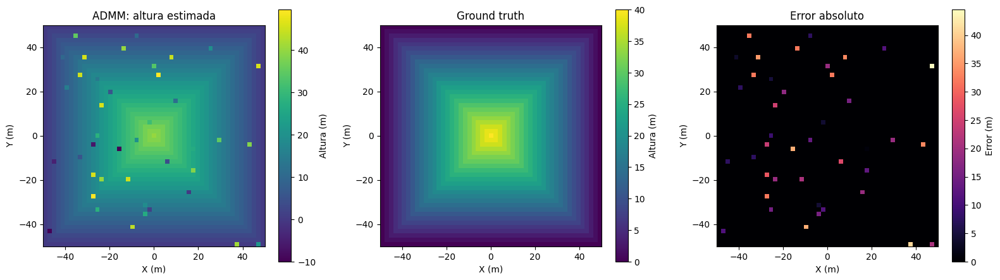

In [ ]:
# ============================================================
# ADMM-L1 PARA TODA LA ESCENA
# min_gamma 0.5||R gamma - G||_F^2 + lambda||gamma||_1
#
# gamma-update:
# (R^H R + rho I) gamma = R^H G + rho(z-u)
#
# z-update:
# z = soft_threshold(gamma+u, lambda/rho)
# ============================================================

lam_admm = 0.05
rho_admm = 0.5
max_iter_admm = 500
tol_admm = 1e-5

RH = R.conj().T
RtR = RH @ R
RtG = RH @ G

M = RtR + rho_admm * np.eye(L, dtype=np.complex128)

# La matriz M es constante: factorizar/invertir una sola vez
M_inv = np.linalg.solve(
    M, np.eye(L, dtype=np.complex128)
)

gamma = np.zeros((L, n_pixels), dtype=np.complex128)
z = np.zeros_like(gamma)
u = np.zeros_like(gamma)

for it in range(max_iter_admm):
    # Actualización de gamma
    gamma = M_inv @ (RtG + rho_admm * (z - u))

    # Actualización de z mediante umbralización compleja
    z_old = z.copy()
    z = soft_threshold_complex(
        gamma + u, lam_admm / rho_admm
    )

    # Actualización del multiplicador dual
    u = u + gamma - z

    # Criterios de convergencia
    residual_primal = np.linalg.norm(gamma - z)
    residual_dual = rho_admm * np.linalg.norm(z - z_old)

    if residual_primal < tol_admm and residual_dual < tol_admm:
        break

print(f"ADMM: iteraciones ejecutadas = {it + 1}")
print(f"ADMM: lambda = {lam_admm}, rho = {rho_admm}")

# Reconstrucción de altura por máximo de |gamma|
idx_admm = np.argmax(np.abs(z), axis=0)
Z_admm = s[idx_admm].reshape(Ny, Nx)

evaluar_mapa("ADMM", Z_admm)

In [ ]:
# ============================================================
# COMPARACIÓN GLOBAL DE LOS CUATRO MÉTODOS
# ============================================================

reconstrucciones = {
    "CAPON": Z_capon,
    "MUSIC": Z_music,
    "FISTA": Z_fista,
    "ADMM": Z_admm
}

print(f"{'Método':<10} {'MAE (m)':>12} {'RMSE (m)':>12}")
print("-" * 36)

for nombre, Z_est in reconstrucciones.items():
    error = Z_est - Z_grid_gt
    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error**2))
    print(f"{nombre:<10} {mae:>12.4f} {rmse:>12.4f}")

# Guardar todos los mapas juntos
np.savez_compressed(
    salida / "comparacion_todos_metodos.npz",
    Z_capon=Z_capon,
    Z_music=Z_music,
    Z_fista=Z_fista,
    Z_admm=Z_admm,
    Z_grid_gt=Z_grid_gt
)

Método          MAE (m)     RMSE (m)
------------------------------------
CAPON            0.0000       0.0000
MUSIC            0.0000       0.0000
FISTA            0.3172       2.9200
ADMM             0.3172       2.9200


In [ ]:

# ============================================================
# BÚSQUEDA DE LAMBDA PARA FISTA Y DE LAMBDA/RHO PARA ADMM
# Selección de parámetros con ground truth sintético
# ============================================================
# ------------------------------------------------------------
# 1. CONFIGURACIÓN DE LA BÚSQUEDA
# ------------------------------------------------------------
SEMILLA_BUSQUEDA = 123
N_PIXELES_VALIDACION = 128

# Valores candidatos de lambda
LAMBDA_GRID = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]

# Valores candidatos de rho para ADMM
RHO_GRID = [0.03, 0.1, 0.3, 1.0, 3.0, 10.0]

ITER_FISTA = 150
ITER_ADMM = 150

# ------------------------------------------------------------
# 2. SELECCIÓN DE PÍXELES DE VALIDACIÓN
# ------------------------------------------------------------
rng = np.random.default_rng(SEMILLA_BUSQUEDA)

n_total = G.shape[1]
n_val = min(N_PIXELES_VALIDACION, n_total)

idx_val = np.sort(
    rng.choice(n_total, size=n_val, replace=False)
)

G_val = G[:, idx_val]
z_val = Z_grid_gt.ravel()[idx_val]

print(f"Píxeles usados para ajustar parámetros: {n_val}")
print(f"Adquisiciones: {R.shape[0]}")
print(f"Alturas candidatas: {R.shape[1]}")

# ------------------------------------------------------------
# 3. PRECOMPUTAR MATRICES
# ------------------------------------------------------------
R_complex = R.astype(np.complex128)
RH = R_complex.conj().T

B = RH @ R_complex
B = (B + B.conj().T) / 2

b_val = RH @ G_val

L_lipschitz = np.linalg.norm(R_complex, ord=2)**2
L_lipschitz = max(L_lipschitz, 1e-12)

def soft_threshold_complex(x, threshold):
    mag = np.abs(x)
    return x * np.maximum(
        0.0, 1.0 - threshold / np.maximum(mag, 1e-12)
    )

def metricas_altura(gamma, z_real):
    """Altura estimada mediante el máximo de la reflectividad."""
    indices = np.argmax(np.abs(gamma), axis=0)
    z_est = s[indices]

    error = z_est - z_real

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error**2))

    return mae, rmse, z_est

# ------------------------------------------------------------
# 4. FISTA VECTORIAL PARA LOS PÍXELES DE VALIDACIÓN
# ------------------------------------------------------------
def ejecutar_fista(b, lam, n_iter=150):
    n_pix = b.shape[1]

    x = np.zeros((R.shape[1], n_pix), dtype=np.complex128)
    y = x.copy()
    t = 1.0

    for _ in range(n_iter):
        grad = B @ y - b

        x_new = soft_threshold_complex(
            y - grad / L_lipschitz,
            lam / L_lipschitz
        )

        t_new = (1 + np.sqrt(1 + 4*t*t)) / 2
        y = x_new + ((t - 1) / t_new) * (x_new - x)

        x = x_new
        t = t_new

    return x

# ------------------------------------------------------------
# 5. ADMM VECTORIAL PARA LOS PÍXELES DE VALIDACIÓN
# ------------------------------------------------------------
def ejecutar_admm(b, lam, rho, n_iter=150):
    n_pix = b.shape[1]
    L_alturas = R.shape[1]

    M = B + rho * np.eye(L_alturas, dtype=np.complex128)

    # Inversa calculada una sola vez por cada rho
    M_inv = np.linalg.solve(
        M, np.eye(L_alturas, dtype=np.complex128)
    )

    x = np.zeros((L_alturas, n_pix), dtype=np.complex128)
    z = np.zeros_like(x)
    u = np.zeros_like(x)

    for _ in range(n_iter):
        x = M_inv @ (b + rho * (z - u))

        z_old = z.copy()
        z = soft_threshold_complex(x + u, lam / rho)
        u = u + x - z

    return z

# ------------------------------------------------------------
# 6. BÚSQUEDA DE LAMBDA PARA FISTA
# ------------------------------------------------------------
resultados_fista = []

for lam in LAMBDA_GRID:
    gamma_val = ejecutar_fista(
        b_val, lam, n_iter=ITER_FISTA
    )

    mae, rmse, _ = metricas_altura(gamma_val, z_val)

    resultados_fista.append({
        "lambda": lam,
        "MAE_m": mae,
        "RMSE_m": rmse
    })

    print(
        f"FISTA | lambda={lam:7.4f} | "
        f"MAE={mae:6.3f} m | RMSE={rmse:6.3f} m"
    )

df_fista = pd.DataFrame(resultados_fista)
df_fista = df_fista.sort_values("RMSE_m").reset_index(drop=True)

lambda_fista_opt = float(df_fista.iloc[0]["lambda"])

print("\nMejor lambda para FISTA:")
print(df_fista.iloc[0].to_string())

# ------------------------------------------------------------
# 7. BÚSQUEDA DE LAMBDA Y RHO PARA ADMM
# ------------------------------------------------------------
resultados_admm = []

for lam in LAMBDA_GRID:
    for rho in RHO_GRID:
        gamma_val = ejecutar_admm(
            b_val, lam, rho, n_iter=ITER_ADMM
        )

        mae, rmse, _ = metricas_altura(gamma_val, z_val)

        resultados_admm.append({
            "lambda": lam,
            "rho": rho,
            "MAE_m": mae,
            "RMSE_m": rmse
        })

        print(
            f"ADMM | lambda={lam:7.4f} | rho={rho:5.2f} | "
            f"MAE={mae:6.3f} m | RMSE={rmse:6.3f} m"
        )

df_admm = pd.DataFrame(resultados_admm)
df_admm = df_admm.sort_values("RMSE_m").reset_index(drop=True)

lambda_admm_opt = float(df_admm.iloc[0]["lambda"])
rho_admm_opt = float(df_admm.iloc[0]["rho"])

print("\nMejor combinación observada para ADMM:")
print(df_admm.iloc[0].to_string())

# ------------------------------------------------------------
# 8. GUARDAR RESULTADOS
# ------------------------------------------------------------
salida = Path("resultados_tomosar/reconstrucciones")
salida.mkdir(parents=True, exist_ok=True)

df_fista.to_csv(salida / "busqueda_fista.csv", index=False)
df_admm.to_csv(salida / "busqueda_admm.csv", index=False)

print("\nParámetros seleccionados:")
print(f"FISTA: lambda = {lambda_fista_opt}")
print(f"ADMM:  lambda = {lambda_admm_opt}, rho = {rho_admm_opt}")

Píxeles usados para ajustar parámetros: 128
Adquisiciones: 8
Alturas candidatas: 121
FISTA | lambda= 0.0010 | MAE= 0.102 m | RMSE= 0.822 m
FISTA | lambda= 0.0030 | MAE= 0.102 m | RMSE= 0.822 m
FISTA | lambda= 0.0100 | MAE= 0.117 m | RMSE= 0.938 m
FISTA | lambda= 0.0300 | MAE= 0.117 m | RMSE= 0.938 m
FISTA | lambda= 0.1000 | MAE= 0.117 m | RMSE= 0.938 m
FISTA | lambda= 0.3000 | MAE= 0.102 m | RMSE= 0.822 m
FISTA | lambda= 1.0000 | MAE= 0.320 m | RMSE= 2.581 m

Mejor lambda para FISTA:
lambda    0.001000
MAE_m     0.101562
RMSE_m    0.822059
ADMM | lambda= 0.0010 | rho= 0.03 | MAE= 0.117 m | RMSE= 0.938 m
ADMM | lambda= 0.0010 | rho= 0.10 | MAE= 0.117 m | RMSE= 0.938 m
ADMM | lambda= 0.0010 | rho= 0.30 | MAE= 0.117 m | RMSE= 0.938 m
ADMM | lambda= 0.0010 | rho= 1.00 | MAE= 0.117 m | RMSE= 0.938 m
ADMM | lambda= 0.0010 | rho= 3.00 | MAE= 0.102 m | RMSE= 0.822 m
ADMM | lambda= 0.0010 | rho=10.00 | MAE= 0.102 m | RMSE= 0.822 m
ADMM | lambda= 0.0030 | rho= 0.03 | MAE= 0.117 m | RMSE= 0.938 m

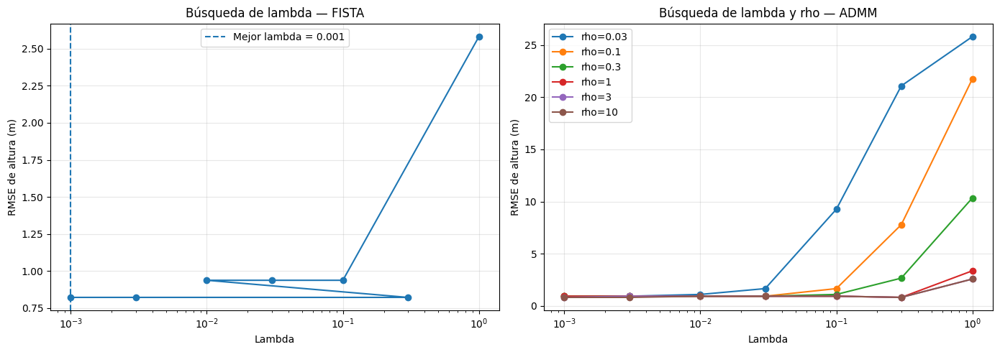

Mejores combinaciones de FISTA:


,lambda,MAE_m,RMSE_m
0,0.001,0.101562,0.822059
1,0.003,0.101562,0.822059
2,0.300,0.101562,0.822059
3,0.010,0.117188,0.937500
4,0.030,0.117188,0.937500


Mejores combinaciones de ADMM:


,lambda,rho,MAE_m,RMSE_m
0,0.001,10.00,0.101562,0.822059
1,0.001,3.00,0.101562,0.822059
2,0.003,10.00,0.101562,0.822059
3,0.300,1.00,0.101562,0.822059
4,0.300,3.00,0.101562,0.822059
5,0.300,10.00,0.101562,0.822059
6,0.001,1.00,0.117188,0.937500
7,0.001,0.03,0.117188,0.937500
8,0.003,0.10,0.117188,0.937500
9,0.003,0.30,0.117188,0.937500


In [ ]:

# ============================================================
# VISUALIZACIÓN DE LA BÚSQUEDA
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# FISTA: RMSE frente a lambda
axes[0].semilogx(
    df_fista["lambda"],
    df_fista["RMSE_m"],
    marker="o"
)
axes[0].axvline(
    lambda_fista_opt,
    linestyle="--",
    label=f"Mejor lambda = {lambda_fista_opt:g}"
)
axes[0].set_xlabel("Lambda")
axes[0].set_ylabel("RMSE de altura (m)")
axes[0].set_title("Búsqueda de lambda — FISTA")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# ADMM: curvas de RMSE frente a lambda para cada rho
for rho in RHO_GRID:
    subset = df_admm[df_admm["rho"] == rho].sort_values("lambda")

    axes[1].semilogx(
        subset["lambda"],
        subset["RMSE_m"],
        marker="o",
        label=f"rho={rho:g}"
    )

axes[1].set_xlabel("Lambda")
axes[1].set_ylabel("RMSE de altura (m)")
axes[1].set_title("Búsqueda de lambda y rho — ADMM")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

print("Mejores combinaciones de FISTA:")
display(df_fista.head(5))

print("Mejores combinaciones de ADMM:")
display(df_admm.head(10))


--- FISTA_OPT ---
MAE:  0.318 m
RMSE: 2.911 m
Error máximo absoluto: 44.500 m


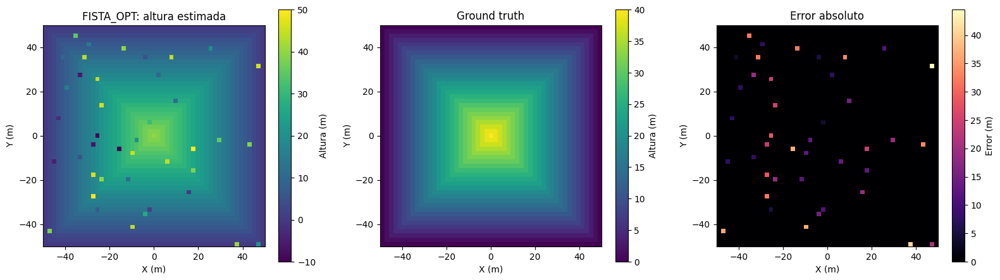


--- ADMM_OPT ---
MAE:  0.277 m
RMSE: 2.730 m
Error máximo absoluto: 44.500 m


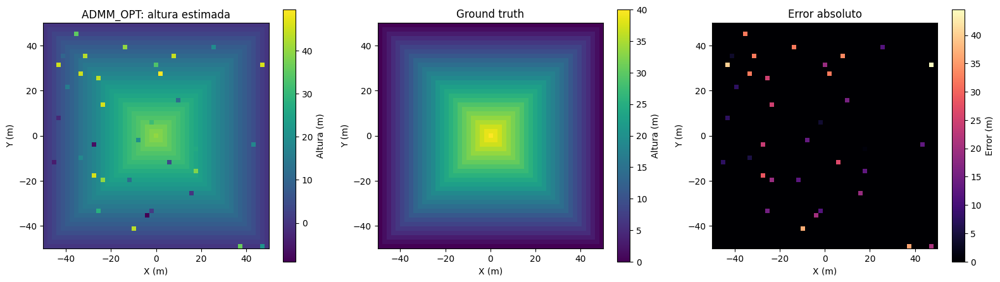

,Método,MAE_m,RMSE_m
0,FISTA optimizado,0.317955,2.911319
1,ADMM optimizado,0.276817,2.730106


In [ ]:

# ============================================================
# RECONSTRUCCIÓN FINAL DE TODA LA ESCENA
# CON LOS PARÁMETROS SELECCIONADOS
# ============================================================

# Vector de observaciones para toda la escena
G_full = G.astype(np.complex128)
b_full = RH @ G_full

# FISTA
gamma_fista_final = ejecutar_fista(
    b_full,
    lambda_fista_opt,
    n_iter=500
)

Z_fista_opt = s[
    np.argmax(np.abs(gamma_fista_final), axis=0)
].reshape(Ny, Nx)

# ADMM
gamma_admm_final = ejecutar_admm(
    b_full,
    lambda_admm_opt,
    rho_admm_opt,
    n_iter=500
)

Z_admm_opt = s[
    np.argmax(np.abs(gamma_admm_final), axis=0)
].reshape(Ny, Nx)

# Evaluar mapas y guardar resultados
evaluar_mapa("FISTA_OPT", Z_fista_opt)
evaluar_mapa("ADMM_OPT", Z_admm_opt)

# Tabla final
filas = []

for nombre, Z_est in {
    "FISTA optimizado": Z_fista_opt,
    "ADMM optimizado": Z_admm_opt
}.items():
    error = Z_est - Z_grid_gt
    filas.append({
        "Método": nombre,
        "MAE_m": np.mean(np.abs(error)),
        "RMSE_m": np.sqrt(np.mean(error**2))
    })

df_final = pd.DataFrame(filas)
display(df_final)

df_final.to_csv(
    salida / "metricas_finales_optimizadas.csv",
    index=False
)

np.savez_compressed(
    salida / "reconstrucciones_optimizadas.npz",
    Z_fista=Z_fista_opt,
    Z_admm=Z_admm_opt,
    lambda_fista=lambda_fista_opt,
    lambda_admm=lambda_admm_opt,
    rho_admm=rho_admm_opt,
    Z_grid_gt=Z_grid_gt
)


# INVERSIÓN CONVENCIONAL EN DATOS REALES (UAVSAR), VARIAS ZONAS

**Objetivo.** Ver cómo lucen los perfiles de reflectividad $\gamma$ reales de UAVSAR (AfriSAR, Lopé, 8 pasadas en banda L) en distintos tipos de terreno. Con eso se puede comprobar que los perfiles sintéticos del equipo se parezcan a la realidad.


**Peso computacional.** Cada transecto necesita solo 5 filas por pasada (unos 2 MB). Las filas que ya se leyeron antes quedan en caché.

In [ ]:
# DATOS REALES UAVSAR: LIBRERÍAS Y PARÁMETROS

import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy.signal import find_peaks
from IPython.display import display


# Datos
UAV_BASE_URL = "https://downloaduav2.jpl.nasa.gov/Release24/lopenp_TM140_03/1"
UAV_TRACKS = ["009", "002", "003", "004", "005", "006", "007", "008"]   # orden del stack (.ann: stackline1 = 009)
UAV_CARPETA = Path("UAVSAR")


# Transectos: píxeles contiguos en range sobre una fila
UAV_TRANSECTOS = [
    dict(nombre="sabana",   fila=4100, col=2000, n=100, motivo="zona oscura de textura suave en el centro de la escena"),
    dict(nombre="bosque_A", fila=6800, col=800,  n=100, motivo="zona clara de textura granulada pareja, abajo a la izquierda"),
    dict(nombre="bosque_B", fila=6400, col=2600, n=100, motivo="zona clara pareja a mitad de la escena (otro ángulo de incidencia)"),
    dict(nombre="borde",    fila=4480, col=940,  n=200, motivo="pasa de bosque (claro) a sabana (oscuro) cerca de la columna 1040"),
    dict(nombre="galeria",  fila=4160, col=2250, n=200, motivo="cruza una franja clara y angosta dentro de la sabana, cerca de la columna 2360"),
    dict(nombre="rio",      fila=2600, col=1450, n=200, motivo="cruza el río (línea muy oscura en las columnas 1520-1560) con bosque en las orillas"),
]

UAV_VENTANA = 5          # ventana multilook (25 looks)


# Eje de alturas y algoritmos
UAV_S = np.arange(-20.0, 60.0 + 0.25, 0.5)   # alturas candidatas [m]
UAV_SIGNO_KZ = +1        # steering a(s) = exp(-j * signo * kz * s)
UAV_CARGA_CAPON = 1e-2   # carga diagonal de Capon, relativa a la potencia media
UAV_ALFA_CS = 0.2        # lambda de CS = UAV_ALFA_CS * lambda_max de cada píxel
UAV_ITER_CS = 600        # iteraciones de FISTA
UAV_N_VERIF_ADMM = 5     # píxeles por transecto en los que se corre ADMM para verificar FISTA
UAV_SNR_MIN = 8.0        # SNR equivalente mínimo [dB] para considerar fiable un píxel
UAV_VENTANA_SUELO = (-10.0, 10.0)   # alturas donde se busca el suelo (los datos están aplanados con un modelo de terreno)

UAV_VISTA_PREVIA = True  # vista general de la escena con los transectos marcados

print(f"{len(UAV_TRANSECTOS)} transectos, {sum(t['n'] for t in UAV_TRANSECTOS)} píxeles en total")
for t in UAV_TRANSECTOS:
    print(f"  {t['nombre']:8s}: fila {t['fila']}, columnas {t['col']} a {t['col'] + t['n'] - 1}")

6 transectos, 900 píxeles en total
  sabana  : fila 4100, columnas 2000 a 2099
  bosque_A: fila 6800, columnas 800 a 899
  bosque_B: fila 6400, columnas 2600 a 2699
  borde   : fila 4480, columnas 940 a 1139
  galeria : fila 4160, columnas 2250 a 2449
  rio     : fila 2600, columnas 1450 a 1649


In [ ]:
# LECTURA PARCIAL DE ARCHIVOS UAVSAR

# Los archivos .slc y .kz son matrices guardadas fila por fila:
#   .slc -> complejo de 8 bytes por píxel (float32 real + float32 imag)
#   .kz  -> real de 4 bytes por píxel (float32)
#
# Orden de prioridad para cada lectura:
#   1. Caché local (UAVSAR/cache_filas/...)
#   2. Archivo completo ya descargado
#   3. Lectura parcial por HTTP (código 206)
#   4. Si el servidor no acepta lecturas parciales (código 200),
#      se descarga el archivo completo una sola vez al disco.

UAV_TIPOS = {"slc": ("_s1_2x8.slc", "<c8", 8), "kz": ("_s1_2x8.kz", "<f4", 4), "ann": (".ann", None, None)}
uav_bytes_descargados = 0


def uav_nombre(track, tipo):
    return f"lopenp_TM140_16008_{track}_160225_L090HH_03_BC{UAV_TIPOS[tipo][0]}"


def uav_ruta_local(track, tipo):
    return UAV_CARPETA / f"track_{track}" / uav_nombre(track, tipo)


def uav_descargar_completo(track, tipo):
    """Descarga un archivo completo al disco, por partes, sin cargarlo en memoria."""
    global uav_bytes_descargados
    ruta = uav_ruta_local(track, tipo)
    if ruta.exists():
        return ruta
    ruta.parent.mkdir(parents=True, exist_ok=True)
    url = f"{UAV_BASE_URL}/{uav_nombre(track, tipo)}"
    print(f"  Descargando completo: {uav_nombre(track, tipo)}")
    with requests.get(url, stream=True, timeout=300) as r:
        r.raise_for_status()
        with open(ruta.with_suffix(ruta.suffix + ".part"), "wb") as f:
            for bloque in r.iter_content(chunk_size=8 * 1024 * 1024):
                f.write(bloque)
                uav_bytes_descargados += len(bloque)
    ruta.with_suffix(ruta.suffix + ".part").rename(ruta)
    return ruta


def uav_leer_ann(track):
    """Lee filas, columnas y longitud de onda del .ann (archivo de texto pequeño)."""
    ruta = uav_descargar_completo(track, "ann")
    texto = ruta.read_text(errors="ignore")
    if "<html" in texto[:2000].lower():
        raise ValueError(f"{ruta} no es un .ann sino una página web (error del servidor o inicio de sesión). "
                         "Bórralo y revisa que la URL abra en el navegador.")
    # En el .ann real las columnas están alineadas con muchos espacios, por eso \s+
    filas = re.search(r"slc_1_2x8\s+Rows\s+\(pixels\)\s*=\s*(\d+)", texto)
    cols = re.search(r"slc_1_2x8\s+Columns\s+\(pixels\)\s*=\s*(\d+)", texto)
    lam = re.search(r"Center\s+Wavelength\s+\(cm\)\s*=\s*([\d.]+)", texto)
    if not (filas and cols):
        raise ValueError(f"No se encontraron las dimensiones del SLC 2x8 en {ruta}. "
                         "Revisa el archivo con: print(open(ruta).read()[:3000])")
    return int(filas.group(1)), int(cols.group(1)), (float(lam.group(1)) / 100 if lam else None)


def uav_leer_filas(track, tipo, fila0, n_filas, n_cols):
    """Devuelve las filas fila0 ... fila0+n_filas-1 de un .slc o .kz como matriz (n_filas, n_cols)."""
    global uav_bytes_descargados
    _, dtype, bpp = UAV_TIPOS[tipo]
    cache = UAV_CARPETA / "cache_filas" / f"{track}_{tipo}_{fila0}_{n_filas}.npy"
    if cache.exists():
        return np.load(cache)

    inicio = fila0 * n_cols * bpp
    fin = (fila0 + n_filas) * n_cols * bpp - 1
    ruta = uav_ruta_local(track, tipo)

    if not ruta.exists():
        url = f"{UAV_BASE_URL}/{uav_nombre(track, tipo)}"
        r = requests.get(url, headers={"Range": f"bytes={inicio}-{fin}"}, stream=True, timeout=120)
        if r.status_code == 206:
            datos = r.content
            uav_bytes_descargados += len(datos)
            r.close()
            filas = np.frombuffer(datos, dtype=dtype).reshape(n_filas, n_cols).copy()
            cache.parent.mkdir(parents=True, exist_ok=True)
            np.save(cache, filas)
            return filas
        r.close()
        if r.status_code != 200:
            r.raise_for_status()
        print("  El servidor no acepta lecturas parciales: se descarga el archivo completo una vez.")
        uav_descargar_completo(track, tipo)

    mapa = np.memmap(ruta, dtype=dtype, mode="r", offset=inicio, shape=(n_filas, n_cols))
    filas = np.array(mapa)
    del mapa
    cache.parent.mkdir(parents=True, exist_ok=True)
    np.save(cache, filas)
    return filas


print("Funciones de lectura listas ✅")

Funciones de lectura listas ✅


In [ ]:
# METADATOS Y LECTURA DE LOS TRANSECTOS


t0 = time.time()
uav_n_filas_img, uav_n_cols_img, uav_lambda = uav_leer_ann(UAV_TRACKS[0])
print(f"Imagen SLC 2x8: {uav_n_filas_img} filas (azimut) x {uav_n_cols_img} columnas (range)")
if uav_lambda:
    print(f"Longitud de onda: {100 * uav_lambda:.2f} cm")

uav_medio = UAV_VENTANA // 2
uav_bloques = {}     # nombre del transecto -> (slc, kz) de las filas necesarias
for t in UAV_TRANSECTOS:
    fila0 = t["fila"] - uav_medio
    assert fila0 >= 0 and fila0 + UAV_VENTANA <= uav_n_filas_img, f"{t['nombre']}: fila demasiado cerca del borde"
    assert t["col"] - uav_medio >= 0 and t["col"] + t["n"] - 1 + uav_medio < uav_n_cols_img, f"{t['nombre']}: columnas fuera de la imagen"
    slc = np.zeros((len(UAV_TRACKS), UAV_VENTANA, uav_n_cols_img), dtype=np.complex64)
    kz = np.zeros((len(UAV_TRACKS), UAV_VENTANA, uav_n_cols_img), dtype=np.float32)
    for i, track in enumerate(UAV_TRACKS):
        slc[i] = uav_leer_filas(track, "slc", fila0, UAV_VENTANA, uav_n_cols_img)
        kz[i] = uav_leer_filas(track, "kz", fila0, UAV_VENTANA, uav_n_cols_img)
    uav_bloques[t["nombre"]] = (slc, kz)
    print(f"  {t['nombre']:8s}: listo")

print(f"\nDatos transferidos en esta ejecución: {uav_bytes_descargados / 1e6:.1f} MB")
print(f"Tiempo de lectura: {time.time() - t0:.1f} s")

  Descargando completo: lopenp_TM140_16008_009_160225_L090HH_03_BC.ann
Imagen SLC 2x8: 8618 filas (azimut) x 4922 columnas (range)
Longitud de onda: 23.84 cm
  sabana  : listo
  bosque_A: listo
  bosque_B: listo
  borde   : listo
  galeria : listo
  rio     : listo

Datos transferidos en esta ejecución: 14.2 MB
Tiempo de lectura: 6.6 s


Vista previa: 216 filas en 13 s


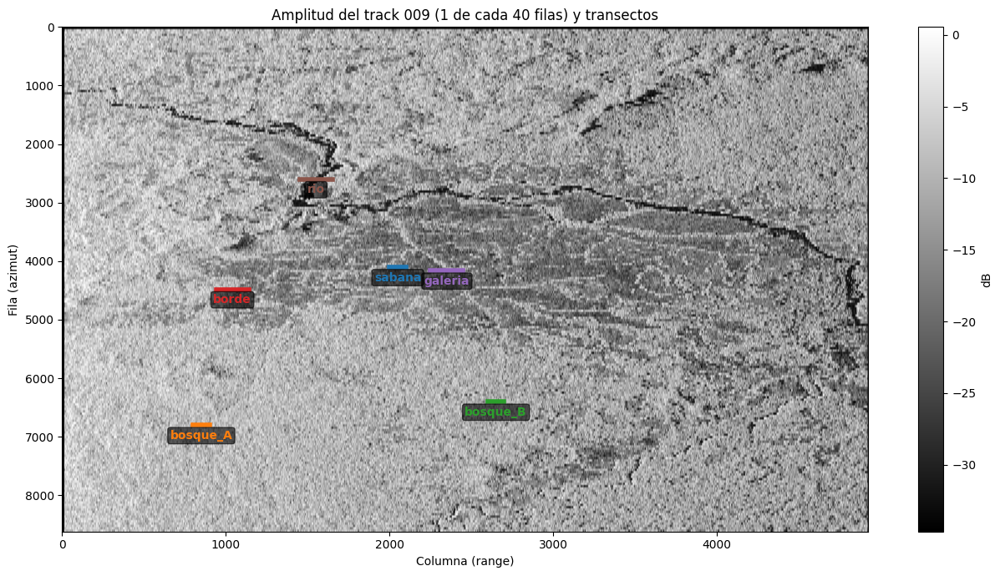

In [ ]:
# VISTA PREVIA DE LA ESCENA CON LOS TRANSECTOS


UAV_COLORES = dict(zip([t["nombre"] for t in UAV_TRANSECTOS], plt.cm.tab10.colors))

if UAV_VISTA_PREVIA:
    paso_filas = 40
    filas_vista = np.arange(0, uav_n_filas_img, paso_filas)
    vista = np.zeros((len(filas_vista), uav_n_cols_img), dtype=np.float32)
    t0 = time.time()
    for j, f in enumerate(filas_vista):
        vista[j] = np.abs(uav_leer_filas(UAV_TRACKS[0], "slc", int(f), 1, uav_n_cols_img)[0])
    print(f"Vista previa: {len(filas_vista)} filas en {time.time() - t0:.0f} s")

    vista_db = 20 * np.log10(vista + 1e-6)
    plt.figure(figsize=(13, 7))
    plt.imshow(vista_db, cmap="gray", aspect="auto", extent=[0, uav_n_cols_img, uav_n_filas_img, 0],
               vmin=np.percentile(vista_db, 2), vmax=np.percentile(vista_db, 98))
    for t in UAV_TRANSECTOS:
        c = UAV_COLORES[t["nombre"]]
        plt.plot([t["col"], t["col"] + t["n"] - 1], [t["fila"], t["fila"]], "-", color=c, linewidth=4)
        plt.annotate(t["nombre"], (t["col"] + t["n"] / 2, t["fila"]), xytext=(0, -12), textcoords="offset points",
                     ha="center", color=c, fontsize=10, fontweight="bold",
                     bbox=dict(boxstyle="round,pad=0.2", fc="black", alpha=0.6))
    plt.xlabel("Columna (range)"); plt.ylabel("Fila (azimut)")
    plt.title(f"Amplitud del track {UAV_TRACKS[0]} (1 de cada {paso_filas} filas) y transectos")
    plt.colorbar(label="dB"); plt.tight_layout(); plt.show()

In [ ]:
# MULTILOOK DE CADA PÍXEL
#
# Para cada píxel: G_p (N x K) con sus K = VENTANA^2 vecinos,
# covarianza C_p = G_p G_p^H / K y el kz del píxel central.
# Todos los píxeles de todos los transectos quedan en arreglos
# únicos; uav_transecto dice a qué zona pertenece cada uno.

N_UAV = len(UAV_TRACKS)
K_UAV = UAV_VENTANA ** 2

G_lista, kz_lista, info = [], [], []
for t in UAV_TRANSECTOS:
    slc, kz = uav_bloques[t["nombre"]]
    for c in range(t["col"], t["col"] + t["n"]):
        G_lista.append(slc[:, :, c - uav_medio:c + uav_medio + 1].reshape(N_UAV, K_UAV))
        kz_lista.append(kz[:, uav_medio, c])
        info.append((t["nombre"], t["fila"], c))

uav_G = np.array(G_lista, dtype=np.complex128)                   # (P, N, K)
uav_kz_px = np.array(kz_lista, dtype=float)                       # (P, N)
uav_transecto = np.array([i[0] for i in info])
uav_fila_px = np.array([i[1] for i in info])
uav_col_px = np.array([i[2] for i in info])
P_UAV = len(uav_G)

uav_C = uav_G @ uav_G.conj().transpose(0, 2, 1) / K_UAV           # (P, N, N)
diag = np.sqrt(np.real(np.einsum("pnn->pn", uav_C)))
coh = np.abs(uav_C) / (diag[:, :, None] * diag[:, None, :])
uav_coherencia = (coh.sum(axis=(1, 2)) - N_UAV) / (N_UAV * (N_UAV - 1))
uav_potencia_db = 10 * np.log10(np.real(np.einsum("pnn->p", uav_C)) / N_UAV)

# Autovalores: cuántas "fuentes" de señal hay y nivel de ruido aproximado
uav_autoval = np.linalg.eigvalsh(uav_C)[:, ::-1]                  # de mayor a menor
ruido = np.maximum(uav_autoval[:, N_UAV // 2:].mean(axis=1), 1e-30)   # promedio de la mitad menor de los autovalores
potencia = np.real(np.einsum("pnn->p", uav_C)) / N_UAV
uav_snr_db = 10 * np.log10(np.maximum(potencia - ruido, 1e-30) / ruido)
uav_n_fuentes = np.sum(uav_autoval > 10 * ruido[:, None], axis=1)
uav_ratio_l2_l1 = uav_autoval[:, 1] / uav_autoval[:, 0]

kz_ord = np.sort(uav_kz_px, axis=1)
uav_resolucion = 2 * np.pi / (kz_ord[:, -1] - kz_ord[:, 0])

print(f"Píxeles: {P_UAV} | covarianzas: {uav_C.shape}")
print(f"Resolución en altura: {uav_resolucion.min():.1f} a {uav_resolucion.max():.1f} m")
print(f"\n{'Transecto':10s}{'Potencia':>10s}{'Coherencia':>12s}{'SNR eq.':>9s}{'λ2/λ1':>8s}")
for t in UAV_TRANSECTOS:
    m = uav_transecto == t["nombre"]
    print(f"{t['nombre']:10s}{np.median(uav_potencia_db[m]):>8.1f}dB{np.median(uav_coherencia[m]):>12.2f}"
          f"{np.median(uav_snr_db[m]):>7.1f}dB{np.median(uav_ratio_l2_l1[m]):>8.3f}")

Píxeles: 900 | covarianzas: (900, 8, 8)
Resolución en altura: 11.6 a 24.1 m

Transecto   Potencia  Coherencia  SNR eq.   λ2/λ1
sabana       -17.0dB        0.96   18.0dB   0.014
bosque_A      -6.2dB        0.45    8.5dB   0.428
bosque_B      -9.1dB        0.59   11.6dB   0.277
borde         -8.4dB        0.69   12.1dB   0.237
galeria      -17.4dB        0.95   17.6dB   0.017
rio          -10.3dB        0.69   13.1dB   0.211


In [ ]:
# ALGORITMOS DE INVERSIÓN

# Beamforming
# Capon
# CS (L1)
# ADMM

L_UAV = len(UAV_S)


def uav_steering(kz_px):
    return np.exp(-1j * UAV_SIGNO_KZ * kz_px[:, :, None] * UAV_S[None, None, :])   # (P, N, L)


def uav_soft(z, umbral):
    return np.maximum(1 - umbral / np.maximum(np.abs(z), 1e-12), 0) * z


def uav_fista(A, G, lam, n_iter):
    AH = A.conj().transpose(0, 2, 1)
    paso = (1 / (np.linalg.norm(A, ord=2, axis=(1, 2)) ** 2 / K_UAV))[:, None, None]
    X = np.zeros((A.shape[0], A.shape[2], G.shape[2]), dtype=complex); Y = X.copy(); t = 1.0
    for _ in range(n_iter):
        X_nuevo = uav_soft(Y - paso * (AH @ (A @ Y - G)) / K_UAV, paso * lam[:, None, None])
        t_nuevo = (1 + np.sqrt(1 + 4 * t ** 2)) / 2
        Y = X_nuevo + ((t - 1) / t_nuevo) * (X_nuevo - X)
        X, t = X_nuevo, t_nuevo
    return X


def uav_admm(A, G, lam, n_iter):
    # (rho I + A^H A / K)^-1 v  =  ( v - A^H (rho K I + A A^H)^-1 A v ) / rho   (identidad de Woodbury)
    AH = A.conj().transpose(0, 2, 1)
    AHG = AH @ G / K_UAV
    rho = 0.01 * np.linalg.norm(A, ord=2, axis=(1, 2)) ** 2 / K_UAV
    B = np.linalg.inv(rho[:, None, None] * K_UAV * np.eye(A.shape[1]) + A @ AH)
    Z = np.zeros((A.shape[0], A.shape[2], G.shape[2]), dtype=complex); U = Z.copy()
    for _ in range(n_iter):
        V = AHG + rho[:, None, None] * (Z - U)
        Gam = (V - AH @ (B @ (A @ V))) / rho[:, None, None]
        Z = uav_soft(Gam + U, (lam / rho)[:, None, None])
        U = U + Gam - Z
    return Z


def uav_costo(A, G, Gam, lam):
    return (0.5 / K_UAV * np.sum(np.abs(A @ Gam - G) ** 2, axis=(1, 2))
            + lam * np.sum(np.abs(Gam), axis=(1, 2)))


uav_P_bf = np.zeros((P_UAV, L_UAV)); uav_P_capon = np.zeros((P_UAV, L_UAV)); uav_P_fista = np.zeros((P_UAV, L_UAV))
uav_lambda_px = np.zeros(P_UAV)
tiempos = {"Beamforming": 0.0, "Capon": 0.0, "CS-FISTA": 0.0}
verif = []

for t in UAV_TRANSECTOS:
    idx = np.where(uav_transecto == t["nombre"])[0]
    A = uav_steering(uav_kz_px[idx]); C = uav_C[idx]; G = uav_G[idx]

    t0 = time.time()
    uav_P_bf[idx] = np.real(np.sum(A.conj() * (C @ A), axis=1)) / N_UAV ** 2
    tiempos["Beamforming"] += time.time() - t0

    t0 = time.time()
    pot = np.real(np.einsum("pnn->p", C)) / N_UAV
    C_reg = C + UAV_CARGA_CAPON * pot[:, None, None] * np.eye(N_UAV)
    uav_P_capon[idx] = 1.0 / np.maximum(np.real(np.sum(A.conj() * np.linalg.solve(C_reg, A), axis=1)), 1e-30)
    tiempos["Capon"] += time.time() - t0

    t0 = time.time()
    lam = UAV_ALFA_CS * np.max(np.abs(A.conj().transpose(0, 2, 1) @ G / K_UAV), axis=(1, 2))
    Gam = uav_fista(A, G, lam, UAV_ITER_CS)
    uav_P_fista[idx] = np.mean(np.abs(Gam) ** 2, axis=2)
    uav_lambda_px[idx] = lam
    dt = time.time() - t0
    tiempos["CS-FISTA"] += dt
    print(f"  {t['nombre']:8s}: {len(idx)} píxeles, FISTA en {dt:.1f} s")

    # Verificación con ADMM en unos pocos píxeles del transecto
    sub = np.linspace(0, len(idx) - 1, min(UAV_N_VERIF_ADMM, len(idx))).astype(int)
    Gam_admm = uav_admm(A[sub], G[sub], lam[sub], 1000)
    c_f = uav_costo(A[sub], G[sub], Gam[sub], lam[sub][:, None, None])
    c_a = uav_costo(A[sub], G[sub], Gam_admm, lam[sub][:, None, None])
    verif.extend(np.abs(c_f - c_a) / c_a)

print("\nTiempo de cálculo total:")
for k, v in tiempos.items():
    print(f"  {k:12s}: {v:6.2f} s")
print(f"\nVerificación ADMM ({len(verif)} píxeles): diferencia de costo con FISTA "
      f"mediana {np.median(verif):.1e}, máxima {np.max(verif):.1e}")

  sabana  : 100 píxeles, FISTA en 13.0 s
  bosque_A: 100 píxeles, FISTA en 12.4 s
  bosque_B: 100 píxeles, FISTA en 12.0 s
  borde   : 200 píxeles, FISTA en 27.4 s
  galeria : 200 píxeles, FISTA en 27.9 s
  rio     : 200 píxeles, FISTA en 28.0 s

Tiempo de cálculo total:
  Beamforming :   0.02 s
  Capon       :   0.05 s
  CS-FISTA    : 120.75 s

Verificación ADMM (30 píxeles): diferencia de costo con FISTA mediana 4.5e-05, máxima 3.7e-04


In [ ]:
# DESCRIPTORES DE CADA PERFIL (A PARTIR DE CAPON)
# Para cada píxel se mide sobre el perfil de Capon:
#   altura_suelo : el pico más fuerte entre -10 y +10 m (datos aplanados con un modelo de terreno)
#   altura_copa  : el pico significativo más alto, si está al menos 8 m sobre el suelo
#   copa_suelo   : potencia de la copa / potencia del suelo
#   rh90         : altura sobre el suelo bajo la cual queda el 90 % de la potencia (una medida de la altura de la vegetación)
#   fiable       : SNR equivalente >= UAV_SNR_MIN. No se usa la coherencia porque en bosque es naturalmente más baja, porque la señal viene de toda la altura de la vegetación
# Antes de medir se resta el "piso" de Capon (el nivel mínimo que deja la regularización), para que no cuente como vegetación.


def uav_descriptores(P, s):
    Pn = P / P.max()
    piso = np.percentile(Pn, 20)
    Pl = np.clip(Pn - piso, 0, None)
    # Suelo: el máximo local más fuerte dentro de la ventana de búsqueda del suelo
    en_ventana = np.where((s >= UAV_VENTANA_SUELO[0]) & (s <= UAV_VENTANA_SUELO[1]))[0]
    maximos, _ = find_peaks(np.r_[0, Pl, 0])
    maximos = maximos - 1
    cand = [i for i in maximos if i in set(en_ventana)]
    i_suelo = max(cand, key=lambda i: Pl[i]) if cand else en_ventana[np.argmax(Pl[en_ventana])]
    # Copa: picos significativos al menos 8 m por encima del suelo
    picos, _ = find_peaks(np.r_[0, Pl, 0], height=0.3 * Pl.max(), prominence=0.1 * Pl.max())
    picos = picos - 1
    altos = picos[s[picos] >= s[i_suelo] + 8]
    i_copa = altos[np.argmax(s[altos])] if len(altos) else None
    sobre = s >= s[i_suelo] - 2
    acum = np.cumsum(Pl * sobre); acum /= max(acum[-1], 1e-30)
    rh90 = s[min(np.searchsorted(acum, 0.9), len(s) - 1)] - s[i_suelo]
    return dict(altura_suelo=s[i_suelo],
                altura_copa=s[i_copa] if i_copa is not None else np.nan,
                copa_suelo=Pl[i_copa] / max(Pl[i_suelo], 1e-30) if i_copa is not None else np.nan,
                rh90=rh90)

filas = []
for p in range(P_UAV):
    d = uav_descriptores(uav_P_capon[p], UAV_S)
    filas.append(dict(transecto=uav_transecto[p], fila=uav_fila_px[p], columna=uav_col_px[p],
                      potencia_db=uav_potencia_db[p], coherencia=uav_coherencia[p], snr_eq_db=uav_snr_db[p],
                      n_fuentes=uav_n_fuentes[p], ratio_l2_l1=uav_ratio_l2_l1[p],
                      **d, pico_cs=UAV_S[np.argmax(uav_P_fista[p])],
                      fiable=bool(uav_snr_db[p] >= UAV_SNR_MIN)))
uav_tabla = pd.DataFrame(filas)

uav_resumen = uav_tabla.groupby("transecto", sort=False).agg(
    pixeles=("columna", "size"),
    potencia_db=("potencia_db", "median"),
    coherencia=("coherencia", "median"),
    snr_eq_db=("snr_eq_db", "median"),
    fiables_pct=("fiable", lambda x: 100 * x.mean()),
    con_copa_pct=("altura_copa", lambda x: 100 * x.notna().mean()),
    suelo_min=("altura_suelo", "min"),
    suelo_max=("altura_suelo", "max"),
    copa_mediana=("altura_copa", "median"),
    rh90_mediana=("rh90", "median"),
    copa_suelo_mediana=("copa_suelo", "median"),
).round(2)
display(uav_resumen)

,pixeles,potencia_db,coherencia,snr_eq_db,fiables_pct,con_copa_pct,suelo_min,suelo_max,copa_mediana,rh90_mediana,copa_suelo_mediana
transecto,,,,,,,,,,,
sabana,100,-17.05,0.96,17.99,100.0,0.0,-4.5,4.0,NaN,8.50,NaN
bosque_A,100,-6.16,0.45,8.49,64.0,66.0,-10.0,10.0,23.5,30.75,0.74
bosque_B,100,-9.12,0.59,11.58,92.0,25.0,-10.0,10.0,22.5,26.75,0.81
borde,200,-8.36,0.69,12.12,79.5,18.5,-10.0,10.0,21.5,18.50,1.09
galeria,200,-17.40,0.95,17.59,100.0,0.5,-6.5,6.5,54.0,12.50,0.33
rio,200,-10.33,0.69,13.07,69.0,28.0,-10.0,10.0,51.0,18.50,1.04


In [ ]:
# VERIFICACIÓN DEL SIGNO DE kz

con_volumen = (uav_tabla["ratio_l2_l1"] >= 0.1).values & uav_tabla["fiable"].values
n_veg = int(con_volumen.sum())
Pn = uav_P_capon / uav_P_capon.max(axis=1, keepdims=True)
Pn = np.clip(Pn - np.percentile(Pn, 20, axis=1, keepdims=True), 0, None)
arriba = Pn[:, UAV_S > 10].sum(axis=1)
abajo = Pn[:, UAV_S < -10].sum(axis=1)

print(f"Píxeles fiables con más de una fuente de señal: {n_veg} de {P_UAV}")
if n_veg < 20:
    print("⚠️ Prueba no concluyente: hay pocos píxeles con vegetación.")
else:
    a, b = arriba[con_volumen].mean(), abajo[con_volumen].mean()
    print(f"En esos píxeles, potencia sobre +10 m: {a:.2f} | bajo -10 m: {b:.2f}")
    if b > a:
        print("⚠️ La vegetación aparece bajo el suelo: cambiar UAV_SIGNO_KZ a -1 y volver a ejecutar.")
    else:
        print("✅ La vegetación aparece sobre el suelo: el signo de kz es correcto.")

Píxeles fiables con más de una fuente de señal: 327 de 900
En esos píxeles, potencia sobre +10 m: 10.95 | bajo -10 m: 3.51
✅ La vegetación aparece sobre el suelo: el signo de kz es correcto.


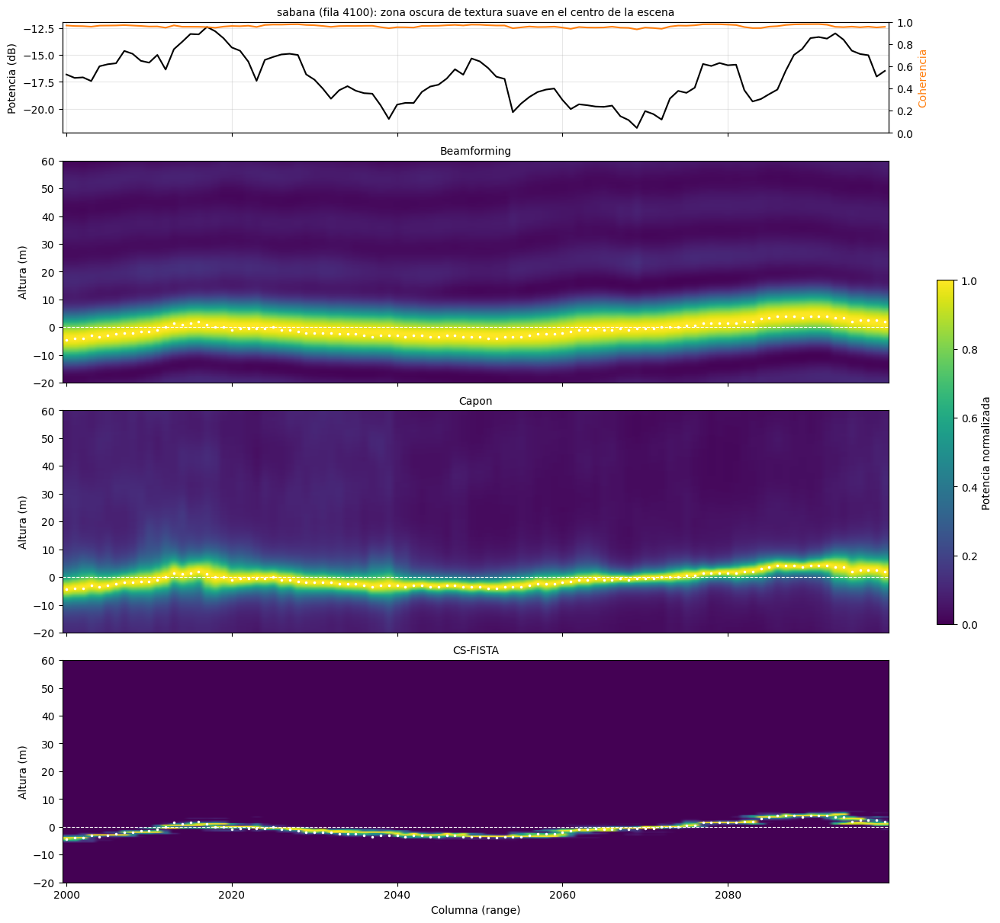

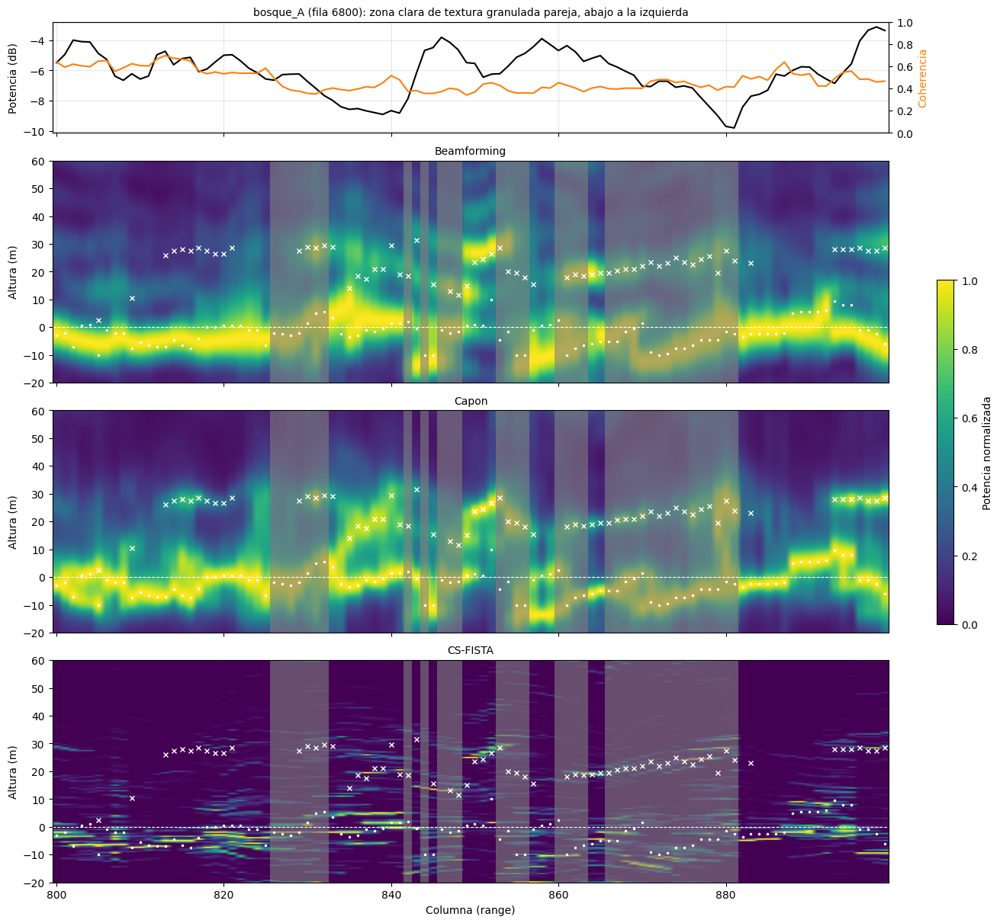

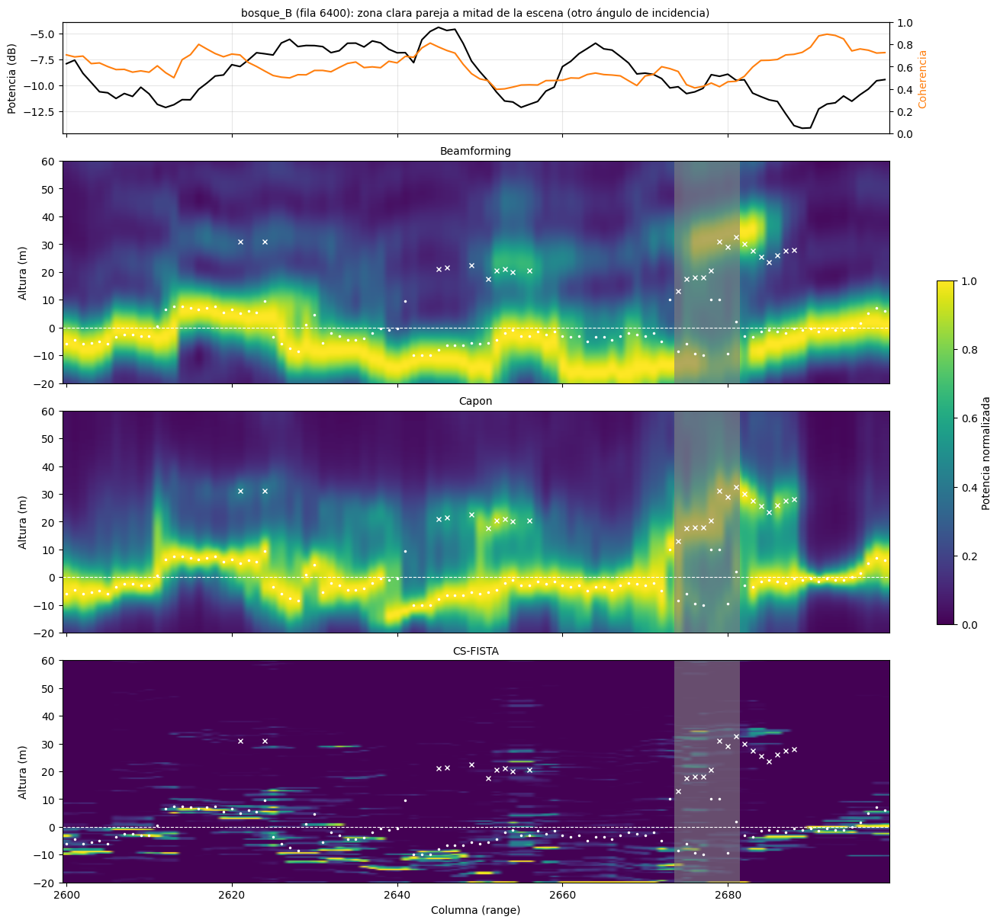

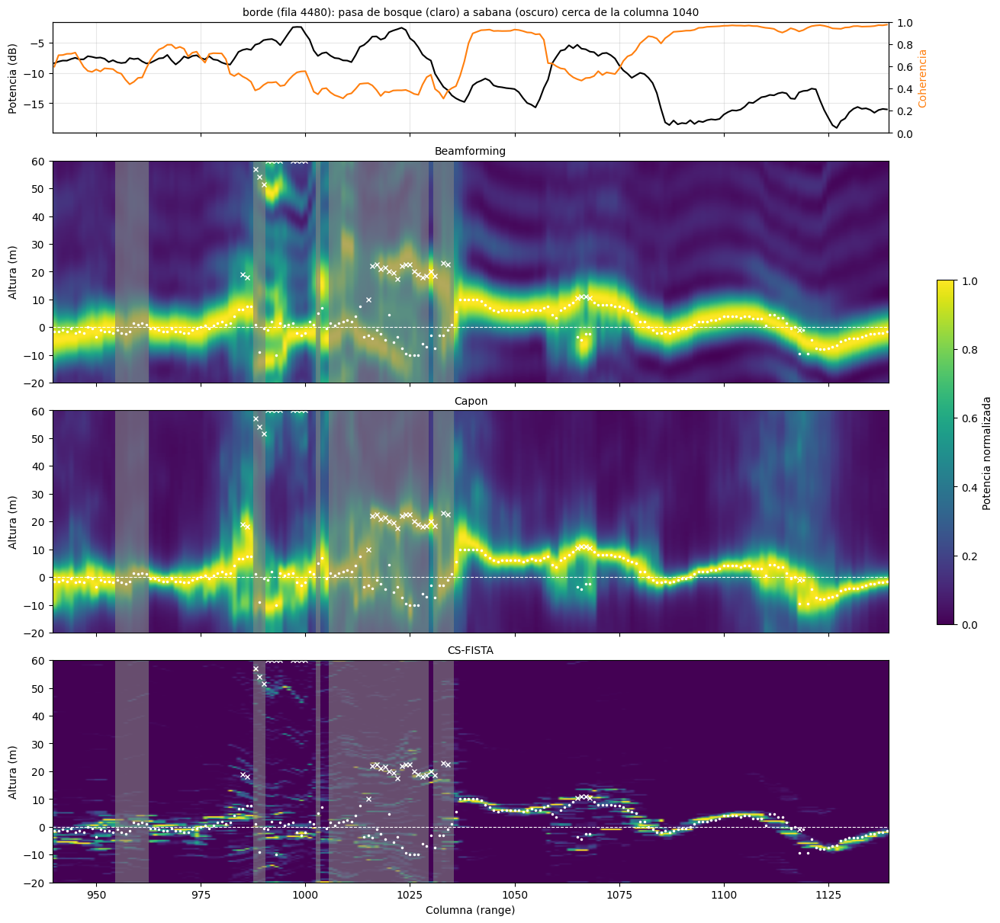

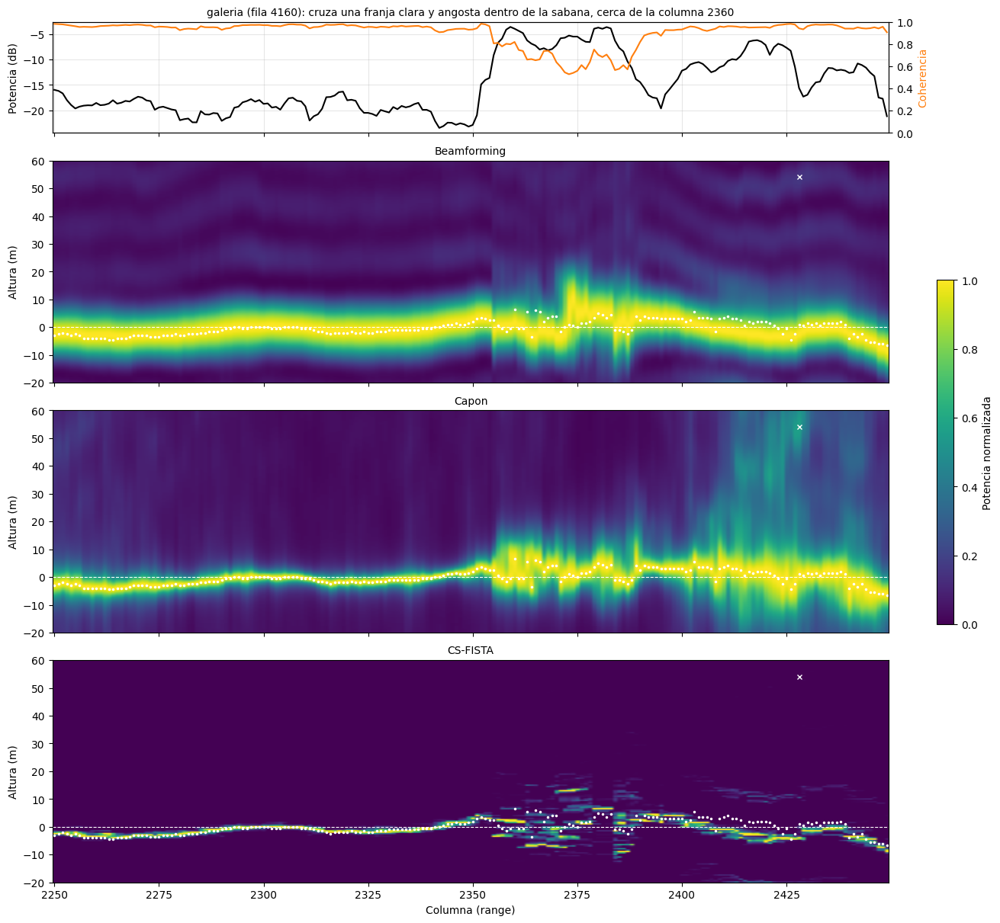

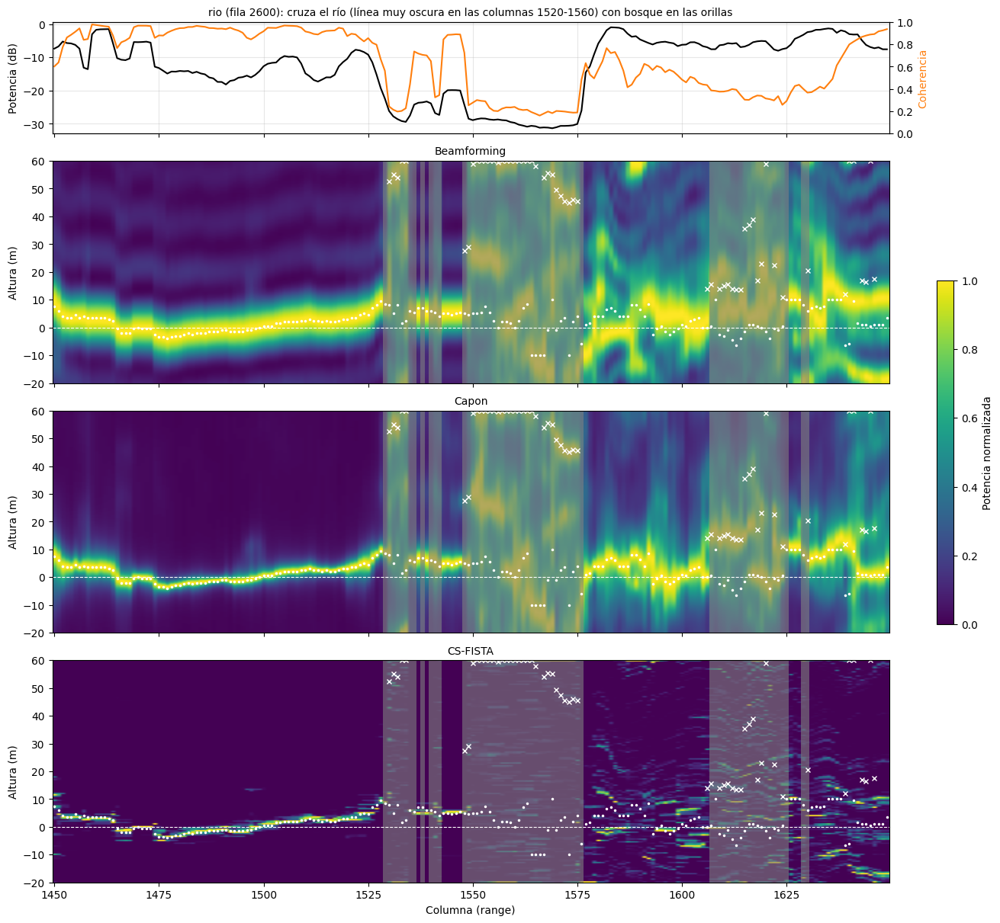

In [ ]:
# TOMOGRAMAS POR TRANSECTO
# Los puntos blancos marcan el suelo y las cruces blancas la copa detectados con Capon; las franjas grises son píxeles poco fiables.

for t in UAV_TRANSECTOS:
    m = uav_transecto == t["nombre"]
    cols = uav_col_px[m]
    tab = uav_tabla[m]
    fig, ax = plt.subplots(4, 1, figsize=(13, 12), sharex=True, constrained_layout=True,
                           gridspec_kw={"height_ratios": [1, 2, 2, 2]})
    ax[0].plot(cols, uav_potencia_db[m], "k-")
    ax[0].set_ylabel("Potencia (dB)"); ax[0].grid(True, alpha=0.3)
    ax2 = ax[0].twinx()
    ax2.plot(cols, uav_coherencia[m], "-", color="tab:orange")
    ax2.set_ylim(0, 1); ax2.set_ylabel("Coherencia", color="tab:orange")
    ax[0].set_title(f"{t['nombre']} (fila {t['fila']}): {t['motivo']}", fontsize=10)
    for a, (nombre, P) in zip(ax[1:], [("Beamforming", uav_P_bf[m]), ("Capon", uav_P_capon[m]), ("CS-FISTA", uav_P_fista[m])]):
        Pn = P / np.maximum(P.max(axis=1, keepdims=True), 1e-30)
        im = a.imshow(Pn.T, origin="lower", aspect="auto", cmap="viridis", vmin=0, vmax=1,
                      extent=[cols[0] - 0.5, cols[-1] + 0.5, UAV_S[0], UAV_S[-1]])
        a.plot(cols, tab["altura_suelo"], "w.", ms=3)
        a.plot(cols, tab["altura_copa"], "wx", ms=4)
        for c_baja in cols[~tab["fiable"].values]:
            a.axvspan(c_baja - 0.5, c_baja + 0.5, color="gray", alpha=0.6, lw=0)
        a.axhline(0, color="w", ls="--", lw=0.8)
        a.set_ylabel("Altura (m)"); a.set_title(nombre, fontsize=10)
    ax[-1].set_xlabel("Columna (range)")
    fig.colorbar(im, ax=list(ax), shrink=0.4, pad=0.01, label="Potencia normalizada")
    plt.show()

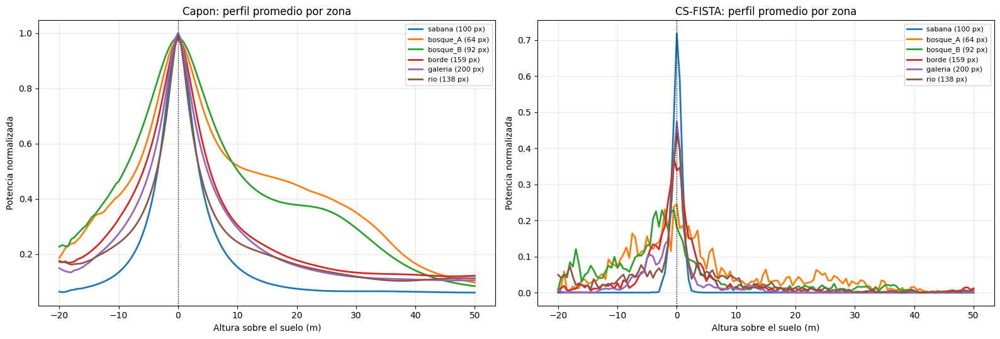

In [ ]:
# PERFIL PROMEDIO DE CADA ZONA

# Para comparar formas, cada perfil se alinea a su propio suelo y se normaliza a 1.
# Solo se usan los píxeles fiables.


s_rel = np.arange(-20, 50.5, 0.5)
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
for nombre_metodo, P_all, a in [("Capon", uav_P_capon, ax[0]), ("CS-FISTA", uav_P_fista, ax[1])]:
    for t in UAV_TRANSECTOS:
        m = (uav_transecto == t["nombre"]) & uav_tabla["fiable"].values
        if m.sum() == 0:
            continue
        alineados = [np.interp(s_rel, UAV_S - h, P / P.max(), left=np.nan, right=np.nan)
                     for P, h in zip(P_all[m], uav_tabla["altura_suelo"].values[m])]
        a.plot(s_rel, np.nanmean(alineados, axis=0), linewidth=2, color=UAV_COLORES[t["nombre"]],
               label=f"{t['nombre']} ({m.sum()} px)")
    a.axvline(0, color="k", ls=":", lw=1)
    a.set_xlabel("Altura sobre el suelo (m)"); a.set_ylabel("Potencia normalizada")
    a.set_title(f"{nombre_metodo}: perfil promedio por zona"); a.grid(True, alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# GUARDADO DE RESULTADOS

uav_salida = UAV_CARPETA / "perfiles_reales_zonas.npz"
np.savez_compressed(
    uav_salida,
    s=UAV_S, transecto=uav_transecto, fila=uav_fila_px, columna=uav_col_px, tracks=np.array(UAV_TRACKS),
    kz=uav_kz_px, G=uav_G.astype(np.complex64), C=uav_C.astype(np.complex64),
    P_beamforming=uav_P_bf, P_capon=uav_P_capon, P_fista=uav_P_fista, lambda_cs=uav_lambda_px,
    coherencia=uav_coherencia, potencia_db=uav_potencia_db, autovalores=uav_autoval,
    alfa_cs=UAV_ALFA_CS, carga_capon=UAV_CARGA_CAPON, signo_kz=UAV_SIGNO_KZ,
)
uav_tabla.to_csv(UAV_CARPETA / "descriptores_por_pixel.csv", index=False)
uav_resumen.to_csv(UAV_CARPETA / "resumen_por_zona.csv")
print(f"Guardado: {uav_salida} ({uav_salida.stat().st_size / 1e6:.1f} MB)")
print(f"Guardado: {UAV_CARPETA / 'descriptores_por_pixel.csv'}")
print(f"Guardado: {UAV_CARPETA / 'resumen_por_zona.csv'}")

Guardado: UAVSAR/perfiles_reales_zonas.npz (3.2 MB)
Guardado: UAVSAR/descriptores_por_pixel.csv
Guardado: UAVSAR/resumen_por_zona.csv


# GENERADOR PARAMÉTRICO DE DATOS SINTÉTICOS TOMOSAR (BANDA L, UAVSAR)

**Para qué sirve.** Genera miles de ejemplos de entrenamiento para el ADMM Unrolling y la Knowledge Distillation. Cada ejemplo es un píxel con:
- **Entrada:** las observaciones $G$ (8 pasadas × 25 looks).
- **Etiqueta:** su perfil de reflectividad verdadero $P(z)$ (potencia vs altura).

**Cómo funciona.**
1. Se arma una escena 3D: relieve, bosque, edificios, agua y formas geométricas.
2. Se proyecta a la geometría del radar, con layover y sombra, para obtener el perfil de cada píxel.
3. Con ese perfil se simulan las mediciones: speckle, ruido térmico, error de fase y decorrelación.

**Geometría.** Banda L con los kz reales de UAVSAR (Lopé), para trabajar a la par con los datos reales.

**Etiquetas usadas en los comentarios del código:**

| Etiqueta | Significado |
|---|---|
| [D] | Calibrado con nuestros datos UAVSAR de Lopé (HH) |
| [R] | Referencia publicada (lista al final) |
| [S] | Supuesto, pendiente de justificar |
| [N] | Elección numérica, no afecta la física |

In [ ]:
# 1. LIBRERÍAS Y GEOMETRÍA DEL SISTEMA

# kz = número de onda vertical de cada pasada: la fase de la pasada n es kz_n * z.
# La matriz del modelo es A[n, l] = exp(-j kz_n z_l)
import json
import time
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, gaussian_filter1d
from scipy.signal import find_peaks

@dataclass
class SintGeometria:
    kz: np.ndarray
    theta_deg: float
    nombre: str = "personalizada"

    @classmethod
    def desde_baselines(cls, wavelength, r_slant, theta_deg, b_n, nombre="baselines"):
        th = np.deg2rad(theta_deg)
        kz = (4 * np.pi / wavelength) * np.asarray(b_n, float) / (r_slant * np.sin(th))
        return cls(kz=kz, theta_deg=theta_deg, nombre=nombre)

    @classmethod
    def desde_kz(cls, kz, theta_deg, nombre="kz"):
        return cls(kz=np.asarray(kz, float), theta_deg=theta_deg, nombre=nombre)

    @property
    def N(self): return len(self.kz)

    @property
    def cot(self): return 1.0 / np.tan(np.deg2rad(self.theta_deg))

    def resolucion(self):
        return 2 * np.pi / (self.kz.max() - self.kz.min())

    def peor_lobulo(self, rango):
        d = np.linspace(0, rango, 4001)
        p = np.abs(np.exp(1j * np.outer(d, self.kz)).sum(1)) / self.N
        m = d > 1.5 * self.resolucion()                  # fuera del lóbulo principal
        return (p[m].max(), d[m][p[m].argmax()]) if m.any() else (np.nan, np.nan)   # nan: resolución mayor que el eje

    def matriz(self, z):
        return np.exp(-1j * np.outer(self.kz, z))

    def subconjunto(self, idx, nombre=None):
        return SintGeometria(self.kz[list(idx)], self.theta_deg, nombre or f"{self.nombre}[{len(idx)}]")


# Geometría por defecto: kz reales de UAVSAR (mediana de 900 píxeles de Lopé)      [D]
SINT_GEO = SintGeometria.desde_kz(
    kz=[-0.1469, -0.1465, -0.0917, -0.0366, 0.0187, 0.0756, 0.1333, 0.1841],
    theta_deg=40.0, nombre="UAVSAR banda L")   # incidencia nominal [S]; en el dataset varía por escena

# Alternativa: geometría usada antes en el notebook (banda X). Pero Los valores físicos de SINT_CONFIG NO valen para banda X.
# SINT_GEO = SintGeometria.desde_baselines(0.03, 10000.0, 35.0, [-45, -32, -21, -8, 0, 13, 27, 46], "equipo (banda X)")

# Eje de alturas de las etiquetas: el mismo del notebook de inversión sobre UAVSAR (-20 a 60 m cada 0,5 m)
SINT_Z_REC = np.arange(-20.0, 60.0 + 1e-9, 0.5)

lob, pos = SINT_GEO.peor_lobulo(SINT_Z_REC[-1] - SINT_Z_REC[0])
print(f"Geometría: {SINT_GEO.nombre} | {SINT_GEO.N} pasadas")
print(f"Resolución en altura: {SINT_GEO.resolucion():.1f} m")
print(f"Peor lóbulo secundario: {lob:.2f} a {pos:.0f} m (cerca de 1 = ambigüedad)")
print(f"Eje de alturas: {SINT_Z_REC[0]:.0f} a {SINT_Z_REC[-1]:.0f} m, {len(SINT_Z_REC)} valores")

Geometría: UAVSAR banda L | 8 pasadas
Resolución en altura: 19.0 m
Peor lóbulo secundario: 0.28 a 40 m (cerca de 1 = ambigüedad)
Eje de alturas: -20 a 60 m, 161 valores


### Modelo físico

Cada celda de la escena (1 m × 1 m) aporta puntos dispersores según lo que contiene:

| Elemento | Mecanismos simulados | Origen de los valores |
|---|---|---|
| Suelo / sabana | Superficie | [D] |
| Agua | Superficie casi especular (devuelve muy poco) | [D] |
| Bosque | Volumen desde el suelo hasta la copa, doble rebote tronco-suelo, suelo atenuado | [D] ajustados; modelo RVoG [R] |
| Edificio | Techo, fachada que mira al radar, doble rebote en su base | Mecanismos [R], valores [S] |
| Pirámide, cono, colina, cresta | Superficie, como el terreno | [D] (como el suelo) |

Efectos geométricos incluidos:
- **Layover [R]:** un punto a altura $z$ aparece en el píxel $y - z\cot\theta$, como en Shen et al. (2024).
- **Sombra:** lo que queda detrás de un edificio o una loma no aporta señal.
- **Aplanado con DEM [R]:** las alturas son relativas al SRTM, como en los productos de UAVSAR. Sobre bosque el SRTM queda dentro del dosel, así que el suelo aparece por debajo de 0 m.

In [ ]:
# 2. CONSTRUCCIÓN DE ESCENAS Y PARÁMETROS (SINT_CONFIG)

# sint_escena_primitivas(cfg, [formas])  -> escena definida a mano (determinista)
# sint_escena_aleatoria(cfg, rng)        -> escena al azar dentro de los rangos de SINT_CONFIG

def sint_campo_suave(shape, escala, rng):
    f = gaussian_filter(rng.standard_normal(shape), escala, mode="wrap")
    return (f - f.mean()) / (f.std() + 1e-12)

def sint_unif(rng, r): return rng.uniform(*r) if isinstance(r, (tuple, list)) else r

# Etiquetas de cada valor:  [D] calibrado con  datos de UAVSAR de Lopé (HH)  [R] referencia publicada
#                           [S] supuesto, pendiente de justificar                 [N] elección numérica
# Los rangos (a, b) se sortean de forma uniforme en cada escena.
SINT_CONFIG = dict(
    # --- Escena ---
    tamano=(64, 160), dx=1.0,                       # celdas (azimut, range) y tamaño de celda [m]             [N]
    # --- Relieve residual (lo que el DEM no captura) ---
    relieve_amplitud=(1.0, 5.0),                    # desviación típica del relieve [m]                         [D] suelo de la sabana: ±4,5 m
    relieve_escala=(10.0, 30.0),                    # ancho de las ondulaciones [m]                             [S]
    pendiente=(0.0, 0.06),                          # inclinación general [m/m]                                 [S]
    # --- Bosque ---
    cobertura_bosque=(0.0, 0.6),                    # fracción de la escena con bosque                          [S]
    parches_escala=(6.0, 15.0),                     # tamaño de los parches [m]                                 [S]
    dosel_altura=(15.0, 50.0),                      # altura media del dosel [m]                                [R] Lopé: 30-50 m
    dosel_variacion=(1.0, 5.0),                     # variación de altura dentro del bosque [m]                 [S]
    extincion=(0.003, 0.03),                        # extinción del modelo RVoG [Np/m]                          [R] modelo, [D] valores
    formas_volumen=("rvog", "uniforme", "copa"),    # reparto vertical del volumen                              [R] rvog, uniforme; [S] copa
    decorrelacion_veg=(0.75, 1.0),                  # coherencia temporal del bosque                            [D] coherencia real: 0,53
    # --- Edificios ---
    n_edificios=(0, 4), edificio_lado=(8.0, 30.0), edificio_altura=(6.0, 40.0),   # cantidad, lado [m], altura [m]   [S]
    # --- Agua y formas sólidas (pirámide, cono, colina, cresta) ---
    prob_rio=0.3, rio_ancho=(4.0, 14.0),                                            # probabilidad, ancho [m]          [S]
    n_estructuras=(0, 1), estructura_tamano=(15.0, 50.0), estructura_altura=(5.0, 25.0),                            # [S]
    # --- DEM de aplanado (UAVSAR usa SRTM de 3", unos 90 m) ---
    dem_suavizado=(25.0, 40.0),                     # sigma del filtro gaussiano [m], equivale a celdas de ~90 m [R]
    dem_sesgo_bosque=(0.0, 0.2),                    # fracción de la altura del bosque que "ve" el DEM          [R] SRTM dentro del dosel; [D] valor
    dem_sesgo_edificios=(0.0, 0.3),                 # ídem para edificios                                       [S]
    # --- Retrodispersión de cada mecanismo [dB], banda L, HH ---
    sigma_suelo_db=(-20.0, -12.0),                  # [D] sabana real: -17 dB
    sigma_agua_db=(-35.0, -28.0),                   # [D] agua real: -29,5 dB o menos (es el piso de ruido)
    sigma_vol_db=(-12.0, -7.0),                     # [D] ajustado: bosque puro de -7,7 dB (real: -6,2 y -9,1 dB)
    sigma_dobleReb_arbol_db=(-11.0, -5.0),          # [D] ajustado: suelo del bosque a -2 m, como en Lopé
    sigma_techo_db=(-15.0, -8.0),                   # [S] pendiente de calibrar
    sigma_fachada_db=(-18.0, -10.0),                # [S] pendiente de calibrar
    sigma_dobleReb_db=(0.0, 10.0),                  # [S] doble rebote de edificios, pendiente de calibrar
    # --- Ruido y geometría de cada escena ---
    piso_ruido_db=(-31.0, -28.0),                   # ruido térmico [dB]                                        [D] agua real: -29,5 dB
    sigma_fase_deg=(0.0, 15.0),                     # error de fase por pasada [grados]                         [S] magnitud supuesta
    kz_escala=(0.8, 1.35),                          # factor sobre los kz (cambian a lo ancho de la imagen)     [D] p5-p95 de los kz reales
    incidencia_deg=(35.0, 50.0),                    # ángulo de incidencia [grados]                             [S] leer de UAVSAR
    # --- Formas fijas que se agregan a todas las escenas aleatorias ---
    primitivas=(),
)

SINT_CLASES = {0: "suelo", 1: "bosque", 2: "edificio", 3: "agua", 4: "estructura"}

def sint_mascara_rect(Xa, Yr, c, largo, ancho, ang):
    ca, sa = np.cos(np.deg2rad(ang)), np.sin(np.deg2rad(ang))
    u = (Xa - c[0]) * ca + (Yr - c[1]) * sa
    v = -(Xa - c[0]) * sa + (Yr - c[1]) * ca
    return (np.abs(u) <= largo / 2) & (np.abs(v) <= ancho / 2)

def sint_altura_solida(Xa, Yr, p):
    """Altura de una forma sólida (pirámide, cono, colina o cresta) sobre el terreno."""
    t = p["tipo"]; c = p.get("centro", (Xa.mean(), Yr.mean()))
    if t == "piramide":
        r = np.maximum(np.abs(Xa - c[0]), np.abs(Yr - c[1])) / (p["lado"] / 2)
        return p["altura"] * np.clip(1 - r, 0, None)
    if t == "cono":
        return p["altura"] * np.clip(1 - np.hypot(Xa - c[0], Yr - c[1]) / p["radio"], 0, None)
    if t == "colina":
        return p["altura"] * np.exp(-0.5 * (np.hypot(Xa - c[0], Yr - c[1]) / p["radio"]) ** 2)
    ang = np.deg2rad(p.get("angulo", 0.0))                       # cresta: loma alargada
    v = -(Xa - c[0]) * np.sin(ang) + (Yr - c[1]) * np.cos(ang)
    return p["altura"] * np.exp(-0.5 * (v / p["ancho"]) ** 2)

def sint_aplicar_primitiva(esc, p):
    """Agrega una forma geométrica a la escena (modifica esc en el lugar)."""
    Xa, Yr = esc["Xa"], esc["Yr"]
    t = p["tipo"]
    c = p.get("centro", (Xa.mean(), Yr.mean()))
    if t in ("piramide", "cono", "colina", "cresta"):
        h = sint_altura_solida(Xa, Yr, p)
        esc["T"] = esc["T"] + h
        esc["clase"][(h > 0.5) & (esc["clase"] == 0)] = 4
    elif t == "edificio":
        m = sint_mascara_rect(Xa, Yr, c, p["largo"], p["ancho"], p.get("angulo", 0.0))
        esc["B"][m] = np.maximum(esc["B"][m], p["altura"])
        esc["H"][m] = 0.0; esc["W"][m] = False; esc["clase"][m] = 2
    elif t == "bosque":
        m = np.hypot(Xa - c[0], Yr - c[1]) <= p["radio"]
        esc["H"][m & (esc["B"] == 0)] = p["altura"]
        esc["clase"][m & (esc["B"] == 0)] = 1
    elif t == "rio":
        m = np.abs(Yr - c[1] - p.get("amplitud", 0.0) * np.sin(2 * np.pi * Xa / p.get("periodo", 80.0))) <= p["ancho"] / 2
        esc["W"][m] = True; esc["H"][m] = 0; esc["B"][m] = 0; esc["clase"][m] = 3
        nivel = np.where(m, esc["T"], np.inf).min(axis=1, keepdims=True)      # el agua queda plana en cada fila
        esc["T"] = np.where(m, np.broadcast_to(nivel, esc["T"].shape), esc["T"])
    else:
        raise ValueError(f"Primitiva desconocida: {t}")

def sint_escena_vacia(cfg):
    Na, Nr = cfg["tamano"]; dx = cfg["dx"]
    xa, yr = np.arange(Na) * dx, np.arange(Nr) * dx
    Xa, Yr = np.meshgrid(xa, yr, indexing="ij")
    z = np.zeros((Na, Nr))
    return dict(Xa=Xa, Yr=Yr, T=z.copy(), B=z.copy(), H=z.copy(), W=np.zeros((Na, Nr), bool),
                clase=np.zeros((Na, Nr), np.int8), dx=dx)

def sint_escena_aleatoria(cfg, rng):
    """Escena con relieve, parches de bosque, edificios y río, con parámetros al azar dentro de los rangos de cfg."""
    esc = sint_escena_vacia(cfg)
    Na, Nr = cfg["tamano"]; Xa, Yr = esc["Xa"], esc["Yr"]
    # Relieve residual suave + pendiente
    esc["T"] = sint_unif(rng, cfg["relieve_amplitud"]) * sint_campo_suave((Na, Nr), sint_unif(rng, cfg["relieve_escala"]) / esc["dx"], rng)
    ang = rng.uniform(0, 2 * np.pi)
    esc["T"] += sint_unif(rng, cfg["pendiente"]) * (np.cos(ang) * Xa + np.sin(ang) * Yr)
    esc["T"] -= esc["T"].mean()
    # Río
    if rng.random() < cfg["prob_rio"]:
        sint_aplicar_primitiva(esc, dict(tipo="rio", centro=(0, rng.uniform(0.2, 0.8) * Nr * esc["dx"]),
                                    ancho=sint_unif(rng, cfg["rio_ancho"]), amplitud=rng.uniform(0, 15), periodo=rng.uniform(60, 200)))
    # Estructuras sólidas al azar (pirámide, cono, colina o cresta), sin cruzar el río
    for _ in range(int(rng.integers(cfg["n_estructuras"][0], cfg["n_estructuras"][1] + 1))):
        for _intento in range(10):
            tam = sint_unif(rng, cfg["estructura_tamano"])
            p = dict(tipo=str(rng.choice(["piramide", "cono", "colina", "cresta"])),
                     centro=(rng.uniform(0, Na * esc["dx"]), rng.uniform(0, Nr * esc["dx"])),
                     lado=tam, radio=tam / 2, ancho=tam / 4, angulo=rng.uniform(0, 180),
                     altura=sint_unif(rng, cfg["estructura_altura"]))
            if not ((sint_altura_solida(Xa, Yr, p) > 0.5) & esc["W"]).any():
                sint_aplicar_primitiva(esc, p)
                break
    # Bosque: parches amorfos (campo suave umbralizado)
    cob = sint_unif(rng, cfg["cobertura_bosque"])
    if cob > 0.02:
        f = sint_campo_suave((Na, Nr), sint_unif(rng, cfg["parches_escala"]) / esc["dx"], rng)
        mask = (f > np.quantile(f, 1 - cob)) & ~esc["W"]
        hmed = sint_unif(rng, cfg["dosel_altura"])
        alt = hmed + sint_unif(rng, cfg["dosel_variacion"]) * sint_campo_suave((Na, Nr), 4.0 / esc["dx"], rng)
        esc["H"][mask] = np.clip(alt[mask], 3.0, None)
        esc["clase"][mask] = 1
    # Edificios: rectángulos sin superponerse con agua
    for _ in range(int(rng.integers(cfg["n_edificios"][0], cfg["n_edificios"][1] + 1))):
        for _intento in range(10):
            lx, ly = sint_unif(rng, cfg["edificio_lado"]), sint_unif(rng, cfg["edificio_lado"])
            c = (rng.uniform(0, Na * esc["dx"]), rng.uniform(0, Nr * esc["dx"]))
            m = sint_mascara_rect(Xa, Yr, c, lx, ly, rng.choice([0.0, rng.uniform(-30, 30)]))
            if m.any() and not esc["W"][m].any():
                sint_aplicar_primitiva(esc, dict(tipo="edificio", centro=c, largo=lx, ancho=ly,
                                            altura=sint_unif(rng, cfg["edificio_altura"])))
                break
    for p in cfg.get("primitivas", ()):
        sint_aplicar_primitiva(esc, p)
    # DEM de referencia usado para aplanar (suave y sesgado por bosque/edificios, como SRTM)
    esc["DEM"] = gaussian_filter(esc["T"] + sint_unif(rng, cfg["dem_sesgo_bosque"]) * esc["H"]
                                 + sint_unif(rng, cfg["dem_sesgo_edificios"]) * esc["B"],
                                 sint_unif(rng, cfg["dem_suavizado"]) / esc["dx"], mode="nearest")
    return esc

def sint_escena_primitivas(cfg, primitivas, dem_suavizado=None):
    """Escena determinista a partir de una lista de formas.

    dem_suavizado=None: sin aplanado (las alturas del perfil son absolutas).
    dem_suavizado=x: se aplana con una versión suavizada (x metros) del terreno, como haría un DEM.
    """
    esc = sint_escena_vacia(cfg)
    for p in primitivas:
        sint_aplicar_primitiva(esc, p)
    esc["DEM"] = (np.zeros_like(esc["T"]) if dem_suavizado is None
                  else gaussian_filter(esc["T"], dem_suavizado / esc["dx"], mode="nearest"))
    return esc


print("Clases:", SINT_CLASES)

Clases: {0: 'suelo', 1: 'bosque', 2: 'edificio', 3: 'agua', 4: 'estructura'}


### Formas disponibles (primitivas)

`centro = (azimut, range)` en metros. Todas las medidas en metros y los ángulos en grados.

| Tipo | Parámetros | Ejemplo |
|---|---|---|
| `piramide` | `lado`, `altura` | `dict(tipo="piramide", centro=(32, 60), lado=40, altura=25)` |
| `cono` | `radio`, `altura` | `dict(tipo="cono", centro=(32, 60), radio=20, altura=25)` |
| `colina` | `radio`, `altura` (gaussiana) | `dict(tipo="colina", centro=(32, 60), radio=15, altura=10)` |
| `cresta` | `ancho`, `altura`, `angulo` | `dict(tipo="cresta", centro=(32, 60), ancho=10, altura=15, angulo=30)` |
| `edificio` | `largo`, `ancho`, `altura`, `angulo` | `dict(tipo="edificio", centro=(32, 60), largo=20, ancho=15, altura=30)` |
| `bosque` | `radio`, `altura` | `dict(tipo="bosque", centro=(32, 60), radio=15, altura=35)` |
| `rio` | `ancho`, `amplitud`, `periodo` | `dict(tipo="rio", centro=(0, 120), ancho=8)` |

In [ ]:
# 3. PROYECCIÓN A PERFILES POR PÍXEL (LAYOVER, SOMBRA Y APLANADO)

# Salida por escena: P_fino (Na, Nr, Lf) potencia vs altura relativa en una grilla fina,
# P_clase (Na, Nr, 5) potencia de cada clase por píxel, y la altura del suelo por píxel.

def sint_db2lin(x): return 10.0 ** (np.asarray(x) / 10.0)

def sint_perfiles(esc, geo, z_fino, cfg, rng, dz_puntos=0.25):
    """Proyecta la escena 3D a perfiles verticales por píxel (potencia vs altura relativa).

    Devuelve P_fino (Na, Nr, Lf), P_clase (Na, Nr, 5) y los parámetros físicos usados.
    """
    T, B, H, W, clase, DEM = esc["T"], esc["B"], esc["H"], esc["W"], esc["clase"], esc["DEM"]
    Na, Nr = T.shape; dx = esc["dx"]; Yr = esc["Yr"]
    cot = geo.cot; cos_t = np.cos(np.deg2rad(geo.theta_deg))
    ia_grid = np.broadcast_to(np.arange(Na)[:, None], (Na, Nr))

    fis = dict(
        sigma_suelo=sint_db2lin(sint_unif(rng, cfg["sigma_suelo_db"])), sigma_agua=sint_db2lin(sint_unif(rng, cfg["sigma_agua_db"])),
        sigma_vol=sint_db2lin(sint_unif(rng, cfg["sigma_vol_db"])), sigma_techo=sint_db2lin(sint_unif(rng, cfg["sigma_techo_db"])),
        sigma_fachada=sint_db2lin(sint_unif(rng, cfg["sigma_fachada_db"])), sigma_db=sint_db2lin(sint_unif(rng, cfg["sigma_dobleReb_db"])),
        sigma_db_arbol=sint_db2lin(sint_unif(rng, cfg["sigma_dobleReb_arbol_db"])), extincion=sint_unif(rng, cfg["extincion"]),
        forma_volumen=rng.choice(cfg["formas_volumen"]),
    )
    kappa = fis["extincion"]
    aten = np.exp(-2 * kappa * H / cos_t)                 # atenuación de ida y vuelta a través del dosel

    # Visibilidad: horizonte de las superficies que tapan (terreno + edificios); el radar está del lado de y pequeño
    Q = T + B + Yr * cot
    Hprev = np.full_like(Q, -np.inf)
    Hprev[:, 1:] = np.maximum.accumulate(Q, axis=1)[:, :-1]

    pts = []   # (ia, y, z, w, clase, es_suelo)
    def agregar(ia, y, z, w, c, suelo):
        vis = z + y * cot >= Hprev[ia, np.minimum((y / dx + 0.5).astype(int), Nr - 1)] - 1e-6
        cc = np.full(vis.sum(), c, np.int8) if np.isscalar(c) else c[vis]
        ss = np.full(vis.sum(), suelo, bool) if np.isscalar(suelo) else suelo[vis]
        pts.append((ia[vis], y[vis], z[vis], w[vis], cc, ss))

    # 1) Superficie: suelo, agua, techos y estructuras sólidas
    sup_w = np.where(B > 0, fis["sigma_techo"], np.where(W, fis["sigma_agua"], fis["sigma_suelo"])) * np.where(B > 0, 1.0, aten)
    agregar(ia_grid.ravel(), Yr.ravel(), (T + B).ravel(), sup_w.ravel(), clase.ravel(), (B == 0).ravel())

    # 2) Bosque: doble rebote tronco-suelo y volumen
    veg = (H > 0) & (B == 0) & ~W
    if veg.any():
        ia_v, ir_v = np.nonzero(veg)
        agregar(ia_v, Yr[veg], T[veg], fis["sigma_db_arbol"] * aten[veg], 1, True)
        kmax = int(np.ceil(H.max() / dz_puntos))
        zeta = (np.arange(kmax) + 0.5) * dz_puntos                       # altura sobre el suelo
        Hv = H[veg][:, None]
        dentro = zeta[None, :] < Hv
        if fis["forma_volumen"] == "rvog":
            f = np.exp(-2 * kappa * (Hv - zeta[None, :]) / cos_t)        # más fuerte arriba (atenuación desde la copa)
        elif fis["forma_volumen"] == "uniforme":
            f = np.ones_like(zeta[None, :] * Hv)
        else:  # "copa": capa de copas cerca del 75 % de la altura + algo de sotobosque
            f = np.exp(-0.5 * ((zeta[None, :] - 0.75 * Hv) / (0.15 * Hv)) ** 2) + 0.15
        f = f * dentro
        f = f / np.maximum(f.sum(1, keepdims=True), 1e-12)
        ia_r = np.repeat(ia_v, kmax).reshape(-1, kmax)[dentro]
        y_r = np.repeat(Yr[veg], kmax).reshape(-1, kmax)[dentro]
        z_r = (T[veg][:, None] + zeta[None, :])[dentro]
        agregar(ia_r, y_r, z_r, (fis["sigma_vol"] * f)[dentro], 1, False)

    # 3) Edificios: fachadas que miran al radar y doble rebote en su base
    sube = np.zeros_like(B, bool); sube[:, 1:] = B[:, 1:] > B[:, :-1]
    if sube.any():
        ia_w, ir_w = np.nonzero(sube)
        y_w = Yr[sube] - dx / 2
        z0 = T[sube] + B[ia_w, ir_w - 1]; z1 = T[sube] + B[sube]
        en_suelo = B[ia_w, ir_w - 1] == 0
        agregar(ia_w[en_suelo], y_w[en_suelo], T[sube][en_suelo], np.full(en_suelo.sum(), fis["sigma_db"]), 2, True)
        kmax = int(np.ceil((z1 - z0).max() / dz_puntos))
        k = (np.arange(kmax) + 0.5) * dz_puntos
        dentro = k[None, :] < (z1 - z0)[:, None]
        z_f = (z0[:, None] + k[None, :])[dentro]
        agregar(np.repeat(ia_w, kmax).reshape(-1, kmax)[dentro], np.repeat(y_w, kmax).reshape(-1, kmax)[dentro],
                z_f, np.full(z_f.size, fis["sigma_fachada"] * dz_puntos), 2, False)

    ia, y, z, w, c, es_suelo = (np.concatenate(v) for v in zip(*pts))

    # 4) Proyección a la geometría SAR aplanada: los puntos altos se corren hacia el radar (layover).
    #    Cada punto se reparte entre los dos píxeles vecinos (interpolación lineal) para evitar patrones de moiré.
    ip0 = np.clip((y / dx + 0.5).astype(int), 0, Nr - 1)
    pos = (y - (z - DEM[ia, ip0]) * cot) / dx
    i0 = np.floor(pos).astype(int); fr = pos - i0
    dz_f = z_fino[1] - z_fino[0]
    P_fino = np.zeros((Na, Nr, len(z_fino)))
    P_clase = np.zeros((Na, Nr, 5))
    suelo_w = np.zeros((Na, Nr)); suelo_wz = np.zeros((Na, Nr))
    fuera_w = 0.0; total_w = 0.0
    for desp, peso in ((0, 1 - fr), (1, fr)):
        ip = i0 + desp
        ok = (ip >= 0) & (ip < Nr) & (peso > 0)
        z_rel = z[ok] - DEM[ia[ok], ip[ok]]
        ib = np.round((z_rel - z_fino[0]) / dz_f).astype(int)
        fuera = (ib < 0) | (ib >= len(z_fino))
        wv = (w * peso)[ok]
        np.add.at(P_fino, (ia[ok][~fuera], ip[ok][~fuera], ib[~fuera]), wv[~fuera])
        np.add.at(P_clase, (ia[ok], ip[ok], c[ok]), wv)
        sg = es_suelo[ok]
        np.add.at(suelo_w, (ia[ok][sg], ip[ok][sg]), wv[sg])
        np.add.at(suelo_wz, (ia[ok][sg], ip[ok][sg]), wv[sg] * z_rel[sg])
        fuera_w += wv[fuera].sum(); total_w += wv.sum()
    fis["fraccion_fuera_eje"] = fuera_w / max(total_w, 1e-30)
    fis["suelo_rel"] = np.where(suelo_w > 0, suelo_wz / np.maximum(suelo_w, 1e-30), np.nan)
    return P_fino, P_clase, fis

In [ ]:
# 4. SIMULACIÓN DE LAS MEDICIONES DEL RADAR

# Looks: g_k ~ CN(0, C), con C = A diag(P) A^H + sigma^2 I   (speckle completamente desarrollado [R])
# Encima: decorrelación temporal del bosque (rho) y error de fase por pasada (C -> D C D^H).
# Beamforming y Capon se incluyen solo como referencia para revisar los datos.

def sint_covarianza(P, geo, z_fino):
    """C = A diag(P) A^H para cada píxel. P: (n, Lf) -> C: (n, N, N)."""
    A = geo.matriz(z_fino)
    return (A[None, :, :] * P[:, None, :]) @ A.conj().T[None, :, :]

def sint_simular(P, geo, z_fino, K, rng, ruido_pot, fase=None, rho=None):
    """Simula K looks por píxel con speckle, ruido térmico, ruido de fase y decorrelación temporal.

    P: (n, Lf) perfiles de potencia en la grilla fina. ruido_pot: potencia de ruido por pasada.
    fase: (N,) error de fase por pasada [rad] (común a la escena). rho: (n,) coherencia temporal.
    Devuelve G (n, N, K) y la covarianza teórica C (n, N, N).
    """
    N = geo.N
    C = sint_covarianza(P, geo, z_fino)
    if rho is not None:                                   # decorrelación temporal: baja los términos fuera de la diagonal
        d = np.einsum("pnn->pn", C)
        C = rho[:, None, None] * C + (1 - rho)[:, None, None] * (d[:, :, None] * np.eye(N)[None])
    C = C + ruido_pot * np.eye(N)[None]
    if fase is not None:                                  # error de fase por pasada (atmósfera, órbita)
        D = np.exp(1j * fase)
        C = D[None, :, None] * C * D.conj()[None, None, :]
    Lc = np.linalg.cholesky(C + 1e-12 * np.real(np.einsum("pnn->p", C))[:, None, None] * np.eye(N)[None])
    Wn = (rng.standard_normal((len(P), N, K)) + 1j * rng.standard_normal((len(P), N, K))) / np.sqrt(2)
    return (Lc @ Wn).astype(np.complex64), C.astype(np.complex64)

def sint_a_grilla(P_fino, z_fino, z_rec):
    """Pasa perfiles de la grilla fina a la grilla de reconstrucción (sumando potencia)."""
    dz = z_rec[1] - z_rec[0]
    ib = np.clip(np.round((z_fino - z_rec[0]) / dz).astype(int), 0, len(z_rec) - 1)
    M = np.zeros((len(z_fino), len(z_rec))); M[np.arange(len(z_fino)), ib] = 1
    return P_fino @ M

def sint_capon(C, A, carga=1e-2):
    N = C.shape[-1]
    pot = np.real(np.einsum("pnn->p", C)) / N
    Cr = C + carga * pot[:, None, None] * np.eye(N)[None]
    return 1.0 / np.maximum(np.real(np.sum(A.conj()[None] * np.linalg.solve(Cr, np.broadcast_to(A, (len(C),) + A.shape)), axis=1)), 1e-30)

def sint_beamforming(C, A):
    return np.real(np.sum(A.conj()[None] * (C @ A[None]), axis=1)) / A.shape[0] ** 2


def sint_capon_kz(C, kz, z, carga=1e-2):
    """Capon cuando cada muestra tiene sus propios kz (agrupa las muestras con los mismos kz)."""
    P = np.zeros((len(C), len(z)))
    claves, inv = np.unique(np.round(kz, 6), axis=0, return_inverse=True)
    inv = np.ravel(inv)
    for i, k in enumerate(claves):
        m = inv == i
        P[m] = sint_capon(C[m], np.exp(-1j * np.outer(k, z)), carga)
    return P

In [ ]:
# 5. GENERACIÓN MASIVA Y FIGURA DE CONTROL

# Por cada escena: geometría propia (kz e incidencia varían) -> perfiles -> muestreo de píxeles
# equilibrado por clase -> mediciones. Se descartan los píxeles del borde lejano (layover incompleto).
#
# Salida: G (n, 8, K) | P (n, L) etiqueta en SINT_Z_REC | kz (n, 8) y theta_deg de cada muestra
#         clase, frac_clase, suelo_rel, rh90, n_picos, snr_db, sigma_fase_deg, rho, escena, fila, columna

def sint_descriptores(P_rec, z_rec, suelo_rel, resolucion):
    """Descriptores de cada perfil etiqueta: número de picos separables y RH90 sobre el suelo."""
    dz = z_rec[1] - z_rec[0]
    from scipy.ndimage import gaussian_filter1d
    Ps = gaussian_filter1d(P_rec, max(resolucion / 2.355 / dz, 0.5), axis=1)
    n_picos = np.zeros(len(P_rec), np.int8); rh90 = np.full(len(P_rec), np.nan)
    for i, p in enumerate(Ps):
        if p.max() <= 0: continue
        pk, _ = find_peaks(np.r_[0, p, 0], prominence=0.1 * p.max())
        n_picos[i] = len(pk)
        if np.isfinite(suelo_rel[i]):
            sobre = z_rec >= suelo_rel[i] - 2
            acum = np.cumsum(P_rec[i] * sobre); acum /= max(acum[-1], 1e-30)
            rh90[i] = z_rec[min(np.searchsorted(acum, 0.9), len(z_rec) - 1)] - suelo_rel[i]
    return n_picos, rh90

def sint_generar_dataset(geo, cfg, n_escenas, pixeles_por_escena, z_rec, K=25, semilla=0, dz_fino=0.25,
                    escena_fn=None, verbose=True):
    """Genera muchos píxeles de entrenamiento: observaciones G (N x K) + perfil etiqueta P (en z_rec).

    escena_fn(cfg, rng) permite usar escenas propias (por defecto, sint_escena_aleatoria).
    """
    rng = np.random.default_rng(semilla)
    escena_fn = escena_fn or sint_escena_aleatoria
    res = geo.resolucion()
    lote = {k: [] for k in ("G", "P", "clase", "frac_clase", "suelo_rel", "snr_db", "escena", "fila", "columna",
                            "sigma_fase_deg", "rho", "kz", "theta_deg")}
    fuera = []
    t0 = time.time()
    geo_base = geo
    for e_id in range(n_escenas):
        # Geometría de la escena: los kz cambian a lo ancho de la imagen (cerca/lejos del radar) y la incidencia también
        geo = SintGeometria(geo_base.kz * sint_unif(rng, cfg["kz_escala"]), sint_unif(rng, cfg["incidencia_deg"]), geo_base.nombre)
        esc = escena_fn(cfg, rng)
        z_fino = np.arange(z_rec[0] - 2, z_rec[-1] + 2, dz_fino) + rng.uniform(0, dz_fino)   # grilla fina desplazada
        P_fino, P_clase, fis = sint_perfiles(esc, geo, z_fino, cfg, rng, dz_puntos=dz_fino)
        fuera.append(fis["fraccion_fuera_eje"])
        Na, Nr, _ = P_fino.shape
        # Margen de range: los píxeles cerca del borde lejano reciben layover de puntos fuera de la escena
        alto = np.nanmax(esc["T"] + esc["B"] + esc["H"] - esc["DEM"])
        margen = int(np.ceil(max(alto, 0) * geo.cot / esc["dx"])) + 2
        validos = np.zeros((Na, Nr), bool); validos[:, : max(Nr - margen, 1)] = True
        validos &= P_fino.sum(-1) > 0
        clase_dom = P_clase.argmax(-1)
        # Muestreo equilibrado por clase dominante
        elegidos = []
        clases_presentes = [c for c in range(5) if (validos & (clase_dom == c)).any()]
        por_clase = max(pixeles_por_escena // max(len(clases_presentes), 1), 1)
        for c in clases_presentes:
            ia, ir = np.nonzero(validos & (clase_dom == c))
            sel = rng.choice(len(ia), min(por_clase, len(ia)), replace=False)
            elegidos += list(zip(ia[sel], ir[sel]))
        if not elegidos: continue
        ia, ir = np.array(elegidos).T
        Psel = P_fino[ia, ir]
        # Ruido térmico absoluto (igual para toda la escena), error de fase por pasada y decorrelación del bosque
        ruido = sint_db2lin(sint_unif(rng, cfg["piso_ruido_db"]))      # piso de ruido térmico absoluto (medido sobre agua en UAVSAR)
        sf = sint_unif(rng, cfg["sigma_fase_deg"])
        fase = np.deg2rad(rng.normal(0, sf, geo.N)) if sf > 0 else None
        frac_veg = P_clase[ia, ir, 1] / np.maximum(P_clase[ia, ir].sum(-1), 1e-30)
        rho = 1 - frac_veg * (1 - sint_unif(rng, cfg["decorrelacion_veg"]))
        G, _ = sint_simular(Psel, geo, z_fino, K, rng, ruido, fase=fase, rho=rho)
        lote["G"].append(G)
        lote["P"].append(sint_a_grilla(Psel, z_fino, z_rec).astype(np.float32))
        lote["clase"].append(clase_dom[ia, ir].astype(np.int8))
        lote["frac_clase"].append((P_clase[ia, ir] / np.maximum(P_clase[ia, ir].sum(-1, keepdims=True), 1e-30)).astype(np.float16))
        lote["suelo_rel"].append(fis["suelo_rel"][ia, ir].astype(np.float32))
        lote["snr_db"].append((10 * np.log10(np.maximum(Psel.sum(-1), 1e-30) / ruido)).astype(np.float32))
        lote["escena"].append(np.full(len(ia), e_id, np.int32)); lote["fila"].append(ia.astype(np.int16)); lote["columna"].append(ir.astype(np.int16))
        lote["sigma_fase_deg"].append(np.full(len(ia), sf, np.float32)); lote["rho"].append(rho.astype(np.float32))
        lote["kz"].append(np.tile(geo.kz.astype(np.float32), (len(ia), 1))); lote["theta_deg"].append(np.full(len(ia), geo.theta_deg, np.float32))
        if verbose and (e_id + 1) % max(n_escenas // 10, 1) == 0:
            print(f"  escena {e_id + 1}/{n_escenas} | píxeles acumulados: {sum(len(x) for x in lote['clase'])} | {time.time() - t0:.1f} s")
    ds = {k: np.concatenate(v) for k, v in lote.items()}
    ds["n_picos"], ds["rh90"] = sint_descriptores(ds["P"], z_rec, ds["suelo_rel"], res)
    ds.update(kz_base=geo_base.kz, z_rec=z_rec, K=K)
    if verbose:
        print(f"  Potencia fuera del eje de alturas: mediana {100 * np.median(fuera):.2f} %, máxima {100 * np.max(fuera):.2f} % por escena")
    return ds


def sint_mostrar_fila(esc, geo, z_rec, fila, cfg, rng, K=25, piso_ruido_db=-29.5, titulo=""):
    """Corte de una fila: escena, etiqueta y lo que verían Beamforming y Capon."""
    z_fino = np.arange(z_rec[0] - 2, z_rec[-1] + 2, 0.25) + rng.uniform(0, 0.25)
    P_fino, P_clase, fis = sint_perfiles(esc, geo, z_fino, cfg, rng)
    Pf = P_fino[fila]
    validos = Pf.sum(-1) > 0
    G, _ = sint_simular(np.where(validos[:, None], Pf, 1e-12), geo, z_fino, K, rng, sint_db2lin(piso_ruido_db))
    Cs = (G @ G.conj().transpose(0, 2, 1) / K).astype(complex)
    A = geo.matriz(z_rec)
    paneles = [("Etiqueta (perfil verdadero)", sint_a_grilla(Pf, z_fino, z_rec)),
               ("Beamforming", sint_beamforming(Cs, A)), ("Capon", sint_capon(Cs, A))]
    y = esc["Yr"][fila]
    fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
    ax[0].fill_between(y, esc["T"][fila], esc["T"][fila] + esc["H"][fila], color="tab:green", alpha=0.4, label="bosque")
    ax[0].fill_between(y, esc["T"][fila], esc["T"][fila] + esc["B"][fila], color="tab:gray", alpha=0.8, label="edificio")
    ax[0].plot(y, esc["T"][fila], "k-", lw=1.5, label="terreno")
    ax[0].plot(y, esc["DEM"][fila], "r--", lw=1, label="DEM")
    agua = esc["W"][fila]
    ax[0].plot(y[agua], esc["T"][fila][agua], "b.", ms=4, label="agua")
    ax[0].set_xlabel("Ground range (m)"); ax[0].set_ylabel("Altura (m)"); ax[0].legend(fontsize=7)
    ax[0].set_title(f"Corte de la escena (fila {fila}), radar a la izquierda", fontsize=10)
    for a, (nombre, M) in zip(ax[1:], paneles):
        Mn = M / np.maximum(M.max(1, keepdims=True), 1e-30)        # cada columna normalizada a 1
        a.imshow(np.sqrt(Mn.T), origin="lower", aspect="auto", cmap="viridis", vmin=0, vmax=1,
                 extent=[y[0], y[-1], z_rec[0], z_rec[-1]])
        a.set_title(nombre, fontsize=10); a.set_xlabel("Píxel en range (m)")
    ax[1].set_ylabel("Altura relativa (m)")
    fig.suptitle(titulo); plt.tight_layout(); plt.show()


print("Generador listo ✅")

Generador listo ✅


## Ejemplo 1: escena definida a mano

Pirámide, edificio, bosque y río sobre una misma fila. Qué mirar en el corte:
- **Edificio:** fachada en diagonal (layover), techo arriba, doble rebote en 0 m y sombra detrás.
- **Bosque:** una cuña, porque el volumen también sufre layover.
- **Río:** casi sin señal; en Beamforming y Capon solo hay ruido.

Con la resolución de UAVSAR (unos 18 m) los detalles se ven borrosos en Beamforming y Capon. Es lo esperable.

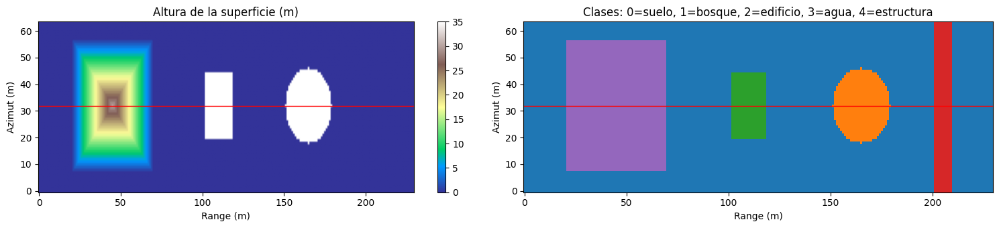

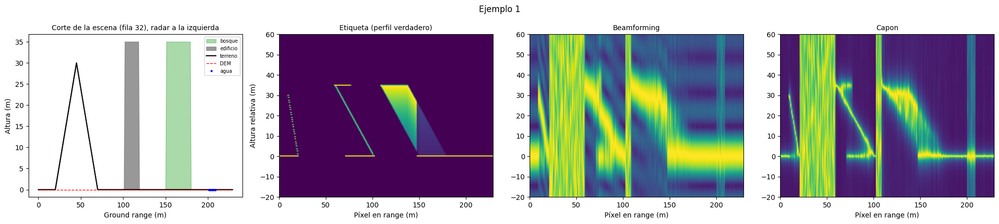

In [ ]:
# EJEMPLO 1: ESCENA POR PRIMITIVAS (editar la lista para probar otras formas)

rng_ej = np.random.default_rng(7)
cfg_ej = dict(SINT_CONFIG, tamano=(64, 230))
primitivas_ej = [
    dict(tipo="piramide", centro=(32, 45), lado=50, altura=30),
    dict(tipo="edificio", centro=(32, 110), largo=24, ancho=16, altura=35),
    dict(tipo="bosque", centro=(32, 165), radio=14, altura=35),
    dict(tipo="rio", centro=(0, 205), ancho=8),
]
esc_ej = sint_escena_primitivas(cfg_ej, primitivas_ej)      # sin aplanado: alturas absolutas

fig, ax = plt.subplots(1, 2, figsize=(15, 3.5))
im = ax[0].imshow(esc_ej["T"] + esc_ej["B"] + esc_ej["H"], origin="lower", cmap="terrain", aspect="auto")
ax[0].set_title("Altura de la superficie (m)"); plt.colorbar(im, ax=ax[0])
ax[1].imshow(esc_ej["clase"], origin="lower", cmap="tab10", vmin=0, vmax=9, aspect="auto", interpolation="nearest")
ax[1].set_title("Clases: " + ", ".join(f"{k}={v}" for k, v in SINT_CLASES.items()))
for a in ax:
    a.axhline(32, color="r", lw=1); a.set_xlabel("Range (m)"); a.set_ylabel("Azimut (m)")
plt.tight_layout(); plt.show()

sint_mostrar_fila(esc_ej, SINT_GEO, SINT_Z_REC, fila=32, cfg=cfg_ej, rng=rng_ej, titulo="Ejemplo 1")

## Ejemplo 2: escenas aleatorias

Cada escena sortea relieve, formas sólidas, parches de bosque, edificios, río y parámetros físicos dentro de `SINT_CONFIG`.

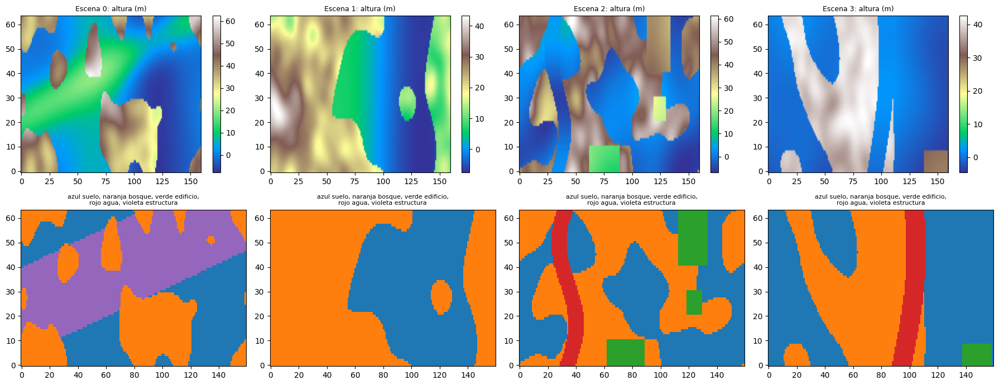

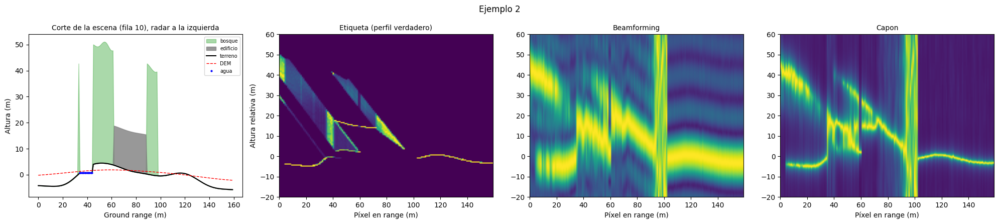

In [ ]:
# EJEMPLO 2: GALERÍA DE ESCENAS ALEATORIAS Y UN CORTE


rng_gal = np.random.default_rng(14)
fig, ax = plt.subplots(2, 4, figsize=(18, 7))
escenas_gal = [sint_escena_aleatoria(SINT_CONFIG, rng_gal) for _ in range(4)]
for j, esc in enumerate(escenas_gal):
    im = ax[0, j].imshow(esc["T"] + esc["B"] + esc["H"], origin="lower", cmap="terrain", aspect="auto")
    plt.colorbar(im, ax=ax[0, j]); ax[0, j].set_title(f"Escena {j}: altura (m)", fontsize=9)
    ax[1, j].imshow(esc["clase"], origin="lower", cmap="tab10", vmin=0, vmax=9, aspect="auto", interpolation="nearest")
    ax[1, j].set_title("azul suelo, naranja bosque, verde edificio,\nrojo agua, violeta estructura", fontsize=8)
plt.tight_layout(); plt.show()

esc = max(escenas_gal, key=lambda e: (e["B"] > 0).sum())
fila = int(np.argmax((esc["B"] > 0).sum(1) - 0.5 * (esc["H"] > 0).sum(1)))
sint_mostrar_fila(esc, SINT_GEO, SINT_Z_REC, fila=fila, cfg=SINT_CONFIG, rng=rng_gal, titulo="Ejemplo 2")

## Generación del dataset

**Cómo modificar lo que se genera.** En la celda siguiente, descomentar o agregar líneas `SINT_CONFIG_DATASET.update(...)`:

| Quiero… | Cambio |
|---|---|
| Más o menos ejemplos | `SINT_N_ESCENAS`, `SINT_PIXELES_POR_ESCENA` |
| Escenas urbanas | `update(cobertura_bosque=(0, 0.1), n_edificios=(3, 8))` |
| Solo bosque | `update(cobertura_bosque=(1, 1), n_edificios=(0, 0), prob_rio=0)` |
| Edificios más altos | `update(edificio_altura=(20, 60))` |
| Datos más ruidosos | `update(piso_ruido_db=(-25, -20), sigma_fase_deg=(5, 25))` |
| Geometría fija (sin variación de kz e incidencia) | `update(kz_escala=(1, 1), incidencia_deg=(40, 40))` |
| Una forma fija en todas las escenas | `update(primitivas=[dict(tipo="piramide", centro=(32, 60), lado=40, altura=25)])` |

Si se cambia el eje de alturas (`SINT_Z_REC`) hay que usar el mismo en el notebook de datos reales y en las redes.

  escena 4/40 | píxeles acumulados: 1994 | 1.3 s
  escena 8/40 | píxeles acumulados: 3988 | 3.7 s
  escena 12/40 | píxeles acumulados: 5988 | 4.7 s
  escena 16/40 | píxeles acumulados: 7984 | 5.5 s
  escena 20/40 | píxeles acumulados: 9821 | 6.7 s
  escena 24/40 | píxeles acumulados: 11681 | 8.0 s
  escena 28/40 | píxeles acumulados: 13409 | 9.7 s
  escena 32/40 | píxeles acumulados: 15161 | 10.6 s
  escena 36/40 | píxeles acumulados: 17046 | 11.4 s
  escena 40/40 | píxeles acumulados: 18926 | 12.1 s
  Potencia fuera del eje de alturas: mediana 0.00 %, máxima 0.00 % por escena

Ejemplos: 18926 en 13.9 s | G: (18926, 8, 25) | P: (18926, 161)


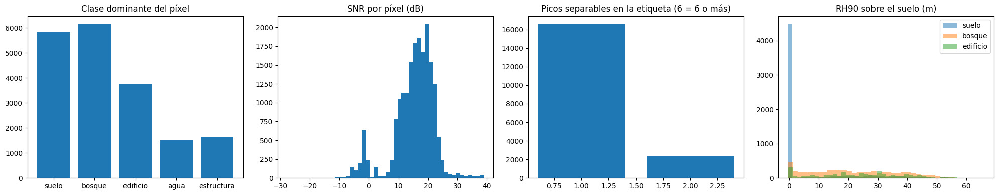


Potencia y SNR medianos por clase (comparar con UAVSAR: sabana -17 dB / 12-14 dB, bosque -6 a -9 dB / 20-23 dB, agua -29,5 dB / ~0 dB)
  suelo       -16.2 dB | SNR  13.6 dB | 5831 píxeles
  bosque      -11.0 dB | SNR  18.6 dB | 6165 píxeles
  edificio     -8.1 dB | SNR  20.8 dB | 3775 píxeles
  agua        -31.8 dB | SNR  -1.6 dB | 1501 píxeles
  estructura  -15.9 dB | SNR  14.0 dB | 1654 píxeles


In [ ]:
# 6. GENERACIÓN MASIVA

SINT_N_ESCENAS = 40
SINT_PIXELES_POR_ESCENA = 500
SINT_K = 25              # looks por píxel: igual a la ventana 5x5 usada con UAVSAR   [D]
SINT_SEMILLA = 2026      # misma semilla = mismo dataset

SINT_CONFIG_DATASET = dict(SINT_CONFIG)
# SINT_CONFIG_DATASET.update(cobertura_bosque=(0, 0.1), n_edificios=(3, 8))     # ejemplo: escenas urbanas

t0 = time.time()
sint_ds = sint_generar_dataset(SINT_GEO, SINT_CONFIG_DATASET, SINT_N_ESCENAS, SINT_PIXELES_POR_ESCENA,
                               SINT_Z_REC, K=SINT_K, semilla=SINT_SEMILLA)
print(f"\nEjemplos: {len(sint_ds['P'])} en {time.time() - t0:.1f} s | G: {sint_ds['G'].shape} | P: {sint_ds['P'].shape}")

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
ax[0].bar([SINT_CLASES[c] for c in range(5)], np.bincount(sint_ds["clase"], minlength=5)); ax[0].set_title("Clase dominante del píxel")
ax[1].hist(sint_ds["snr_db"], bins=50); ax[1].set_title("SNR por píxel (dB)")
ax[2].bar(*np.unique(np.clip(sint_ds["n_picos"], 0, 6), return_counts=True)); ax[2].set_title("Picos separables en la etiqueta (6 = 6 o más)")
for c in (0, 1, 2):
    ax[3].hist(sint_ds["rh90"][sint_ds["clase"] == c], bins=40, alpha=0.5, label=SINT_CLASES[c])
ax[3].set_title("RH90 sobre el suelo (m)"); ax[3].legend()
plt.tight_layout(); plt.show()

print("\nPotencia y SNR medianos por clase (comparar con UAVSAR: sabana -17 dB / 12-14 dB, bosque -6 a -9 dB / 20-23 dB, agua -29,5 dB / ~0 dB)")
pdb = 10 * np.log10(np.maximum(sint_ds["P"].sum(1), 1e-30))
for c in range(5):
    m = sint_ds["clase"] == c
    if m.any():
        print(f"  {SINT_CLASES[c]:10s} {np.median(pdb[m]):6.1f} dB | SNR {np.median(sint_ds['snr_db'][m]):5.1f} dB | {m.sum()} píxeles")

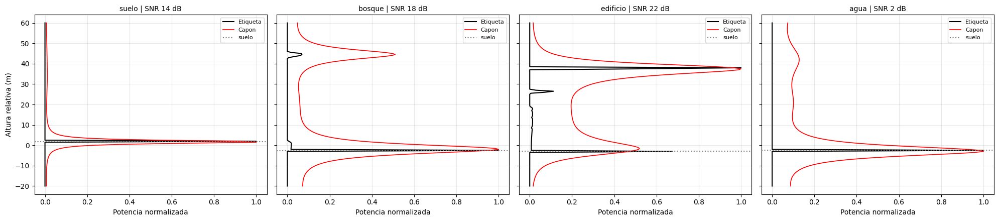

In [ ]:
# 7. PERFILES DE EJEMPLO POR CLASE (etiqueta vs Capon con 25 looks)

rng_pf = np.random.default_rng(0)
criterio = {0: sint_ds["n_picos"] == 1, 1: sint_ds["rh90"] > 15, 2: sint_ds["n_picos"] >= 2,
            3: np.ones(len(sint_ds["P"]), bool)}
fig, ax = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
for a, c in zip(ax, (0, 1, 2, 3)):
    idx = np.nonzero((sint_ds["clase"] == c) & criterio[c])[0]
    if len(idx) == 0:
        a.set_title(f"{SINT_CLASES[c]}: sin ejemplos"); continue
    i = rng_pf.choice(idx)
    G = sint_ds["G"][i].astype(complex)
    Pc = sint_capon_kz((G @ G.conj().T / SINT_K)[None], sint_ds["kz"][i][None], SINT_Z_REC)[0]
    et = sint_ds["P"][i]
    a.plot(et / et.max(), SINT_Z_REC, "k-", lw=1.5, label="Etiqueta")
    a.plot(Pc / Pc.max(), SINT_Z_REC, "r-", lw=1.2, label="Capon")
    if np.isfinite(sint_ds["suelo_rel"][i]):
        a.axhline(sint_ds["suelo_rel"][i], color="gray", ls=":", label="suelo")
    a.set_title(f"{SINT_CLASES[c]} | SNR {sint_ds['snr_db'][i]:.0f} dB", fontsize=10)
    a.set_xlabel("Potencia normalizada"); a.legend(fontsize=8); a.grid(alpha=0.3)
ax[0].set_ylabel("Altura relativa (m)")
plt.tight_layout(); plt.show()

## Validación con datos reales

Con UVSAR, compara el perfil promedio de Capon en bosque, sintético contra real, alineando ambos al suelo de la misma forma.

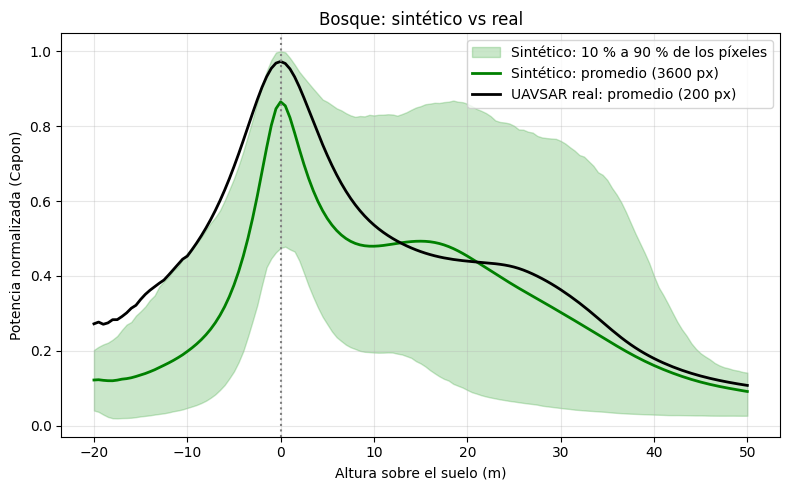

Potencia del bosque: sintético -8.2 dB | real -6.9 dB
   0 m: real 0.97 | sintético 0.86
  10 m: real 0.54 | sintético 0.48
  20 m: real 0.44 | sintético 0.45
  30 m: real 0.36 | sintético 0.30
  40 m: real 0.18 | sintético 0.16


In [ ]:
# ============================================================
# 10. VALIDACIÓN CON PERFILES REALES DE UAVSAR (SI ESTÁ EL ARCHIVO)
# ============================================================

SINT_RUTA_REALES = Path("UAVSAR/perfiles_reales_zonas.npz")


def sint_alinear(P, s, s_rel):
    """Alinea cada perfil a su pico más fuerte entre -10 y +10 m (igual que en el análisis real)."""
    out = []
    for p in P:
        pn = p / p.max(); m = (s >= -10) & (s <= 10)
        out.append(np.interp(s_rel, s - s[m][np.argmax(pn[m])], pn, left=np.nan, right=np.nan))
    return np.array(out)


if SINT_RUTA_REALES.exists():
    real = np.load(SINT_RUTA_REALES)
    bos = np.isin(real["transecto"], ["bosque_A", "bosque_B"])
    cfg_bos = dict(SINT_CONFIG, cobertura_bosque=(1.0, 1.0), n_edificios=(0, 0), prob_rio=0.0, n_estructuras=(0, 0))
    ds_bos = sint_generar_dataset(SINT_GEO, cfg_bos, 12, 300, real["s"], K=25, semilla=5, verbose=False)
    Gb = ds_bos["G"].astype(complex)
    Pc_sint = sint_capon_kz(Gb @ Gb.conj().transpose(0, 2, 1) / 25, ds_bos["kz"], real["s"])
    s_rel = np.arange(-20, 50.5, 0.5)
    al_sint = sint_alinear(Pc_sint, real["s"], s_rel)
    al_real = sint_alinear(real["P_capon"][bos], real["s"], s_rel)

    plt.figure(figsize=(8, 5))
    plt.fill_between(s_rel, np.nanpercentile(al_sint, 10, 0), np.nanpercentile(al_sint, 90, 0),
                     color="tab:green", alpha=0.25, label="Sintético: 10 % a 90 % de los píxeles")
    plt.plot(s_rel, np.nanmean(al_sint, 0), "g-", lw=2, label=f"Sintético: promedio ({len(al_sint)} px)")
    plt.plot(s_rel, np.nanmean(al_real, 0), "k-", lw=2, label=f"UAVSAR real: promedio ({bos.sum()} px)")
    plt.axvline(0, color="gray", ls=":")
    plt.xlabel("Altura sobre el suelo (m)"); plt.ylabel("Potencia normalizada (Capon)")
    plt.title("Bosque: sintético vs real"); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

    pot_sint = np.median(10 * np.log10(ds_bos["P"].sum(1)))
    print(f"Potencia del bosque: sintético {pot_sint:.1f} dB | real {np.median(real['potencia_db'][bos]):.1f} dB")
    for h in (0, 10, 20, 30, 40):
        i = np.argmin(np.abs(s_rel - h))
        print(f"  {h:>2} m: real {np.nanmean(al_real, 0)[i]:.2f} | sintético {np.nanmean(al_sint, 0)[i]:.2f}")
else:
    print(f"No se encontró {SINT_RUTA_REALES}: se omite la validación.")